# Lab Assignment 7 — Multiobjective Optimization
**37 algorithms · trade-offs · applications** &nbsp;|&nbsp; Optimization Techniques Lab · B.Tech CE · Batch B . Roll NO : 241070044


> **In one sentence:** real problems have several goals that fight each other (cheap vs. fast, light vs. stiff), so instead of *one* best answer we compute a *set* of best compromises — the **Pareto front** — and this notebook builds 37 different ways of finding it, from scratch.

### Map of the notebook
| Section | What you get | Look for |
|---|---|---|
| **1–2B** | Aim, rules, schedule | – |
| **3** | Catalogue of all 37 algorithms | one table |
| **4** | The 14 test problems P1–P14 written as *min F(x)* | one table with encoding & constraint handling |
| **Task A1** | Shared tools: dominance, sorting, crowding, HV, IGD, Spacing + unit tests | `moo_utils unit tests passed` |
| **Task A2.1–A2.37** | One cell per algorithm: *docstring (steps) → unit test → run → front plot + metrics* | red dots = found front, black dots = true front |
| **Task A3** | Implementation log (HV, IGD, runtime, status per algorithm) | one big table |
| **Task B** | Master table: advantages / disadvantages / best & worst use, with numbers from your own runs | grouped by family |
| **Task C** | Deep dive on your 3 algorithms: study card, hand trace, sensitivity study | set `ROLL` first |
| **Task D** | Head-to-head: P3 & P5 (all methods), P10 M=5, P8 TSP, plus TOPSIS/VIKOR/MGDA/GradNorm | ranked tables + front plots |
| **Task E** | Which algorithm for which problem, backed by Task D numbers | one table |
| **Task F** | Viva demos (weighted sum vs. dent, VEGA collapse, Deb's rules, elitism) | short printed answers |
| **Export** | The two zip files | download starts automatically |

### Plain-words glossary
| Term | Meaning |
|---|---|
| **Objective** | A quantity to make small (we turn "maximize f" into "minimize −f"). |
| **Dominates** | Solution A dominates B if A is at least as good in every objective and strictly better in one. |
| **Pareto front** | All solutions that nobody dominates — the best possible trade-offs. |
| **Normalization** | Objectives are rescaled to ≈ 0…1 (ideal → 0, nadir → 1) so metrics are comparable across problems. |
| **HV — hypervolume** | Area/volume dominated by your front up to a reference point (1.1 after normalization). **Bigger is better.** |
| **IGD** | Average distance from the *true* front to your nearest point. **Smaller is better** (convergence + spread). Only where the true front is known. |
| **Spacing** | Spread of nearest-neighbour gaps along your front. **Smaller = more evenly spread.** |
| **Budget / seed** | Every algorithm gets the same number of function evaluations; a fixed random seed makes results repeatable. Results are mean ± std over several seeds. |

### Conventions in this notebook
- Every code cell starts with a short comment saying what the section does; there is **no per-line commenting**.
- Algorithms are classes/functions with `initialize → evaluate → step → run`; the docstring lists the lecture steps and default parameters.
- **"unit test passed"** means a small hand-checkable rule of that algorithm was verified (e.g. Deb's rules rank a feasible point above an infeasible one).
- Files written: `results/task_a_log.csv`, `results/task_d_runs.csv` (raw numbers behind the tables).

## 1. Aim and Learning Outcomes
By the end you can: (1) implement all 37 algorithms and explain each step by step; (2) prove their advantages/disadvantages with **your own** plots and numbers; (3) choose an algorithm for a problem from convexity, number of objectives, variable type, constraints, preferences and budget; (4) measure front quality with HV, IGD and Spacing.

## 2. Logistics
| Item | Used here |
|---|---|
| Mode | Individual; roll number decides the 3 deep-dive algorithms (Task C) |
| Language | Python 3.10+ (NumPy, Matplotlib); one language for the whole assignment |
| Reproducibility | Fixed seeds `SEED0 + run`; stochastic algorithms use several independent runs (mean ± std) |
| Fair budget | Same number of function evaluations for every algorithm (`BUDGET`; PDF suggests 10,000 → `FULL = True`) |

### 2A. Coding rules
- Only **NumPy, Matplotlib and the standard library** are used for every algorithm, metric and baseline.
- Allowed exception: `scipy.optimize` / `linprog` solve the single-objective or LP *sub-problem* of algorithms 1–7 (the scalarization, weight/ε sweeps, deviation variables and priority logic are our own code). scikit-learn only **loads** the breast-cancer data for P9.
- Shared tools (dominance, sorting, crowding, HV, IGD, Spacing) live together in the **A1** cell (`moo_utils`) and are unit-tested on the car example and Deb's table.

### 2B. Suggested lab schedule
| Session | Build and test | Algorithms |
|---|---|---|
| 1 | Toolkit, problems P1–P14, classical + ranking methods | 1–9 |
| 2 | Early evolutionary methods and NSGA-II | 10–14 |
| 3 | Archive-based and decomposition methods | 16–20 |
| 4 | Constrained method and first metaheuristics | 21–25 |
| 5 | Remaining metaheuristics | 26–30 |
| 6 | Many-objective, indicator, preference and gradient methods | 15, 31–37 |
| 7 | Comparison experiments, report, viva preparation | Tasks B–F |

In [1]:
# ---- Configuration and imports ----
import os, time, math, itertools, warnings
import numpy as np
import matplotlib
try: get_ipython(); IN_NB = True                     # inside Jupyter/Colab figures are shown inline
except NameError: IN_NB = False
if os.environ.get("QUICK") == "1" and not IN_NB: matplotlib.use("Agg")   # headless smoke-test only
import matplotlib.pyplot as plt
from scipy.optimize import minimize, linprog      # allowed ONLY inside algorithms 1-7
from IPython.display import Markdown, display
warnings.filterwarnings("ignore")

QUICK_TEST = False                                 # True -> ~1-minute dry run (tiny budget, 2 seeds)
QUICK  = QUICK_TEST or os.environ.get("QUICK") == "1"   # smoke-test switch
FULL   = True                                     # True -> 10,000 evals and 10 seeds (slow)
BUDGET = 1200 if QUICK else 5000                   # evaluations per run (2-3 objectives)
BUDGET_MANY = 2500 if QUICK else 10000             # evaluations for many-objective runs (M >= 5)
RUNS   = 2 if QUICK else 5                         # independent runs for mean ± std
if FULL: BUDGET, BUDGET_MANY, RUNS = 10000, 10000, 10
SEED0  = 2026                                      # master seed
PEN    = 10.0                                      # penalty weight on constraint violation
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True})
print(f"BUDGET={BUDGET}, BUDGET_MANY={BUDGET_MANY}, RUNS={RUNS}, SEED0={SEED0}")

BUDGET=10000, BUDGET_MANY=10000, RUNS=10, SEED0=2026


## 3. The Algorithm Catalogue (all 37)
Registry used for the implementation log (A3), the master table (B) and the deep dive (C).

In [2]:
# ---- Catalogue: (number, name, family, test problems) ----
CAT = [
 (1,"Weighted Sum","Classical",["P1","P3","P4"]), (2,"ε-Constraint","Classical",["P2","P3","P5"]),
 (3,"Benson's Method","Classical",["P1","P7"]), (4,"Weight Metric (p-norm, Tchebycheff)","Classical",["P1","P3"]),
 (5,"Value Function","Classical",["P4","P14"]), (6,"Goal Programming","Classical",["P11","P7"]),
 (7,"Lexicographic","Classical",["P11","P7"]), (8,"TOPSIS","Ranking/MCDM",["P12","P4"]),
 (9,"VIKOR","Ranking/MCDM",["P12","P4"]), (10,"VEGA","Non-elitist EA",["P2","P3"]),
 (11,"MOGA","Non-elitist EA",["P3","P5"]), (12,"NSGA","Non-elitist EA",["P5","P7"]),
 (13,"NPGA","Non-elitist EA",["P3","P5"]), (14,"NSGA-II","Elitist EA",["P3","P5","P6"]),
 (15,"NSGA-III","Elitist many-obj",["P10_3","P10_5"]), (16,"SPEA2","Elitist EA",["P4","P5"]),
 (17,"PESA-II","Elitist EA",["P3","P5"]), (18,"MOEA/D","Decomposition",["P3","P10_3"]),
 (19,"MOEA/D-DE","Decomposition",["P3","P5"]), (20,"MOEA/D-ACO","Decomposition",["P8"]),
 (21,"Constrained NSGA-II","Constrained",["P5","P6","P7"]), (22,"MOPSO","Swarm",["P4","P5"]),
 (23,"MOGWO","Swarm",["P5","P9"]), (24,"MOABC","Swarm",["P3","P6"]), (25,"MOACO","Swarm",["P8"]),
 (26,"MOSA","Physics-inspired",["P3","P5"]), (27,"MODE","Evolutionary",["P3","P5"]),
 (28,"MO-TLBO","Human-inspired",["P3","P5"]), (29,"MOBA","Swarm",["P3","P4"]),
 (30,"MOMA","Hybrid",["P5","P9"]), (31,"RVEA","Many-objective",["P10_3","P10_5"]),
 (32,"IBEA","Indicator-based",["P3","P14"]), (33,"SMS-EMOA","Indicator-based",["P3","P14"]),
 (34,"HypE","Indicator-based",["P10_3"]), (35,"R-NSGA-II","Preference-based",["P5","P14"]),
 (36,"MGDA","Gradient-based",["P13"]), (37,"GradNorm","Gradient-based",["P13"])]
NAME = {c[0]: c[1] for c in CAT}; FAMILY = {c[0]: c[2] for c in CAT}; TESTS = {c[0]: c[3] for c in CAT}

def table(rows, cols):
    """Render a markdown table (no pandas needed)."""
    s = "| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n"
    for r in rows: s += "| " + " | ".join(str(v).replace("|", "/") for v in r) + " |\n"
    display(Markdown(s))
table([(c[0], c[1], c[2], ", ".join(c[3])) for c in CAT], ["#", "Algorithm", "Family", "Test problems"])

| # | Algorithm | Family | Test problems |
|---|---|---|---|
| 1 | Weighted Sum | Classical | P1, P3, P4 |
| 2 | ε-Constraint | Classical | P2, P3, P5 |
| 3 | Benson's Method | Classical | P1, P7 |
| 4 | Weight Metric (p-norm, Tchebycheff) | Classical | P1, P3 |
| 5 | Value Function | Classical | P4, P14 |
| 6 | Goal Programming | Classical | P11, P7 |
| 7 | Lexicographic | Classical | P11, P7 |
| 8 | TOPSIS | Ranking/MCDM | P12, P4 |
| 9 | VIKOR | Ranking/MCDM | P12, P4 |
| 10 | VEGA | Non-elitist EA | P2, P3 |
| 11 | MOGA | Non-elitist EA | P3, P5 |
| 12 | NSGA | Non-elitist EA | P5, P7 |
| 13 | NPGA | Non-elitist EA | P3, P5 |
| 14 | NSGA-II | Elitist EA | P3, P5, P6 |
| 15 | NSGA-III | Elitist many-obj | P10_3, P10_5 |
| 16 | SPEA2 | Elitist EA | P4, P5 |
| 17 | PESA-II | Elitist EA | P3, P5 |
| 18 | MOEA/D | Decomposition | P3, P10_3 |
| 19 | MOEA/D-DE | Decomposition | P3, P5 |
| 20 | MOEA/D-ACO | Decomposition | P8 |
| 21 | Constrained NSGA-II | Constrained | P5, P6, P7 |
| 22 | MOPSO | Swarm | P4, P5 |
| 23 | MOGWO | Swarm | P5, P9 |
| 24 | MOABC | Swarm | P3, P6 |
| 25 | MOACO | Swarm | P8 |
| 26 | MOSA | Physics-inspired | P3, P5 |
| 27 | MODE | Evolutionary | P3, P5 |
| 28 | MO-TLBO | Human-inspired | P3, P5 |
| 29 | MOBA | Swarm | P3, P4 |
| 30 | MOMA | Hybrid | P5, P9 |
| 31 | RVEA | Many-objective | P10_3, P10_5 |
| 32 | IBEA | Indicator-based | P3, P14 |
| 33 | SMS-EMOA | Indicator-based | P3, P14 |
| 34 | HypE | Indicator-based | P10_3 |
| 35 | R-NSGA-II | Preference-based | P5, P14 |
| 36 | MGDA | Gradient-based | P13 |
| 37 | GradNorm | Gradient-based | P13 |


## 4. Problem Bank (P1–P14) — formulations
All problems are written as **min F(x) s.t. constraints**; maximizations use Max f ≡ Min −f. Constraint violation CV ≥ 0 is returned by every problem.
Objectives are normalized with ideal/nadir (taken from a dense reference front); HV reference point = 1.1 in normalized space. Termination: fixed evaluation budget.

| P | Standard form | Encoding | Constraint handling | Notes |
|---|---|---|---|---|
| P1 | min (x−3)², (x−7)², x∈[1,10] | real x | bounds | PS = [3,7] |
| P2 | min 100/x, x², x∈[1,10] | real / integer x | bounds | every x Pareto-optimal |
| P3 | ZDT2, n=10 | real in [0,1]¹⁰ | bounds | non-convex front f₂=1−f₁² |
| P4 | min wᵀΣw, −μᵀw, Σw=1 | raw x∈[0,1]⁴, w=x/Σx | **repair by normalization** (always feasible, no penalty tuning) | convex front |
| P5 | min mass, deflection; b·h² ≥ 2.4e-5 | real (b,h) | penalty (and Deb rules in alg. 21) | |
| P6 | Binh–Korn | real (x₁,x₂) | penalty (Deb rules in alg. 21) | 2 nonlinear constraints |
| P7 | max 0.8x₁, 1.2x₂; x₁+x₂≤90 | real | penalty | linear front |
| P8 | bi-objective TSP, 15 cities, seed 7 | permutation | always valid | distance & time |
| P9 | min error(5-NN, 5-fold), #features | 0/1 mask (30) | ≥1 feature (CV=1 otherwise) | 300-sample subset for speed |
| P10 | DTLZ2, M=3 and 5, n=M+9 | real | bounds | true front Σf²=1 |
| P11 | max profit, units; LP constraints | real ≥0 | LP rows | goals / priorities |
| P12 | 5 suppliers × 4 criteria | data table | – | MCDM ranking |
| P13 | (a) toy ‖x−a‖²,‖x−b‖²; (b) 2-head network | real | – | gradients |
| P14 | min weight, max runtime | real (x₁,x₂) | bounds | reference point (1.8 kg, 12 h) |

## 5. Tasks
### Task A — Build all 37 algorithms
#### A1. Shared toolkit (`moo_utils`)

In [3]:
# ---- moo_utils: dominance, sorting, crowding, metrics ----
def dom_matrix(F, CV=None):
    """D[i,j]=True if i dominates j; with CV given, Deb's three feasibility rules are applied."""
    D = (F[:, None, :] <= F[None, :, :]).all(2) & (F[:, None, :] < F[None, :, :]).any(2)
    if CV is not None:
        fe = CV <= 1e-12; a, b = fe[:, None], fe[None, :]
        D = np.where(a & b, D, np.where(a & ~b, True, np.where(~a & b, False, CV[:, None] < CV[None, :])))
    return D

def dominates(a, b): return bool(np.all(a <= b) and np.any(a < b))

def nds(F, CV=None):
    """Fast non-dominated sorting -> list of index arrays (front 0 is the best)."""
    D = dom_matrix(F, CV); cnt = D.sum(0).astype(int); left = np.ones(len(F), bool); fronts = []
    while left.any():
        cur = np.where(left & (cnt == 0))[0]
        if len(cur) == 0: cur = np.where(left)[0]
        fronts.append(cur); left[cur] = False; cnt = cnt - D[cur].sum(0)
    return fronts

def crowding(F):
    """Crowding distance of one front (boundary points get inf)."""
    n, m = F.shape; d = np.zeros(n)
    if n <= 2: return np.full(n, np.inf)
    for j in range(m):
        o = np.argsort(F[:, j]); r = F[o[-1], j] - F[o[0], j]; d[o[0]] = d[o[-1]] = np.inf
        if r > 0: d[o[1:-1]] += (F[o[2:], j] - F[o[:-2], j]) / r
    return d

def cdist(A, B): return np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(2))

def nd2d(F):
    """Non-dominated subset of a 2-objective set (sort + running minimum)."""
    F = F[np.lexsort((F[:, 1], F[:, 0]))]; cm = np.minimum.accumulate(F[:, 1])
    return F[F[:, 1] < np.r_[np.inf, cm[:-1]]]

def hv2d(F, ref):
    """Exact 2-D hypervolume (minimization) by sweeping sorted points."""
    F = F[(F < ref).all(1)]
    if len(F) == 0: return 0.0
    F = F[np.argsort(F[:, 0])]; h = 0.0; best = ref[1]
    for a, b in F:
        if b < best: h += (ref[0] - a) * (best - b); best = b
    return h

def hv_mc(F, ref, n=20000, seed=0):
    """Monte-Carlo hypervolume for 3+ objectives (fixed sampling seed)."""
    F = F[(F < ref).all(1)]
    if len(F) == 0: return 0.0
    lo = F.min(0); S = np.random.default_rng(seed).uniform(lo, ref, (n, len(ref))); cov = np.zeros(n, bool)
    for i in range(0, len(F), 50): cov |= (F[i:i + 50, None, :] <= S[None]).all(2).any(0)
    return cov.mean() * np.prod(ref - lo)

def hv(F, ref): return 0.0 if len(F) == 0 else (hv2d(F, ref) if F.shape[1] == 2 else hv_mc(F, ref))
def igd(PF, F): return np.inf if len(F) == 0 else cdist(PF, F).min(1).mean()
def spacing(F):
    """Std of nearest-neighbour distances (smaller = more even)."""
    if len(F) < 3: return np.nan
    d = cdist(F, F); np.fill_diagonal(d, np.inf); return d.min(1).std()
def thin(F, n=400):
    if len(F) <= n: return F
    F = F[np.argsort(F[:, 0])]; return F[np.linspace(0, len(F) - 1, n).astype(int)]

In [4]:
# ---- Unit tests for moo_utils (hand-checkable) ----
# Car example: (price k$, 0-100 time s) — cheap/slow vs expensive/fast; both minimized
cars = np.array([[20, 12], [30, 8], [25, 10], [35, 9], [28, 11], [40, 6]], float)
fr = nds(cars); assert set(fr[0]) == {0, 1, 2, 5} and set(fr[1]) == {3, 4}       # (35,9) and (28,11) are dominated
assert dominates(np.array([1, 1]), np.array([2, 2])) and not dominates(np.array([1, 3]), np.array([2, 2]))
c = crowding(np.array([[0, 4], [1, 2], [2, 1], [4, 0]], float)); assert np.isinf(c[0]) and np.isinf(c[3]) and abs(c[1] - (2/4 + 3/4)) < 1e-9
assert abs(hv2d(np.array([[1, 3], [2, 2], [3, 1]], float), np.array([4, 4.])) - 6.0) < 1e-9  # staircase area = 6
assert abs(hv_mc(np.array([[0.5, 0.5, 0.5]]), np.ones(3), 40000) - 0.125) < 0.01
# Deb's three rules: feasible beats infeasible; both feasible -> dominance; both infeasible -> smaller CV
Ft = np.array([[5., 5.], [1., 1.], [2., 2.], [9., 9.]]); CVt = np.array([0, 3, 1, 0.])
D = dom_matrix(Ft, CVt)
assert D[0, 1] and not D[1, 0]        # rule 1: feasible > infeasible (even if infeasible has better F)
assert D[0, 3] and not D[3, 0]        # rule 2: both feasible -> usual dominance
assert D[2, 1] and not D[1, 2]        # rule 3: both infeasible -> smaller violation wins
assert abs(igd(np.array([[0, 0], [1, 1.]]), np.array([[0, 0.]])) - np.sqrt(2) / 2) < 1e-9
print("moo_utils unit tests passed")

moo_utils unit tests passed


In [5]:
# ---- Problem class and the 14 problems ----
class Problem:
    """name, n vars, bounds, m objectives, kind in {real,int,bin,perm}; f(X)->(F raw minimized, CV>=0)."""
    def __init__(s, name, n, lb, ub, m, fun, kind="real", g=None, pf=None, ideal=None, nadir=None, pref=None, lin=None):
        s.name, s.n, s.m, s.fun, s.kind, s.g, s.lin, s.pref = name, n, m, fun, kind, g, lin, pref
        s.lb = np.full(n, lb, float) if np.isscalar(lb) else np.array(lb, float)
        s.ub = np.full(n, ub, float) if np.isscalar(ub) else np.array(ub, float)
        s.pf = None if pf is None else thin(pf, 500)
        s.ideal = np.array(ideal if ideal is not None else pf.min(0), float)
        s.nadir = np.array(nadir if nadir is not None else pf.max(0), float)
        s.ref = np.full(m, 1.1); s.pf_n = None if s.pf is None else s.norm(s.pf)
    def f(s, X): return s.fun(np.atleast_2d(X))
    def norm(s, F): return (F - s.ideal) / (s.nadir - s.ideal)
    def denorm(s, Fn): return Fn * (s.nadir - s.ideal) + s.ideal
    def init(s, rng, N):
        if s.kind == "bin": return (rng.random((N, s.n)) < 0.5).astype(float)
        if s.kind == "perm": return np.array([rng.permutation(s.n) for _ in range(N)])
        return s.repair(s.lb + rng.random((N, s.n)) * (s.ub - s.lb))
    def repair(s, X):
        if s.kind == "perm": return X
        if s.kind == "bin":
            X = (X > 0.5).astype(float); z = X.sum(1) == 0; X[z, 0] = 1; return X
        X = np.clip(X, s.lb, s.ub); return np.round(X) if s.kind == "int" else X

Z = lambda X: np.zeros(len(X))
# P1 — factory speed
P1 = Problem("P1", 1, 1, 10, 2, lambda X: (np.c_[(X[:, 0] - 3) ** 2, (X[:, 0] - 7) ** 2], Z(X)),
             pf=(lambda x: np.c_[(x - 3) ** 2, (x - 7) ** 2])(np.linspace(3, 7, 500)[:, None])[:, :, 0] if False else
                np.c_[(np.linspace(3, 7, 500) - 3) ** 2, (np.linspace(3, 7, 500) - 7) ** 2])
# P2 — fleet sizing (real and integer)
_p2 = lambda X: (np.c_[100 / X[:, 0], X[:, 0] ** 2], Z(X))
_p2i = lambda X: _p2(np.round(X))
P2 = Problem("P2", 1, 1, 10, 2, _p2, pf=np.c_[100 / np.linspace(1, 10, 500), np.linspace(1, 10, 500) ** 2])
P2i = Problem("P2i", 1, 1, 10, 2, _p2i, kind="int", pf=np.c_[100 / np.arange(1, 11), np.arange(1, 11) ** 2.], ideal=[10, 1], nadir=[100, 100])
# P3 — ZDT2 (n=10)
def _zdt2(X):
    f1 = X[:, 0]; g = 1 + 9 * X[:, 1:].mean(1); return np.c_[f1, g * (1 - (f1 / g) ** 2)], Z(X)
_t = np.linspace(0, 1, 500); P3 = Problem("P3", 10, 0, 1, 2, _zdt2, pf=np.c_[_t, 1 - _t ** 2])
# P4 — portfolio (repair by normalization)
MU = np.array([.08, .12, .15, .10])
SIG = np.array([[.010, .002, .001, .003], [.002, .040, .006, .004], [.001, .006, .090, .005], [.003, .004, .005, .020]])
def _p4(X):
    s = X.sum(1, keepdims=True); W = np.where(s > 1e-9, X / np.maximum(s, 1e-9), 0.25)
    return np.c_[np.einsum("ij,jk,ik->i", W, SIG, W), -(W @ MU)], Z(X)
_r = np.random.default_rng(0)
_W = np.vstack([_r.dirichlet(np.full(4, a), 100000) for a in (0.2, 1, 4)] + [np.eye(4)])
_pf4 = nd2d(_p4(_W)[0]); P4 = Problem("P4", 4, 0, 1, 2, _p4, pf=_pf4)
# P5 — cantilever beam (stress limit as constraint)
def _p5(X):
    b, h = X[:, 0], X[:, 1]; F = np.c_[7850 * b * h, 4 * 1000 / (200e9 * b * h ** 3)]
    return F, np.maximum(0, (2.4e-5 - b * h ** 2) / 2.4e-5)
_B, _H = np.meshgrid(np.linspace(.01, .1, 500), np.linspace(.02, .2, 500)); _XY = np.c_[_B.ravel(), _H.ravel()]
_F5, _C5 = _p5(_XY); _pf5 = nd2d(_F5[_C5 <= 0])
P5 = Problem("P5", 2, [.01, .02], [.1, .2], 2, _p5, g=lambda x: np.array([(x[0] * x[1] ** 2 - 2.4e-5) * 1e5]), pf=_pf5,
             pref=np.array([20.0, 5e-4]))
# P6 — Binh-Korn
def _p6(X):
    x1, x2 = X[:, 0], X[:, 1]; F = np.c_[4 * x1 ** 2 + 4 * x2 ** 2, (x1 - 5) ** 2 + (x2 - 5) ** 2]
    return F, np.maximum(0, (x1 - 5) ** 2 + x2 ** 2 - 25) + np.maximum(0, 7.7 - (x1 - 8) ** 2 - (x2 + 3) ** 2)
_A, _Bb = np.meshgrid(np.linspace(0, 5, 700), np.linspace(0, 3, 420)); _XY = np.c_[_A.ravel(), _Bb.ravel()]
_F6, _C6 = _p6(_XY); _pf6 = nd2d(_F6[_C6 <= 0])
P6 = Problem("P6", 2, [0, 0], [5, 3], 2, _p6, pf=_pf6,
             g=lambda x: np.array([25 - (x[0] - 5) ** 2 - x[1] ** 2, (x[0] - 8) ** 2 + (x[1] + 3) ** 2 - 7.7]))
# P7 — water allocation (maximize -> minimize negatives)
_p7 = lambda X: (np.c_[-0.8 * X[:, 0], -1.2 * X[:, 1]], np.maximum(0, X.sum(1) - 90) / 90)
_x1 = np.linspace(10, 70, 300); _pf7 = np.c_[-0.8 * _x1, -1.2 * (90 - _x1)]
P7 = Problem("P7", 2, [10, 20], [90, 90], 2, _p7, pf=_pf7, g=lambda x: np.array([90 - x[0] - x[1]]),
             pref=np.array([-40., -50.]), lin=dict(C=np.array([[.8, 0], [0, 1.2]]), A=np.array([[1., 1.]]), b=np.array([90.]), lb=[10, 20], ub=[90, 90]))
# P8 — bi-objective TSP (15 cities, numpy seed 7)
np.random.seed(7)
CITY = np.random.uniform(0, 100, (15, 2)); _U = np.triu(np.random.uniform(0.5, 2.0, (15, 15)), 1); _U = _U + _U.T
DIST = cdist(CITY, CITY); TIME = DIST * _U
def _p8(X):
    X = X.astype(int); nxt = np.roll(X, -1, 1); return np.c_[DIST[X, nxt].sum(1), TIME[X, nxt].sum(1)], Z(X)
def nn_tour(C, s0=0):
    t = [s0]; left = set(range(len(C))) - {s0}
    while left: j = min(left, key=lambda k: C[t[-1], k]); t.append(j); left.remove(j)
    return np.array(t)
def two_opt(C, t):
    t = t.copy(); n = len(t); imp = True
    while imp:
        imp = False
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                a, b, c, d = t[i - 1], t[i], t[j], t[(j + 1) % n]
                if C[a, c] + C[b, d] < C[a, b] + C[c, d] - 1e-12: t[i:j + 1] = t[i:j + 1][::-1].copy(); imp = True
    return t
_rg = np.random.default_rng(1)
def best_tour(C): return min((two_opt(C, _rg.permutation(15)) for _ in range(30)), key=lambda t: C[t, np.roll(t, -1)].sum())
T_D, T_T = best_tour(DIST), best_tour(TIME); _e1, _e2 = _p8(T_D[None])[0][0], _p8(T_T[None])[0][0]
P8 = Problem("P8", 15, 0, 14, 2, _p8, kind="perm", ideal=[_e1[0], _e2[1]], nadir=[_e2[0], _e1[1]])
P8.D, P8.Tm = DIST, TIME
# P9 — feature selection (binary): 5-NN + 5-fold CV coded by hand; data loaded with scikit-learn
from sklearn.datasets import load_breast_cancer
_d = load_breast_cancer(); _rs = np.random.default_rng(3); _ix = _rs.permutation(len(_d.target))[:300]
_Xd = (_d.data[_ix] - _d.data[_ix].mean(0)) / _d.data[_ix].std(0); _yd = _d.target[_ix]
_T9 = ((_Xd[:, None, :] - _Xd[None, :, :]) ** 2).astype(np.float32)          # per-feature squared differences
_fold = np.arange(300) % 5; _same = _fold[:, None] == _fold[None, :]
def knn_cv_error(mask):
    """5-fold CV error of 5-NN restricted to the selected features."""
    Dm = _T9 @ mask.astype(np.float32); Dm[_same] = np.inf                  # neighbours only from other folds
    nb = np.argpartition(Dm, 5, axis=1)[:, :5]; pred = (_yd[nb].sum(1) >= 3).astype(int)
    return 1 - (pred == _yd).mean()
def _p9(X):
    X = (X > 0.5).astype(float); k = X.sum(1); F = np.zeros((len(X), 2)); cv = (k == 0).astype(float)
    for i in range(len(X)): F[i] = (1.0, 0) if k[i] == 0 else (knn_cv_error(X[i]), k[i])
    return F, cv
P9 = Problem("P9", 30, 0, 1, 2, _p9, kind="bin", ideal=[0, 1], nadir=[0.4, 30])
BASE_ERR = knn_cv_error(np.ones(30))
# P10 — DTLZ2
def make_dtlz2(M):
    def fun(X):
        g = ((X[:, M - 1:] - .5) ** 2).sum(1); c, s_ = np.cos(X * np.pi / 2), np.sin(X * np.pi / 2); F = np.empty((len(X), M))
        for m in range(M): F[:, m] = (1 + g) * np.prod(c[:, :M - 1 - m], axis=1) * (s_[:, M - 1 - m] if m > 0 else 1)
        return F, np.zeros(len(X))
    z = np.abs(np.random.default_rng(5).normal(size=(2500, M))); z /= np.linalg.norm(z, axis=1, keepdims=True)
    return Problem(f"P10_{M}", M + 9, 0, 1, M, fun, pf=z, ideal=np.zeros(M), nadir=np.ones(M))
P10_3, P10_5 = make_dtlz2(3), make_dtlz2(5)
# P11 — production planning (max profit, units)
_p11 = lambda X: (np.c_[-(4 * X[:, 0] + 6 * X[:, 1]), -(X[:, 0] + X[:, 1])],
                  np.maximum(0, 2 * X[:, 0] + 3 * X[:, 1] - 1200) / 1200 + np.maximum(0, 4 * X[:, 0] + 2 * X[:, 1] - 1600) / 1600)
P11 = Problem("P11", 2, 0, 600, 2, _p11, ideal=[-2400, -500], nadir=[0, 0], pf=np.array([[-2400., -500.]]) if False else None,
              g=lambda x: np.array([1200 - 2 * x[0] - 3 * x[1], 1600 - 4 * x[0] - 2 * x[1]]),
              lin=dict(C=np.array([[4., 6.], [1., 1.]]), A=np.array([[2., 3.], [4., 2.]]), b=np.array([1200., 1600.]), lb=[0, 0], ub=[600, 600]))
# P12 — supplier selection data (cost min, quality max, delivery min, reliability max)
P12 = dict(names=["S1", "S2", "S3", "S4", "S5"], w=np.array([.3, .3, .2, .2]), benefit=np.array([False, True, False, True]),
           M=np.array([[120, 8, 10, 92], [100, 7, 14, 88], [140, 9, 7, 95], [90, 6, 18, 80], [130, 8, 9, 90]], float))
# P14 — laptop design with a preference
_p14 = lambda X: (np.c_[.4 + .05 * X[:, 0] + .012 * X[:, 1], -(.2 * X[:, 1] / (.5 + .03 * X[:, 0]))], Z(X))
_x2 = np.linspace(40, 90, 300); P14 = Problem("P14", 2, [13, 40], [17, 90], 2, _p14, pf=_p14(np.c_[np.full(300, 13.), _x2])[0],
                                              pref=np.array([1.8, -12.]))
PROBS = {"P1": P1, "P2": P2, "P2i": P2i, "P3": P3, "P4": P4, "P5": P5, "P6": P6, "P7": P7, "P8": P8, "P9": P9,
         "P10_3": P10_3, "P10_5": P10_5, "P11": P11, "P14": P14}

In [6]:
# ---- Sanity checks from the PDF (verified by hand) ----
assert np.allclose(P1.f(np.array([5.]))[0], [[4, 4]]) and np.allclose(P2.f(np.array([2.]))[0], [[50, 4]])
assert np.allclose(P3.f(np.r_[.5, np.zeros(9)])[0], [[.5, .75]])
assert np.allclose(P4.f(np.array([0, 0, 1, 0.]))[0], [[.09, -.15]])
F5, C5 = P5.f(np.array([.01, .05])); assert np.allclose(F5, [[3.925, .016]]) and C5[0] == 0
assert np.allclose(P6.f(np.array([0, 0.]))[0], [[0, 50]]) and np.allclose(P6.f(np.array([5, 3.]))[0], [[136, 4]])
assert np.allclose(P7.f(np.array([10, 80.]))[0], [[-8, -96]]) and np.allclose(P14.f(np.array([13, 40.]))[0][0, 0], 1.53)
assert abs(-P14.f(np.array([13, 40.]))[0][0, 1] - 9.0) < 0.02
assert np.allclose((P10_3.pf ** 2).sum(1), 1)
rr = np.random.default_rng(0); Xr = P5.init(rr, 20000); print("P5 infeasible fraction of random designs: %.2f" % (P5.f(Xr)[1] > 0).mean())
print("P8 cities (seed 7):\n", CITY.round(2).tolist()); print("P9 all-ones baseline CV error: %.3f" % BASE_ERR)
print("All problem sanity checks passed")

P5 infeasible fraction of random designs: 0.03
P8 cities (seed 7):
 [[7.63, 77.99], [43.84, 72.35], [97.8, 53.85], [50.11, 7.21], [26.84, 49.99], [67.92, 80.37], [38.09, 6.59], [28.81, 90.96], [21.34, 45.21], [93.12, 2.49], [60.05, 95.01], [23.03, 54.85], [90.91, 13.32], [52.34, 75.04], [66.9, 46.78]]
P9 all-ones baseline CV error: 0.027
All problem sanity checks passed


#### A2. The 37 implementations — helpers
Each algorithm cell contains: the implementation (docstring lists the lecture steps), a unit test of its key rule, and a fixed-seed run with a front plot and HV / Spacing / IGD (IGD only where the true front is known). Results go to the implementation log (A3).

In [7]:
# ---- Common runner / logging helpers ----
LOG = []
def finalize(p, X):
    """Evaluate a decision set, keep feasible non-dominated points -> normalized objectives."""
    if X is None or len(X) == 0: return np.empty((0, p.m))
    F, CV = p.f(np.asarray(X)); Fn = p.norm(F[CV <= 1e-9])
    if len(Fn) == 0: return Fn
    Fn = Fn[nds(Fn)[0]]; return np.unique(Fn.round(12), axis=0)

def metrics(p, Fn):
    return hv(Fn, p.ref), spacing(Fn), (igd(p.pf_n, Fn) if p.pf_n is not None else np.nan)

def A2(idx, runner, probs=None, unit=None, status="works"):
    """Run the unit test, run the algorithm on its test problems with a fixed seed, plot and log metrics."""
    if unit: unit(); print(f"[{idx}] {NAME[idx]}: unit test passed")
    probs = probs or TESTS[idx]; fig, axs = plt.subplots(1, len(probs), figsize=(4.4 * len(probs), 3.5), squeeze=False)
    for ax, pn in zip(axs[0], probs):
        P = PROBS[pn]; b = BUDGET_MANY if P.m > 2 else BUDGET; t = time.time(); Fn = runner(P, SEED0, b); rt = time.time() - t
        h, sp, ig = metrics(P, Fn); R = P.denorm(Fn) if len(Fn) else Fn
        LOG.append(dict(idx=idx, name=NAME[idx], prob=pn, budget=b, hv=h, sp=sp, igd=ig, rt=rt, status=status, n=len(Fn)))
        if P.pf is not None: ax.plot(P.pf[:, 0], P.pf[:, 1], "k.", ms=2, label="true front")
        if len(R): ax.scatter(R[:, 0], R[:, 1], s=14, c="C3", label=f"{NAME[idx]} ({len(R)})")
        ax.set_title(f"{pn}: HV={h:.3f} IGD={ig:.3f}" if not np.isnan(ig) else f"{pn}: HV={h:.3f}", fontsize=9); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

def cls_runner(cls, **kw):
    """Runner for population-based algorithms (defined later)."""
    return lambda P, seed, b: cls(P, budget=b, seed=seed, **kw).run().result()

#### A2.1 Weighted Sum
Scalarize `w·f` with fixed weights and sweep the weights; one solve per weight. Cannot reach non-convex (dented) front regions.

[1] Weighted Sum: unit test passed


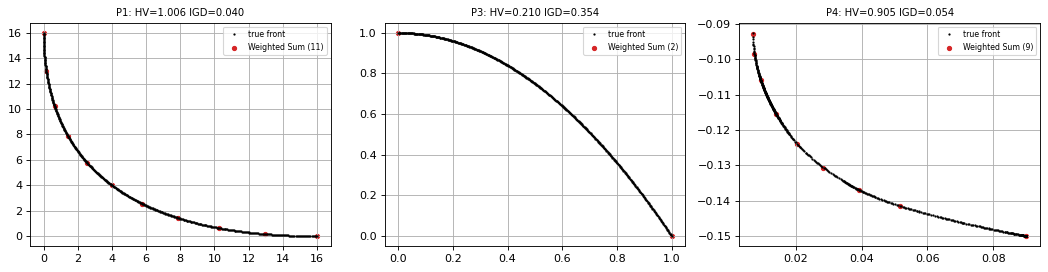

In [8]:
# ---- Shared single-objective solver for classical methods (scipy allowed here) ----
def _solve(p, fun, rng, cons=(), starts=4, x0=None, aug=0):
    """Multi-start SLSQP of fun(y); y = [x, aug extra vars]; honours p.g (>=0) and bounds."""
    n = p.n; cs = list(cons)
    if p.g: cs.append({"type": "ineq", "fun": lambda y: p.g(y[:n])})
    bnds = list(zip(p.lb, p.ub)) + [(0, 10)] * aug; best = None
    for k in range(starts):
        y0 = p.lb + rng.random(n) * (p.ub - p.lb)
        if x0 is not None and k == 0: y0 = np.asarray(x0, float)
        r = minimize(fun, np.r_[y0, np.ones(aug)], method="SLSQP", bounds=bnds, constraints=cs, options={"maxiter": 150})
        if p.f(r.x[:n])[1][0] <= 1e-6 and np.isfinite(r.fun) and (best is None or r.fun < best.fun): best = r
    return None if best is None else best.x[:n]
_fn = lambda p, x: p.norm(p.f(x)[0])[0]          # normalized objective vector of one point

def weighted_sum(p, seed=0, n_w=11):
    """Steps: 1) pick w (sum 1)  2) minimize w·f  3) repeat for n_w weights. Returns decision vectors."""
    rng = np.random.default_rng(seed); out = []
    for w in np.linspace(0, 1, n_w):
        x = _solve(p, lambda x, wv=np.r_[w, 1 - w]: wv @ _fn(p, x), rng)
        if x is not None: out.append(x)
    return np.array(out)

def ut_1():
    X = weighted_sum(P1, 0, 3); F = P1.f(X)[0]
    assert abs(F[0, 1]) < 1e-3 and abs(F[-1, 0]) < 1e-3      # w=(0,1) -> x=7 (f2=0) ; w=(1,0) -> x=3 (f1=0)
    X = weighted_sum(P3, 0, 11); Fn = finalize(P3, X)
    assert ((Fn[:, 0] < 0.05) | (Fn[:, 0] > 0.95)).all()     # ZDT2 (non-convex): only the end points are found
A2(1, lambda P, s, b: finalize(P, weighted_sum(P, s)), unit=ut_1)

#### A2.2 ε-Constraint
Minimize f₂ subject to f₁ ≤ ε; sweep ε between the ideal and nadir of f₁. Reaches non-convex fronts; needs ε bounds.

[2] ε-Constraint: unit test passed


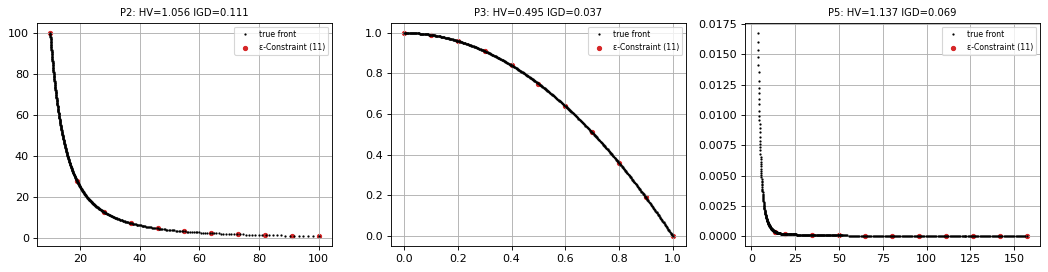

In [9]:
def eps_constraint(p, seed=0, n_eps=11):
    """Steps: 1) choose eps in [ideal,nadir] of f1  2) min f2 s.t. f1<=eps  3) sweep eps."""
    rng = np.random.default_rng(seed); out = []
    for e in np.linspace(0, 1, n_eps):
        x = _solve(p, lambda x: _fn(p, x)[1], rng, cons=[{"type": "ineq", "fun": lambda x, e=e: e - _fn(p, x)[0]}])
        if x is not None: out.append(x)
    return np.array(out)

def ut_2():
    X = eps_constraint(P1, 0, 3); F = P1.f(X)[0]
    assert abs(F[0, 0]) < 1e-3                               # eps=0 forces f1 = 0 (x = 3)
    Fn = finalize(P3, eps_constraint(P3, 0, 11)); assert ((Fn[:, 0] > 0.05) & (Fn[:, 0] < 0.95)).any()   # reaches the middle of ZDT2
A2(2, lambda P, s, b: finalize(P, eps_constraint(P, s)), unit=ut_2)

#### A2.3 Benson's Method
From a feasible reference point x₀ maximize the total improvement Σlᵢ subject to f(x)+l = f(x₀), l ≥ 0 → a Pareto point that dominates x₀.

[3] Benson's Method: unit test passed


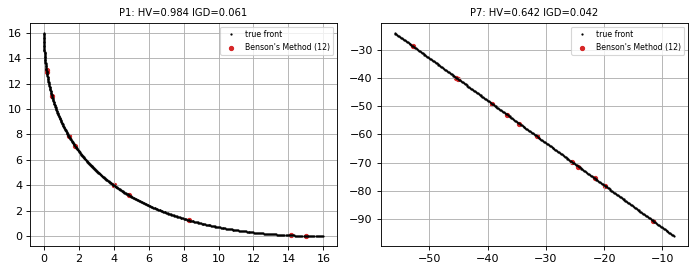

In [10]:
def benson(p, seed=0, n_start=12):
    """Steps: 1) feasible x0  2) max sum(l) s.t. f(x)+l=f(x0), l>=0 (equivalently min sum f s.t. f<=f(x0))  3) repeat for new x0."""
    rng = np.random.default_rng(seed); out = []; X0 = []
    while len(X0) < n_start:
        x = p.init(rng, 1)[0]
        if p.f(x)[1][0] <= 0: X0.append(x)
    for x0 in X0:
        F0 = _fn(p, x0)
        x = _solve(p, lambda x: _fn(p, x).sum(), rng, cons=[{"type": "ineq", "fun": lambda x, F0=F0: F0 - _fn(p, x)}], starts=2, x0=x0)
        if x is not None: out.append(x)
    return np.array(out)

def ut_3():
    X = benson(P1, 1, 5)
    for x in X: pass
    rng = np.random.default_rng(1); x0 = np.array([1.5]); F0 = _fn(P1, x0)
    x = _solve(P1, lambda x: _fn(P1, x).sum(), rng, cons=[{"type": "ineq", "fun": lambda x: F0 - _fn(P1, x)}], x0=x0)
    assert (_fn(P1, x) <= F0 + 1e-6).all()                   # result is at least as good as x0 in every objective
A2(3, lambda P, s, b: finalize(P, benson(P, s)), unit=ut_3)

#### A2.4 Weight Metric (p-norm, Tchebycheff)
Minimize the weighted distance to the ideal point: p = 1, 2 or ∞ (Tchebycheff via an epigraph variable t).

[4] Weight Metric (p-norm, Tchebycheff): unit test passed


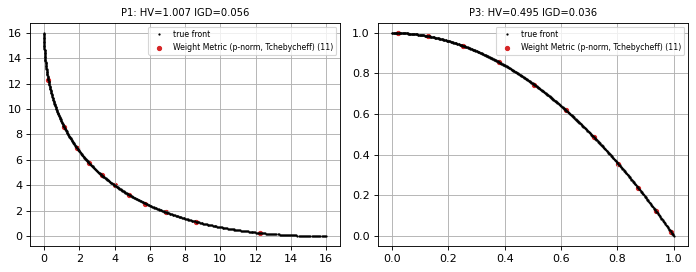

In [11]:
def weight_metric(p, seed=0, pnorm=2, n_w=11):
    """Steps: 1) weights w  2) min (sum w|f-z|^p)^(1/p), or min t s.t. w f <= t for p=inf  3) sweep w."""
    rng = np.random.default_rng(seed); out = []; n = p.n
    for w in np.linspace(0.02, 0.98, n_w):
        wv = np.r_[w, 1 - w]
        if np.isinf(pnorm):
            x = _solve(p, lambda y: y[-1], rng, cons=[{"type": "ineq", "fun": lambda y, wv=wv: y[n] - wv * _fn(p, y[:n])}], aug=1)
        else:
            x = _solve(p, lambda x, wv=wv: np.sum(wv * np.abs(_fn(p, x)) ** pnorm) ** (1 / pnorm), rng)
        if x is not None: out.append(x)
    return np.array(out)

def ut_4():
    x = weight_metric(P1, 0, np.inf, 3)[1]                    # w = 0.5: equal weights -> balanced point x = 5
    assert abs(x[0] - 5) < 0.05
    Fn = finalize(P3, weight_metric(P3, 0, np.inf, 9)); assert ((Fn[:, 0] > 0.05) & (Fn[:, 0] < 0.95)).any()   # Tchebycheff reaches non-convex middle
A2(4, lambda P, s, b: finalize(P, weight_metric(P, s, np.inf)), unit=ut_4)

#### A2.5 Value Function
The decision-maker's utility U(f) is maximized directly: here U = (1.05−f₁)^a (1.05−f₂)^(1−a) on normalized objectives; `a` is the preference input.

[5] Value Function: unit test passed
  P4: preference a=(0.2,0.5,0.8) -> objectives [[0.051, -0.141], [0.03, -0.132], [0.016, -0.118]]
  P14: preference a=(0.2,0.5,0.8) -> objectives [[2.028, -18.315], [1.83, -14.606], [1.632, -10.9]]


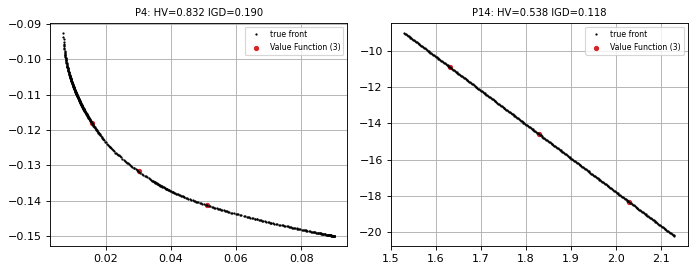

In [12]:
def value_function(p, seed=0, alphas=(0.2, 0.5, 0.8)):
    """Steps: 1) elicit utility U(f)  2) maximize U over feasible x  3) one solution per preference a."""
    rng = np.random.default_rng(seed); out = []
    for a in alphas:
        U = lambda x, a=a: -(max(1.05 - _fn(p, x)[0], 1e-9) ** a) * (max(1.05 - _fn(p, x)[1], 1e-9) ** (1 - a))
        x = _solve(p, U, rng)
        if x is not None: out.append(x)
    return np.array(out)

def ut_5():
    F = P1.f(value_function(P1, 0, (0.2, 0.5, 0.8)))[0]
    assert F[0, 0] > F[1, 0] > F[2, 0] - 1e-9 and abs(F[1, 0] - 4) < 0.3    # larger a weights f1 more -> smaller f1; a=.5 -> x=5
def run_5(P, s, b):
    X = value_function(P, s); print(f"  {P.name}: preference a=(0.2,0.5,0.8) -> objectives", P.f(X)[0].round(3).tolist()); return finalize(P, X)
A2(5, run_5, unit=ut_5)

#### A2.6 Goal Programming
Targets Tᵢ with deviation variables d⁻, d⁺: `fᵢ(x) + dᵢ⁻ − dᵢ⁺ = Tᵢ`; minimize the weighted unwanted deviations (an LP here).

[6] Goal Programming: unit test passed
  P11 unit weights: x=[300. 200.], shortfall d-=[  0. 100.]
  P11 normalized 1/T: x=[300. 200.], shortfall d-=[  0. 100.]
  P7 unit weights: x=[48.33 41.67], shortfall d-=[1.33 0.  ]
  P7 normalized 1/T: x=[48.33 41.67], shortfall d-=[1.33 0.  ]


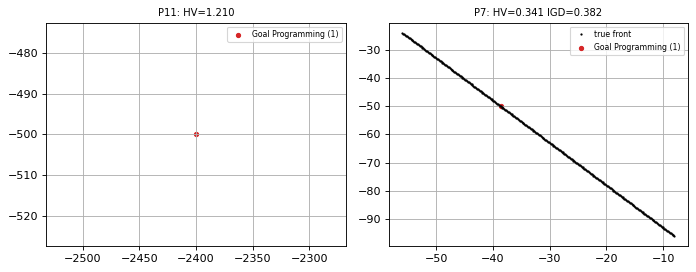

In [13]:
def goal_programming(lin, targets, w, senses=(">=", ">=")):
    """Steps: 1) targets  2) add d-,d+  3) minimize sum w*d (d- for '>=' goals, d+ for '<=')  4) solve LP."""
    C, A, b = lin["C"], lin["A"], lin["b"]; m, n = C.shape
    c = np.r_[np.zeros(n), [w[i] if senses[i] in (">=", "=") else 0 for i in range(m)], [w[i] if senses[i] in ("<=", "=") else 0 for i in range(m)]]
    r = linprog(c, A_ub=np.hstack([A, np.zeros((len(A), 2 * m))]), b_ub=b, A_eq=np.hstack([C, np.eye(m), -np.eye(m)]), b_eq=targets,
                bounds=list(zip(lin["lb"], lin["ub"])) + [(0, None)] * (2 * m), method="highs")
    return r.x[:n], r.x[n:n + m], r.x[n + m:]

def ut_6():
    x, dm, dp = goal_programming(P11.lin, [2400, 600], [1, 1])
    assert abs(dm[1] - 100) < 1e-6 and dm[0] < 1e-6          # units goal 600 unreachable -> shortfall exactly 100; profit met
def run_6(P, s, b):
    lin = P.lin; T = {"P11": [2400, 600], "P7": [40, 50]}[P.name]; sols = []
    for lab, w in [("unit weights", [1, 1]), ("normalized 1/T", [1 / T[0], 1 / T[1]])]:
        x, dm, dp = goal_programming(lin, T, w); sols.append(x); print(f"  {P.name} {lab}: x={x.round(2)}, shortfall d-={dm.round(2)}")
    return finalize(P, np.array(sols))
A2(6, run_6, unit=ut_6)

#### A2.7 Lexicographic
Optimize objectives in strict priority order; each stage fixes the previous optimum (with tolerance). The second stage breaks ties left by the first.

[7] Lexicographic: unit test passed
  P11 priority f1>f2: x=[300. 200.]
  P11 priority f2>f1: x=[300. 200.]
  P7 priority f1>f2: x=[70. 20.]
  P7 priority f2>f1: x=[10. 80.]


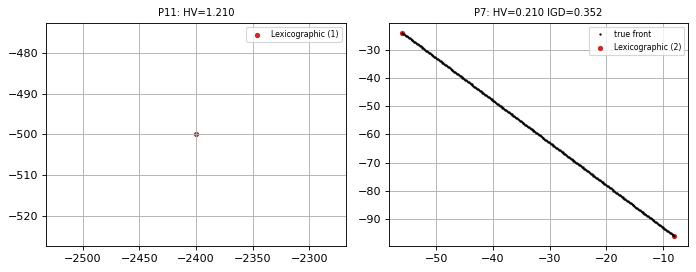

In [14]:
def lexicographic(lin, order, tol=0.0):
    """Steps: 1) optimize highest priority  2) constrain it to its optimum (tolerance tol)  3) optimize next priority."""
    C, A, b = lin["C"], lin["A"], lin["b"]; Au, bu = A.copy(), b.copy(); bnds = list(zip(lin["lb"], lin["ub"]))
    for k in order:
        r = linprog(-C[k], A_ub=Au, b_ub=bu, bounds=bnds, method="highs"); val = -r.fun
        Au = np.vstack([Au, -C[k]]); bu = np.r_[bu, -(val * (1 - tol) - 1e-7)]
    return r.x

def ut_7():
    x = lexicographic(P11.lin, [0, 1]); assert np.allclose(x, [300, 200], atol=1e-3)     # profit tie on segment broken by units
    x1 = linprog(-P11.lin["C"][0], A_ub=P11.lin["A"], b_ub=P11.lin["b"], bounds=[(0, None)] * 2).x
    assert abs(P11.lin["C"][0] @ x1 - 2400) < 1e-6          # stage 1 alone gives 2400 but not a unique point
def run_7(P, s, b):
    sols = [lexicographic(P.lin, [0, 1]), lexicographic(P.lin, [1, 0])]
    for o, x in zip(("f1>f2", "f2>f1"), sols): print(f"  {P.name} priority {o}: x={x.round(2)}")
    return finalize(P, np.array(sols))
A2(7, run_7, unit=ut_7)

#### A2.8 TOPSIS and A2.9 VIKOR (ranking methods, not optimizers)
TOPSIS ranks by closeness to the ideal and anti-ideal; VIKOR ranks by Q = v·S* + (1−v)·R* (group utility vs. worst regret).

In [15]:
def topsis(M, w, benefit):
    """Steps: normalize columns (vector) -> weight -> ideal/anti-ideal -> distances -> closeness C = d-/(d+ + d-)."""
    V = M / np.sqrt((M ** 2).sum(0)) * w
    best = np.where(benefit, V.max(0), V.min(0)); worst = np.where(benefit, V.min(0), V.max(0))
    dp, dm = np.linalg.norm(V - best, axis=1), np.linalg.norm(V - worst, axis=1); return dm / (dp + dm + 1e-18)

def vikor(M, w, benefit, v=0.5):
    """Steps: best/worst per criterion -> S (sum), R (max) of weighted regrets -> Q = v S* + (1-v) R*; smaller Q is better."""
    fs = np.where(benefit, M.max(0), M.min(0)); fm = np.where(benefit, M.min(0), M.max(0)); r = w * (fs - M) / (fs - fm + 1e-18)
    S, R = r.sum(1), r.max(1); nz = lambda a: (a - a.min()) / (a.max() - a.min() + 1e-18)
    return v * nz(S) + (1 - v) * nz(R)

def ut_8():
    M = np.array([[1., 10.], [2., 5.], [3., 1.]]); c = topsis(M, np.array([.5, .5]), np.array([False, True]))
    assert c.argmax() == 0 and ((c >= 0) & (c <= 1)).all()   # alt 0 dominates (cheapest and best) -> closeness highest
    assert vikor(M, np.array([.5, .5]), np.array([False, True])).argmin() == 0
ut_8()
Mx, w0, bf, nm = P12["M"], P12["w"], P12["benefit"], P12["names"]
Fmin = np.where(bf, -Mx, Mx); pareto = nds(Fmin)[0]; print("P12 Pareto-optimal suppliers:", [nm[i] for i in pareto])
w1 = w0 + np.array([.1, -.1, 0, 0])                          # shift one weight by 0.1
rank = lambda sc, hi: [nm[i] for i in (np.argsort(-sc) if hi else np.argsort(sc))]
rows = [("TOPSIS w", rank(topsis(Mx, w0, bf), True)), ("TOPSIS w shifted", rank(topsis(Mx, w1, bf), True))]
for v in (.25, .5, .75): rows += [(f"VIKOR v={v}", rank(vikor(Mx, w0, bf, v), False)), (f"VIKOR v={v} shifted", rank(vikor(Mx, w1, bf, v), False))]
table([(a, " > ".join(b)) for a, b in rows], ["Method", "Ranking (best first)"])
# Apply to the reference front of P4 (risk min, return max); NSGA-II front is used again in Task D
F4 = P4.pf[::8]; M4 = np.c_[F4[:, 0], -F4[:, 1]]; c4 = topsis(M4, np.array([.5, .5]), np.array([False, True]))
print("P4 TOPSIS top-3 (risk, return):", M4[np.argsort(-c4)[:3]].round(3).tolist())
LOG += [dict(idx=8, name="TOPSIS", prob="P12/P4", budget=0, hv=np.nan, sp=np.nan, igd=np.nan, rt=0, status="works", n=5),
        dict(idx=9, name="VIKOR", prob="P12/P4", budget=0, hv=np.nan, sp=np.nan, igd=np.nan, rt=0, status="works", n=5)]

P12 Pareto-optimal suppliers: ['S1', 'S2', 'S3', 'S4', 'S5']


| Method | Ranking (best first) |
|---|---|
| TOPSIS w | S3 > S1 > S5 > S2 > S4 |
| TOPSIS w shifted | S1 > S2 > S3 > S5 > S4 |
| VIKOR v=0.25 | S1 > S2 > S5 > S3 > S4 |
| VIKOR v=0.25 shifted | S2 > S1 > S4 > S5 > S3 |
| VIKOR v=0.5 | S1 > S2 > S5 > S3 > S4 |
| VIKOR v=0.5 shifted | S2 > S1 > S3 > S5 > S4 |
| VIKOR v=0.75 | S1 > S3 > S2 > S5 > S4 |
| VIKOR v=0.75 shifted | S1 > S2 > S3 > S5 > S4 |


P4 TOPSIS top-3 (risk, return): [[0.013, 0.113], [0.013, 0.114], [0.013, 0.114]]


#### A2 (shared base for algorithms 10–35)
Variation operators (SBX + polynomial mutation, order crossover + inversion, uniform crossover + bit-flip), the `MOEA` base class
(`initialize → evaluate → step → run`), an external archive with grid density, and NSGA-II survivor selection. Constraints are
handled by a penalty on normalized objectives unless the algorithm says otherwise (alg. 21 uses Deb's rules).

In [16]:
def sbx(rng, A, B, lb, ub, eta=15, pc=0.9):
    """Simulated binary crossover -> two children."""
    u = rng.random(A.shape); be = np.where(u <= .5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u + 1e-12))) ** (1 / (eta + 1)))
    c1 = .5 * ((1 + be) * A + (1 - be) * B); c2 = .5 * ((1 - be) * A + (1 + be) * B)
    sw = rng.random(A.shape) < .5; c1, c2 = np.where(sw, c2, c1), np.where(sw, c1, c2); m = rng.random((len(A), 1)) < pc
    return np.where(m, c1, A), np.where(m, c2, B)

def polymut(rng, X, lb, ub, eta=20, pm=None):
    """Polynomial mutation (per-gene probability 1/n)."""
    pm = 1 / X.shape[1] if pm is None else pm; u = rng.random(X.shape); mu = rng.random(X.shape) < pm
    d = np.where(u < .5, (2 * u) ** (1 / (eta + 1)) - 1, 1 - (2 * (1 - u)) ** (1 / (eta + 1)))
    return np.clip(X + mu * d * (ub - lb), lb, ub)

def ox(rng, a, b):
    """Order crossover for permutations."""
    n = len(a); i, j = sorted(rng.choice(n, 2, replace=False)); c = -np.ones(n, int); c[i:j + 1] = a[i:j + 1]
    seg = set(a[i:j + 1].tolist()); order = [g for g in np.r_[b[j + 1:], b[:j + 1]] if g not in seg]
    for k, g in zip(list(range(j + 1, n)) + list(range(0, i)), order): c[k] = g
    return c

def invert(rng, x):
    i, j = sorted(rng.choice(len(x), 2, replace=False)); y = x.copy(); y[i:j + 1] = y[i:j + 1][::-1]; return y

def das_dennis(M, p):
    """Uniform reference points on the unit simplex (C(p+M-1, M-1) points)."""
    def rec(M, p):
        if M == 1: return [[p]]
        return [[i] + r for i in range(p + 1) for r in rec(M - 1, p - i)]
    return np.array(rec(M, p), float) / p

def tcheb(F, lam, z): return np.max(np.maximum(lam, 1e-6) * np.abs(F - z), axis=-1)

class MOEA:
    """Base: initialize() -> evaluate() -> step() -> run(); result() = feasible non-dominated set (normalized objectives)."""
    Ndef = 100; swarm = False
    def __init__(s, prob, budget=5000, seed=0, N=None, **kw):
        s.p, s.budget, s.rng, s.N, s.evals, s.gen = prob, budget, np.random.default_rng(seed), N or s.Ndef, 0, 0
        for k, v in kw.items(): setattr(s, k, v)
        s.relax = s.swarm and prob.kind == "bin"          # swarm methods work in [0,1]^n and threshold at 0.5 for binary problems
        s.initialize()
    def evaluate(s, X):
        s.evals += len(X); F, CV = s.p.f((X > .5).astype(float) if s.relax else X); s.last_cv = CV
        return s.p.norm(F) + PEN * CV[:, None]
    def dec(s, X): return (X > .5).astype(float) if s.relax else X
    def newpop(s, n): return s.rng.random((n, s.p.n)) if s.relax else s.p.init(s.rng, n)
    def repair(s, X): return np.clip(X, 0, 1) if s.relax else s.p.repair(X)
    def cross(s, A, B):
        k = s.p.kind
        if s.relax or k in ("real", "int"): C1, C2 = sbx(s.rng, A, B, s.p.lb, s.p.ub)
        elif k == "bin": m = s.rng.random(A.shape) < .5; C1, C2 = np.where(m, A, B), np.where(m, B, A)
        else: C1 = np.array([ox(s.rng, a, b) for a, b in zip(A, B)]); C2 = np.array([ox(s.rng, b, a) for a, b in zip(A, B)])
        return s.repair(C1), s.repair(C2)
    def mutate(s, X):
        k = s.p.kind
        if s.relax or k in ("real", "int"): Y = polymut(s.rng, X, s.p.lb, s.p.ub)
        elif k == "bin": Y = np.where(s.rng.random(X.shape) < 1 / X.shape[1], 1 - X, X)
        else: Y = np.array([invert(s.rng, x) if s.rng.random() < .3 else x for x in X])
        return s.repair(Y)
    def offspring(s, P):
        """Pair consecutive parents, crossover, mutate -> same number of children."""
        n = len(P); P = np.vstack([P, P[:1]]) if n % 2 else P; C1, C2 = s.cross(P[0::2], P[1::2]); return s.mutate(np.vstack([C1, C2]))[:n]
    def neighbor(s, X):
        """Small random move (used by local search / annealing)."""
        k = s.p.kind
        if s.relax or k in ("real", "int"): return s.repair(X + s.rng.normal(0, .05, X.shape) * (s.p.ub - s.p.lb))
        if k == "bin":
            Y = X.copy(); j = s.rng.integers(0, X.shape[1], len(X)); Y[np.arange(len(X)), j] = 1 - Y[np.arange(len(X)), j]; return s.repair(Y)
        return np.array([invert(s.rng, x) for x in X])
    def tourn(s, pop_n, n, better):
        i, j = s.rng.integers(0, pop_n, (2, n)); return np.where(better(i, j), i, j)
    def run(s):
        while s.evals < s.budget:
            e = s.evals; s.step(); s.gen += 1
            if s.evals == e: break
        return s
    def final(s): return s.dec(s.X)
    def result(s): return finalize(s.p, s.final())

class Archive:
    """External archive of non-dominated points with grid-density truncation."""
    def __init__(s, cap=100, div=10, rng=None): s.cap, s.div, s.rng, s.X, s.F = cap, div, rng or np.random.default_rng(0), None, None
    def add(s, X, F):
        XX, FF = (X, F) if s.X is None else (np.vstack([s.X, X]), np.vstack([s.F, F]))
        _, u = np.unique(FF.round(10), axis=0, return_index=True); XX, FF = XX[u], FF[u]
        f0 = nds(FF)[0]; XX, FF = XX[f0], FF[f0]
        while len(FF) > s.cap:
            c = s.counts(FF); k = s.rng.choice(np.where(c == c.max())[0]); XX, FF = np.delete(XX, k, 0), np.delete(FF, k, 0)
        s.X, s.F = XX, FF
    def cell(s, F):
        lo, hi = F.min(0), F.max(0); cid = ((F - lo) / (hi - lo + 1e-12) * s.div).astype(int).clip(0, s.div - 1)
        return np.ravel_multi_index(cid.T, (s.div,) * F.shape[1])
    def counts(s, F=None):
        F = s.F if F is None else F; key = s.cell(F); return np.bincount(key)[key]
    def pick(s, k, rng):
        """Leader selection favouring sparse grid cells (roulette on 1/count)."""
        p = 1.0 / s.counts(); return rng.choice(len(p), k, p=p / p.sum())
    def region_pick(s, k, rng):
        """PESA-II: binary tournament between regions (less crowded wins), then a random member."""
        key = s.cell(s.F); regs = np.unique(key); cnt = {r: (key == r).sum() for r in regs}; out = []
        for _ in range(k):
            a, b = rng.choice(regs, 2); r = a if cnt[a] <= cnt[b] else b; out.append(rng.choice(np.where(key == r)[0]))
        return np.array(out)

def env_select(F, CV, n):
    """NSGA-II survivor selection: fill by fronts, break the last front by crowding. Returns (selected, rank, crowd)."""
    fr = nds(F, CV); rank = np.zeros(len(F), int); crowd = np.zeros(len(F)); sel = []
    for k, f in enumerate(fr): rank[f] = k; crowd[f] = crowding(F[f])
    for f in fr:
        if len(sel) + len(f) <= n: sel += list(f)
        else: sel += list(f[np.argsort(-crowd[f])][:n - len(sel)])
        if len(sel) >= n: break
    return np.array(sel), rank, crowd

#### A2.10 VEGA
One sub-population per objective, each selected by that objective alone, then shuffled and mated. No Pareto ranking, no elitism.

[10] VEGA: unit test passed


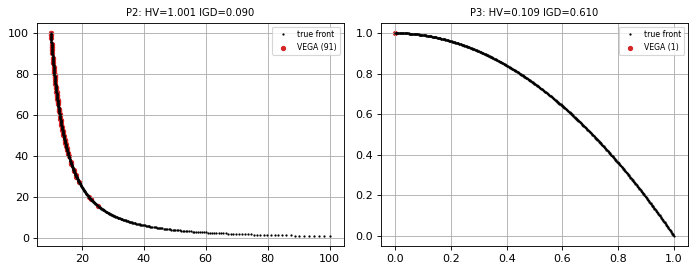

In [17]:
class VEGA(MOEA):
    """Steps: 1) split into M sub-populations, sub-population m selected by tournament on f_m  2) shuffle  3) crossover+mutation. Default N=100."""
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def subpops(s):
        M = s.F.shape[1]; out = []
        for m in range(M):
            i, j = s.rng.integers(0, s.N, (2, s.N // M)); out.append(np.where(s.F[i, m] < s.F[j, m], i, j))
        return out
    def step(s):
        pool = np.concatenate(s.subpops()); pool = np.r_[pool, s.rng.integers(0, s.N, s.N - len(pool))]
        s.X = s.offspring(s.X[s.rng.permutation(pool)]); s.F = s.evaluate(s.X)

def ut_10():
    v = VEGA(P3, budget=10, seed=1, N=60)
    for m, sub in enumerate(v.subpops()): assert v.F[sub, m].mean() < v.F[:, m].mean()    # sub-population m is biased towards low f_m
A2(10, cls_runner(VEGA), unit=ut_10)

#### A2.11 MOGA
Rank = 1 + number of dominators; fitness interpolated from rank, averaged per rank, then divided by the niche count (fitness sharing).

[11] MOGA: unit test passed


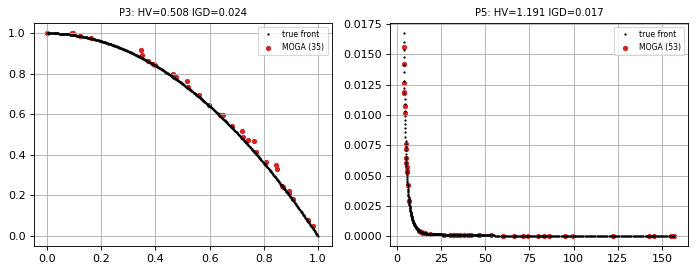

In [18]:
def moga_fitness(F, sigma):
    N = len(F); rank = 1 + dom_matrix(F).sum(0); o = np.argsort(rank, kind="stable"); pos = np.empty(N); pos[o] = N - np.arange(N); fit = np.empty(N)
    for r in np.unique(rank): m = rank == r; fit[m] = pos[m].mean()
    return fit / np.clip(1 - cdist(F, F) / sigma, 0, 1).sum(1), rank

class MOGA(MOEA):
    """Steps: 1) rank=1+#dominators  2) rank-based fitness averaged per rank  3) sharing  4) roulette selection  5) crossover+mutation. sigma=0.1."""
    sigma = 0.1
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def step(s):
        sf, _ = moga_fitness(s.F, s.sigma); par = s.rng.choice(s.N, s.N, p=sf / sf.sum())
        s.X = s.offspring(s.X[par]); s.F = s.evaluate(s.X)

def ut_11():
    F = np.array([[1, 5], [2, 3], [4, 1], [4, 4.], [5, 5.]]); sf, r = moga_fitness(F, 0.5)
    assert (r[:3] == 1).all() and r[3] > 1 and r[4] > r[3]          # rank = 1 + dominators
    F2 = np.array([[1, 3], [1, 3.0001], [3, 1.]]); sf2, _ = moga_fitness(F2, 1.0); assert sf2[2] > sf2[0]   # crowded twins get lower shared fitness
A2(11, cls_runner(MOGA), unit=ut_11)

#### A2.12 NSGA
Non-dominated fronts get dummy fitness (front 1 highest); sharing is applied inside each front; the next front starts slightly below the previous minimum.

[12] NSGA: unit test passed


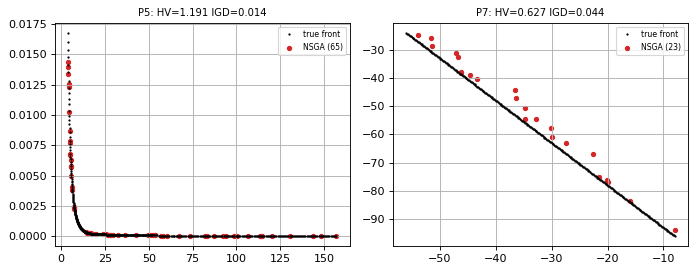

In [19]:
def nsga_fitness(F, sigma):
    fit = np.zeros(len(F)); cur = float(len(F))
    for f in nds(F):
        sf = cur / np.clip(1 - cdist(F[f], F[f]) / sigma, 0, 1).sum(1); fit[f] = sf; cur = sf.min() * 0.9
    return fit

class NSGA(MOEA):
    """Steps: 1) sort into fronts  2) dummy fitness per front  3) sharing within front  4) roulette  5) crossover+mutation. sigma=0.1."""
    sigma = 0.1
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def step(s):
        fit = nsga_fitness(s.F, s.sigma); par = s.rng.choice(s.N, s.N, p=fit / fit.sum()); s.X = s.offspring(s.X[par]); s.F = s.evaluate(s.X)

def ut_12():
    F = np.array([[1, 4], [2, 3], [3, 2], [4, 1], [3, 4.], [4, 3.]]); fr = nds(F); fit = nsga_fitness(F, 0.3)
    assert fit[fr[0]].min() > fit[fr[1]].max()                                            # every front-1 point beats every front-2 point
A2(12, cls_runner(NSGA), unit=ut_12)

#### A2.13 NPGA
Pareto tournament: two candidates are compared against a random comparison set; if exactly one is non-dominated by the set it wins, otherwise the smaller niche count wins.

[13] NPGA: unit test passed


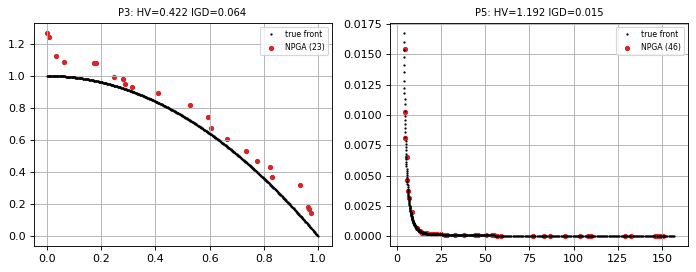

In [20]:
def npga_winner(a, b, Ds, niche):
    da, db = Ds[:, a].any(), Ds[:, b].any()
    return (b if da else a) if da != db else (a if niche[a] <= niche[b] else b)

class NPGA(MOEA):
    """Steps: 1) pick 2 candidates + comparison set (10% of N)  2) dominance vs set  3) tie -> niche count  4) crossover+mutation. sigma=0.1."""
    sigma = 0.1; tdom = 0.1
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def step(s):
        D = dom_matrix(s.F); niche = np.clip(1 - cdist(s.F, s.F) / s.sigma, 0, 1).sum(1); k = max(2, int(s.tdom * s.N)); par = []
        for _ in range(s.N):
            a, b = s.rng.integers(0, s.N, 2); par.append(npga_winner(a, b, D[s.rng.integers(0, s.N, k)], niche))
        s.X = s.offspring(s.X[np.array(par)]); s.F = s.evaluate(s.X)

def ut_13():
    D = dom_matrix(np.array([[1, 1], [2, 2], [3, 3.]])); assert npga_winner(0, 2, D[[1]], np.zeros(3)) == 0   # b dominated by set member, a not
    assert npga_winner(1, 2, np.zeros((1, 3), bool), np.array([0, 5, 1.])) == 2                              # tie -> smaller niche count
A2(13, cls_runner(NPGA), unit=ut_13)

#### A2.14 NSGA-II
Parents + offspring are sorted into fronts (fast non-dominated sort); the last front is cut by crowding distance. Binary tournament uses (rank, crowding).

[14] NSGA-II: unit test passed


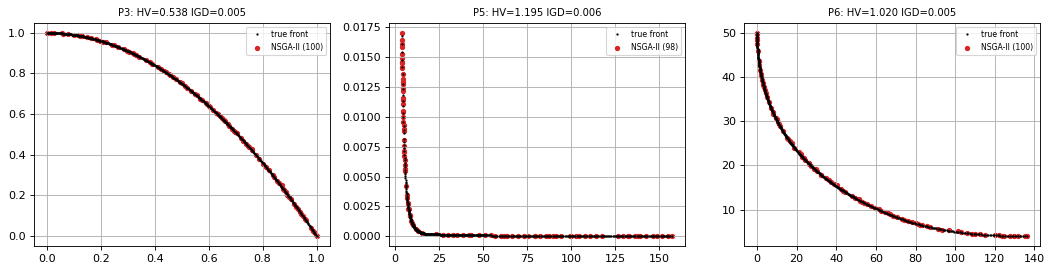

In [21]:
class NSGA2(MOEA):
    """Steps: 1) tournament on (rank, crowding)  2) crossover+mutation  3) merge parents+offspring  4) fast non-dominated sort  5) fill by fronts, crowding on last. Pc=0.9, eta_c=15, eta_m=20."""
    use_cv = False
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.CV = s.last_cv
    def survive(s, F, CV, n): return env_select(F, CV, n)
    def step(s):
        cv = s.CV if s.use_cv else None; _, rank, crowd = s.survive(s.F, cv, len(s.F))
        par = s.tourn(len(s.X), s.N, lambda i, j: (rank[i] < rank[j]) | ((rank[i] == rank[j]) & (crowd[i] > crowd[j])))
        off = s.offspring(s.X[par]); Fo = s.evaluate(off); XU, FU, CVU = np.vstack([s.X, off]), np.vstack([s.F, Fo]), np.r_[s.CV, s.last_cv]
        sel, _, _ = s.survive(FU, CVU if s.use_cv else None, s.N); s.X, s.F, s.CV = XU[sel], FU[sel], CVU[sel]

def ut_14():
    F = np.array([[0, 4], [1, 2.5], [2, 2], [2.1, 1.9], [4, 0], [5, 5.]]); sel, rank, crowd = env_select(F, None, 3)
    assert 0 in sel and 4 in sel and 5 not in sel                                       # boundary points (inf crowding) survive, dominated point dropped
A2(14, cls_runner(NSGA2), unit=ut_14)

#### A2.15 NSGA-III
Crowding distance is replaced by reference points: normalize objectives (ideal, intercepts), associate each point with its nearest reference line, and fill the last front by niche counts.

[15] NSGA-III: unit test passed


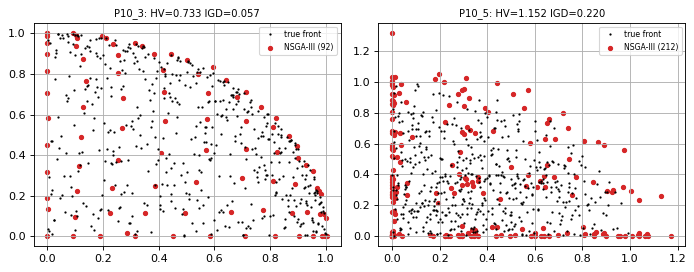

In [22]:
def associate(Zn, W):
    """Perpendicular distance of each point to each reference line -> (nearest line, distance)."""
    Wn = W / np.linalg.norm(W, axis=1, keepdims=True); proj = Zn @ Wn.T
    d = np.sqrt(np.maximum((Zn ** 2).sum(1)[:, None] - proj ** 2, 0)); return d.argmin(1), d.min(1)

class NSGA3(MOEA):
    """Steps: 1) random mating, offspring  2) sort union  3) normalize (ideal, extreme points, intercepts)  4) associate to reference lines  5) niche-preserving fill of last front. Divisions p={2:99,3:12,5:6}."""
    div = None
    def initialize(s):
        M = s.p.m; s.W = das_dennis(M, s.div or {2: 99, 3: 12, 5: 6}.get(M, 4)); s.N = int(np.ceil(len(s.W) / 4) * 4)
        s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def niching(s, FU, St, Fl, K):
        S = np.r_[St, Fl].astype(int); Z = FU[S] - FU[S].min(0); M = Z.shape[1]; E = []
        for j in range(M): w = np.full(M, 1e-6); w[j] = 1; E.append(Z[np.argmin((Z / w).max(1))])
        try:
            a = 1 / np.linalg.solve(np.array(E), np.ones(M)); ok = np.all(a > 1e-6) and np.all(np.isfinite(a))
        except np.linalg.LinAlgError: ok = False
        if not ok: a = Z.max(0)
        ref, d = associate(Z / np.maximum(a, 1e-9), s.W); nS = len(St); rho = np.bincount(ref[:nS], minlength=len(s.W)).astype(float)
        mr, md = ref[nS:], d[nS:]; left = np.ones(len(Fl), bool); chosen = []
        while len(chosen) < K:
            cnt = np.bincount(mr[left], minlength=len(s.W)); rr = np.where(cnt > 0, rho, np.inf); j = s.rng.choice(np.where(rr == rr.min())[0])
            mem = np.where(left & (mr == j))[0]; pick = mem[np.argmin(md[mem])] if rho[j] == 0 else s.rng.choice(mem)
            chosen.append(Fl[pick]); left[pick] = False; rho[j] += 1
        return np.array(chosen, int)
    def step(s):
        off = s.offspring(s.X[s.rng.permutation(s.N)]); Fo = s.evaluate(off); XU, FU = np.vstack([s.X, off]), np.vstack([s.F, Fo]); fr = nds(FU); sel = []; k = 0
        while k < len(fr) and len(sel) + len(fr[k]) <= s.N: sel += list(fr[k]); k += 1
        if len(sel) < s.N: sel += list(s.niching(FU, np.array(sel, int), fr[k], s.N - len(sel)))
        s.X, s.F = XU[sel], FU[sel]

def ut_15():
    W = das_dennis(3, 4); assert len(W) == 15 and np.allclose(W.sum(1), 1)                # C(6,2)=15 reference points on the simplex
    ref, d = associate(0.5 * W[1:] + 1e-9, W[1:]); assert (ref == np.arange(14)).all() and d.max() < 1e-6   # a point on a ray is associated with that ray
A2(15, cls_runner(NSGA3), unit=ut_15)

#### A2.16 SPEA2
Strength S(i) = #dominated by i; raw fitness R(i) = Σ strengths of dominators; density D = 1/(σₖ+2) with k = √(N+N̄); fixed-size archive truncated by nearest-neighbour distance.

[16] SPEA2: unit test passed


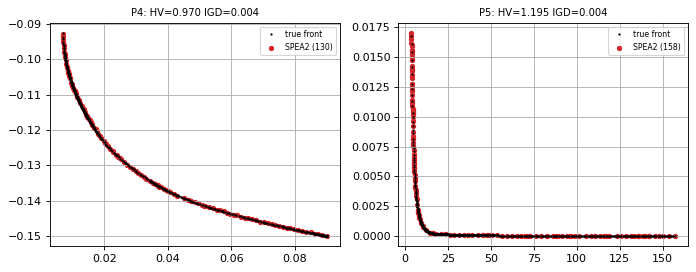

In [23]:
def spea2_fit(F):
    D = dom_matrix(F); S = D.sum(1); R = (D * S[:, None]).sum(0); k = max(1, int(np.sqrt(len(F))))
    return R + 1 / (np.sort(cdist(F, F), 1)[:, min(k, len(F) - 1)] + 2)

def spea2_select(F, n):
    fit = spea2_fit(F); nd = np.where(fit < 1)[0]
    if len(nd) < n: return np.argsort(fit)[:n]
    if len(nd) == n: return nd
    idx = list(range(len(nd))); Dm = cdist(F[nd], F[nd]); np.fill_diagonal(Dm, np.inf)
    while len(idx) > n: sub = np.sort(Dm[np.ix_(idx, idx)], 1); idx.pop(np.lexsort(sub.T[::-1])[0])
    return nd[idx]

class SPEA2(MOEA):
    """Steps: 1) union population+archive  2) fitness R+D  3) environmental selection (non-dominated, truncate/fill) -> archive  4) tournament on archive  5) variation. Archive=N."""
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.AX = np.empty((0, s.p.n)); s.AF = np.empty((0, s.p.m))
    def step(s):
        XU, FU = np.vstack([s.X, s.AX]) if len(s.AX) else s.X, np.vstack([s.F, s.AF]) if len(s.AF) else s.F
        sel = spea2_select(FU, s.N); s.AX, s.AF = XU[sel], FU[sel]; fit = spea2_fit(s.AF)
        par = s.tourn(len(s.AX), s.N, lambda i, j: fit[i] < fit[j]); s.X = s.offspring(s.AX[par]); s.F = s.evaluate(s.X)
    def final(s): return s.dec(np.vstack([s.AX, s.X]))

def ut_16():
    F = np.array([[1, 4], [2, 2], [4, 1], [3, 3.], [5, 5.]]); fit = spea2_fit(F)
    assert (fit[:3] < 1).all() and (fit[3:] >= 1).all()                                  # non-dominated <1, dominated >=1
    assert len(spea2_select(np.random.default_rng(0).random((30, 2)), 10)) == 10
A2(16, cls_runner(SPEA2), unit=ut_16)

#### A2.17 PESA-II
External archive divided into grid regions; parents are chosen by region (less crowded region wins), then a random member of that region.

[17] PESA-II: unit test passed


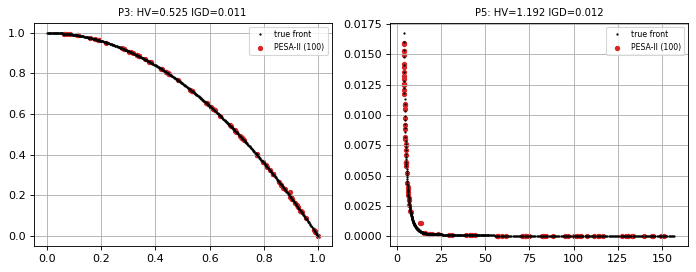

In [24]:
class PESA2(MOEA):
    """Steps: 1) small internal population  2) archive of non-dominated points with grid  3) region tournament + random member  4) variation  5) insert into archive, truncate crowded cell. div=10, cap=100."""
    Ndef = 20; cap = 100; div = 10
    def initialize(s):
        s.A = Archive(s.cap, s.div, s.rng); s.X = s.newpop(s.N); F = s.evaluate(s.X); s.A.add(s.X, F)
    def step(s):
        par = s.A.X[s.A.region_pick(s.N, s.rng)]; s.X = s.offspring(par); s.A.add(s.X, s.evaluate(s.X))
    def final(s): return s.dec(s.A.X)

def ut_17():
    A = Archive(cap=2, div=4, rng=np.random.default_rng(0)); F = np.array([[0.0, 1.0], [0.01, 0.99], [1.0, 0.0]]); A.add(F, F)
    assert len(A.F) == 2 and (A.F[:, 0] == 1.0).any() and (A.F[:, 0] == 1.0).sum() == 1   # the lone point survives; the crowded cell is thinned
    assert A.counts(np.array([[0, 0], [0.01, 0.01], [1, 1.]])).tolist() == [2, 2, 1]
A2(17, cls_runner(PESA2), unit=ut_17)

#### A2.18 MOEA/D and A2.19 MOEA/D-DE
The problem is split into N Tchebycheff sub-problems (weight vectors); each sub-problem mates only with its T nearest neighbours and may replace up to `nr` neighbours. The -DE variant uses DE/rand/1 variation.

[18] MOEA/D: unit test passed


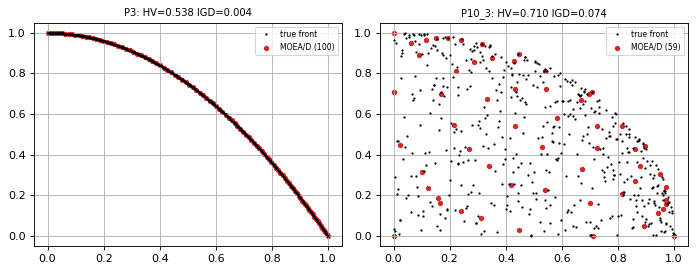

In [25]:
class MOEAD(MOEA):
    """Steps: 1) weight vectors + T-neighbourhoods  2) pick parents from neighbourhood (prob delta)  3) variation  4) update ideal z*  5) replace up to nr neighbours if Tchebycheff improves. T=20, delta=0.9, nr=2."""
    T = 20; delta = 0.9; nr = 2; de = False; Fde = 0.5; CR = 1.0
    def initialize(s):
        M = s.p.m; s.W = np.c_[np.linspace(0, 1, s.N), 1 - np.linspace(0, 1, s.N)] if M == 2 else das_dennis(M, {3: 12, 5: 6}.get(M, 4)); s.N = len(s.W)
        s.B = np.argsort(cdist(s.W, s.W), 1)[:, :min(s.T, s.N)]; s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.z = s.F.min(0)
    def step(s):
        for i in s.rng.permutation(s.N):
            pool = s.B[i] if s.rng.random() < s.delta else np.arange(s.N)
            if s.de:
                r = s.rng.choice(pool, 3, replace=len(pool) < 3); v = s.X[r[0]] + s.Fde * (s.X[r[1]] - s.X[r[2]])
                m = s.rng.random(s.p.n) < s.CR; m[s.rng.integers(s.p.n)] = True; c = s.mutate(s.repair(np.where(m, v, s.X[i])[None]))
            else:
                a, b = s.rng.choice(pool, 2, replace=False); c = s.offspring(s.X[[a, b]])[:1]
            fc = s.evaluate(c)[0]; s.z = np.minimum(s.z, fc); cnt = 0
            for j in s.rng.permutation(pool):
                if tcheb(fc, s.W[j], s.z) <= tcheb(s.F[j], s.W[j], s.z): s.X[j], s.F[j] = c[0], fc; cnt += 1
                if cnt >= s.nr: break
            if s.evals >= s.budget: break

def ut_18():
    z = np.zeros(2); assert tcheb(np.array([.2, .2]), np.array([.5, .5]), z) < tcheb(np.array([.4, .4]), np.array([.5, .5]), z)
    m = MOEAD(P3, budget=50, seed=0, N=20, T=5); assert all(i in m.B[i] for i in range(m.N)) and m.B.shape == (20, 5)   # each sub-problem is in its own neighbourhood
A2(18, cls_runner(MOEAD), unit=ut_18)

[19] MOEA/D-DE: unit test passed


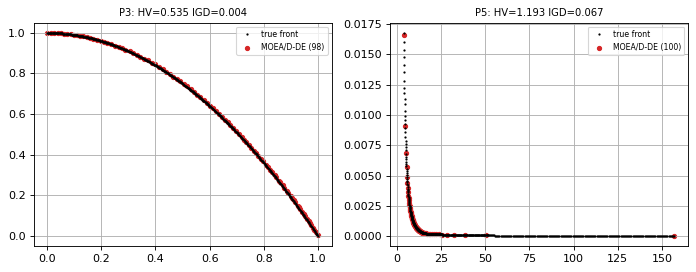

In [26]:
class MOEADDE(MOEAD):
    """MOEA/D with DE/rand/1 variation: v = x_r1 + F (x_r2 - x_r3), binomial crossover CR=1, then polynomial mutation. F=0.5."""
    de = True
def ut_19():
    m = MOEADDE(P3, budget=300, seed=0, N=30, T=6).run(); assert (m.X >= P3.lb - 1e-12).all() and (m.X <= P3.ub + 1e-12).all() and m.de   # DE children stay in bounds
A2(19, cls_runner(MOEADDE), unit=ut_19)

#### A2.20 MOEA/D-ACO
Each sub-problem owns a pheromone matrix; an ant builds a tour using τ^α·η^β where η = 1/(λ₁d + λ₂t); solutions update neighbouring sub-problems (Tchebycheff) and deposit pheromone on their neighbours' matrices.

[20] MOEA/D-ACO: unit test passed


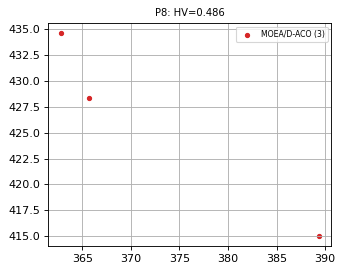

In [27]:
def build_tour(rng, W):
    """Probabilistic route construction from an attractiveness matrix."""
    n = len(W); cur = rng.integers(n); t = [cur]; vis = np.zeros(n, bool); vis[cur] = True
    for _ in range(n - 1):
        w = np.where(vis, 0, W[cur]); cur = rng.choice(n, p=w / w.sum()); t.append(cur); vis[cur] = True
    return np.array(t)

class MOEAD_ACO(MOEA):
    """Steps: 1) weights, neighbourhoods, one pheromone matrix per sub-problem  2) ant builds tour  3) update neighbours (Tchebycheff)  4) evaporate (rho) and deposit. N=20, T=4, rho=0.1, alpha=1, beta=2."""
    Ndef = 20; T = 4; rho = 0.1; alpha = 1.0; beta = 2.0; nr = 2
    def initialize(s):
        p = s.p; n = p.n; t = np.linspace(0, 1, s.N); s.W = np.c_[t, 1 - t]; s.B = np.argsort(cdist(s.W, s.W), 1)[:, :s.T]
        dn, tn = p.D / p.D.mean(), p.Tm / p.Tm.mean(); s.eta = np.array([1 / np.maximum(w[0] * dn + w[1] * tn, 1e-9) for w in s.W])
        for e in s.eta: np.fill_diagonal(e, 1e-12)
        s.tau = np.ones((s.N, n, n)); s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.z = s.F.min(0)
    def step(s):
        for i in range(s.N):
            t = build_tour(s.rng, (s.tau[i] ** s.alpha) * (s.eta[i] ** s.beta)); f = s.evaluate(t[None])[0]; s.z = np.minimum(s.z, f); c = 0
            for j in s.rng.permutation(s.B[i]):
                if tcheb(f, s.W[j], s.z) <= tcheb(s.F[j], s.W[j], s.z): s.X[j], s.F[j] = t, f; c += 1
                if c >= s.nr: break
        for i in range(s.N):
            s.tau[i] *= (1 - s.rho)
            for j in s.B[i]:
                t = s.X[j]; nx = np.roll(t, -1); d = 1 / (tcheb(s.F[j], s.W[i], s.z) + 0.05); s.tau[i][t, nx] += d; s.tau[i][nx, t] += d

def ut_20():
    a = MOEAD_ACO(P8, budget=100, seed=0, N=6, T=3); assert all(sorted(x) == list(range(15)) for x in a.X)      # every route visits each city once
    a.run(); assert all(sorted(x) == list(range(15)) for x in a.X)
A2(20, cls_runner(MOEAD_ACO), unit=ut_20)

#### A2.21 Constrained NSGA-II
NSGA-II with Deb's feasibility rules inside dominance: (1) feasible beats infeasible, (2) both feasible → usual dominance, (3) both infeasible → smaller violation wins.

[21] Constrained NSGA-II: unit test passed


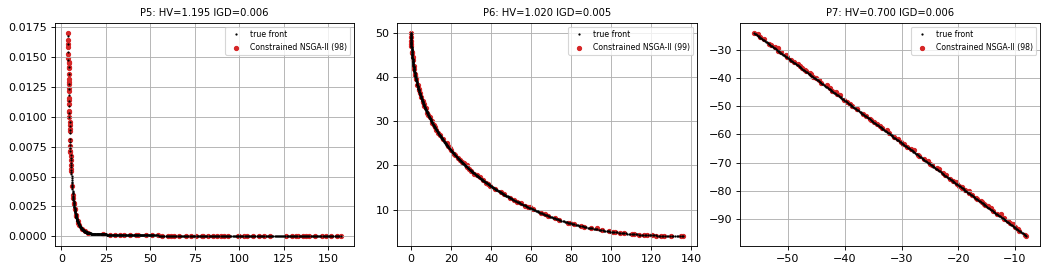

In [28]:
class CNSGA2(NSGA2):
    """NSGA-II steps with constrained-dominance (Deb's three rules) used by sorting, crowded comparison and survivor selection."""
    use_cv = True

def ut_21():
    sel, rank, _ = env_select(np.array([[5., 5.], [1., 1.], [2., 2.]]), np.array([0, 1., .5]), 1); assert sel[0] == 0       # feasible wins despite worse F
    sel, rank, _ = env_select(np.array([[5., 5.], [1., 1.], [2., 2.]]), np.array([0, 1., .5]), 3); assert list(sel) == [0, 2, 1]   # then smaller violation first
A2(21, cls_runner(CNSGA2), unit=ut_21)

#### A2.22 MOPSO
Particles move with `v = w·v + c₁r₁(pbest−x) + c₂r₂(gbest−x)`; the global best is drawn from an external archive (sparse grid cells preferred).

[22] MOPSO: unit test passed


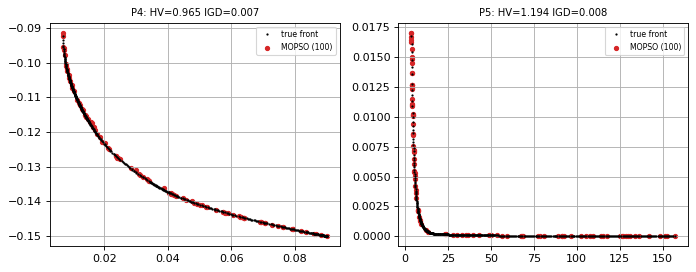

In [29]:
class MOPSO(MOEA):
    """Steps: 1) init swarm, archive  2) leader from archive (grid roulette)  3) velocity+position update  4) mutation (10%)  5) pbest by dominance  6) archive update. N=50, w=0.4, c1=c2=1.5, cap=100."""
    Ndef = 50; swarm = True; w = 0.4; c1 = 1.5; c2 = 1.5; cap = 100; pm = 0.1
    def initialize(s):
        s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.V = np.zeros_like(s.X); s.PB, s.PF = s.X.copy(), s.F.copy()
        s.A = Archive(s.cap, 10, s.rng); s.A.add(s.X, s.F)
    def step(s):
        L = s.A.X[s.A.pick(s.N, s.rng)]; r1, r2 = s.rng.random((2,) + s.X.shape); rg = s.p.ub - s.p.lb
        s.V = np.clip(s.w * s.V + s.c1 * r1 * (s.PB - s.X) + s.c2 * r2 * (L - s.X), -.5 * rg, .5 * rg); s.X = np.clip(s.X + s.V, s.p.lb, s.p.ub)
        mm = s.rng.random(s.N) < s.pm; s.X[mm] = polymut(s.rng, s.X[mm], s.p.lb, s.p.ub, pm=0.5) if mm.any() else s.X[mm]
        s.F = s.evaluate(s.X); nd = lambda a, b: (a <= b).all(1) & (a < b).any(1)
        upd = nd(s.F, s.PF) | (~nd(s.PF, s.F) & (s.rng.random(s.N) < .5)); s.PB[upd], s.PF[upd] = s.X[upd], s.F[upd]; s.A.add(s.X, s.F)
    def final(s): return s.dec(s.A.X)

def ut_22():
    m = MOPSO(P4, budget=10 ** 6, seed=0, N=10, w=0, c1=0, c2=0, pm=0); X0 = m.X.copy(); m.step(); assert np.allclose(m.X, X0)   # no inertia/attraction -> no movement
    m = MOPSO(P4, budget=10 ** 6, seed=0, N=20); [m.step() for _ in range(5)]; assert len(nds(m.A.F)[0]) == len(m.A.F)          # archive is mutually non-dominated
A2(22, cls_runner(MOPSO), unit=ut_22)

#### A2.23 MOGWO
Three leaders α, β, δ are taken from the archive; every wolf moves to the average of three encircling moves `X_k − A·|C·X_k − X|` with `a` shrinking from 2 to 0.

[23] MOGWO: unit test passed


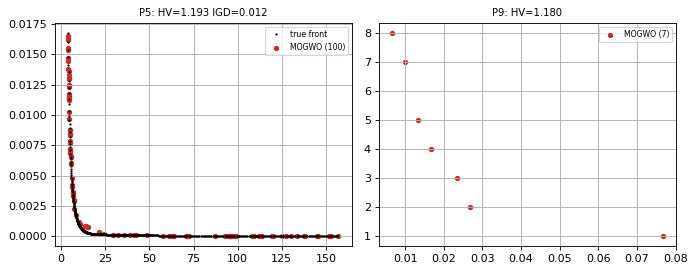

In [30]:
class MOGWO(MOEA):
    """Steps: 1) init pack + archive  2) pick alpha,beta,delta from archive  3) a=2(1-t/T); A=2a r1-a; C=2 r2  4) X=(X1+X2+X3)/3  5) archive update. N=50, cap=100."""
    Ndef = 50; swarm = True; cap = 100
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.A = Archive(s.cap, 10, s.rng); s.A.add(s.X, s.F)
    def step(s):
        a = 2 * (1 - s.evals / s.budget); L = s.A.X[s.A.pick(3, s.rng)]; Xn = 0
        for k in range(3):
            A = 2 * a * s.rng.random(s.X.shape) - a; C = 2 * s.rng.random(s.X.shape); Xn = Xn + (L[k] - A * np.abs(C * L[k] - s.X)) / 3
        s.X = np.clip(Xn, s.p.lb, s.p.ub); s.F = s.evaluate(s.X); s.A.add(s.X, s.F)
    def final(s): return s.dec(s.A.X)

def ut_23():
    m = MOGWO(P5, budget=10 ** 6, seed=0, N=20); m.step(); assert (m.X >= P5.lb).all() and (m.X <= P5.ub).all() and len(nds(m.A.F)[0]) == len(m.A.F)
    assert 2 * (1 - 0 / 100) == 2 and 2 * (1 - 100 / 100) == 0                           # coefficient a shrinks 2 -> 0 (explore -> exploit)
A2(23, cls_runner(MOGWO), unit=ut_23)

#### A2.24 MOABC
Employed bees perturb one dimension toward a random neighbour; onlookers choose sources by Pareto rank; greedy replacement by dominance; scouts replace sources unimproved for `limit` trials.

[24] MOABC: unit test passed


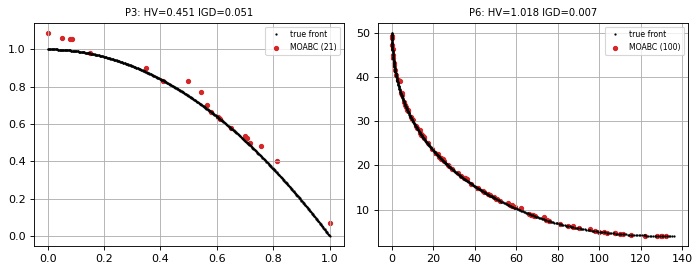

In [31]:
class MOABC(MOEA):
    """Steps: 1) food sources  2) employed phase v=x+phi(x-x_k) (one dim), keep if v dominates x  3) onlookers (prob ~ 1/(1+rank))  4) scouts after `limit` fails  5) archive. N=40, limit=10."""
    Ndef = 40; swarm = True; limit = 10; cap = 100
    def initialize(s):
        s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.trial = np.zeros(s.N, int); s.A = Archive(s.cap, 10, s.rng); s.A.add(s.X, s.F)
    def attempt(s, idx):
        n = len(idx); k = (idx + s.rng.integers(1, s.N, n)) % s.N; j = s.rng.integers(0, s.p.n, n); V = s.X[idx].copy(); r = np.arange(n)
        V[r, j] = s.X[idx, j] + s.rng.uniform(-1, 1, n) * (s.X[idx, j] - s.X[k, j]); V = np.clip(V, s.p.lb, s.p.ub); Fv = s.evaluate(V); s.A.add(V, Fv)
        for t, i in enumerate(idx):
            if (Fv[t] <= s.F[i]).all() and (Fv[t] < s.F[i]).any(): s.X[i], s.F[i], s.trial[i] = V[t], Fv[t], 0
            else: s.trial[i] += 1
    def step(s):
        s.attempt(np.arange(s.N)); rank = np.zeros(s.N)
        for k, f in enumerate(nds(s.F)): rank[f] = k
        p = 1 / (1 + rank); s.attempt(s.rng.choice(s.N, s.N, p=p / p.sum())); sc = np.where(s.trial > s.limit)[0]
        if len(sc): s.X[sc] = s.newpop(len(sc)); s.F[sc] = s.evaluate(s.X[sc]); s.trial[sc] = 0; s.A.add(s.X[sc], s.F[sc])
    def final(s): return s.dec(s.A.X)

def ut_24():
    m = MOABC(P3, budget=10 ** 6, seed=0, N=20, limit=2); Fb = m.F.copy(); m.attempt(np.arange(20))
    assert all(((m.F[i] <= Fb[i]).all()) for i in range(20))                              # greedy: a source only ever moves to a dominating point
    m.trial[:] = 5; m.step(); assert (m.trial <= 5).all() and m.trial.min() == 0         # scouts reset exhausted sources
A2(24, cls_runner(MOABC), unit=ut_24)

#### A2.25 MOACO
Two pheromone matrices (distance, time); each ant draws a random weight λ and builds a tour with `(τ₁^λ τ₂^(1−λ))^α (η₁^λ η₂^(1−λ))^β`; archive members deposit pheromone.

[25] MOACO: unit test passed


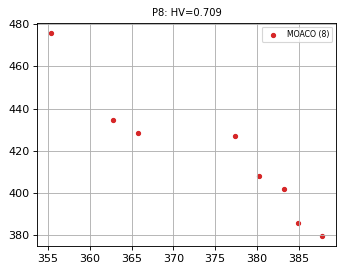

In [32]:
class MOACO(MOEA):
    """Steps: 1) tau1, tau2, eta1=1/d, eta2=1/t  2) each ant: random lambda, probabilistic tour  3) evaluate, archive  4) evaporate (rho), deposit from archive. ants=20, rho=0.1, alpha=1, beta=2."""
    Ndef = 20; rho = 0.1; alpha = 1.0; beta = 2.0; cap = 100
    def initialize(s):
        n = s.p.n; s.t1, s.t2 = np.ones((n, n)), np.ones((n, n)); s.e1, s.e2 = 1 / s.p.D, 1 / s.p.Tm
        for e in (s.e1, s.e2): np.fill_diagonal(e, 1e-12)
        s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.A = Archive(s.cap, 10, s.rng); s.A.add(s.X, s.F)
    def step(s):
        T = [build_tour(s.rng, ((s.t1 ** l) * (s.t2 ** (1 - l))) ** s.alpha * ((s.e1 ** l) * (s.e2 ** (1 - l))) ** s.beta) for l in s.rng.random(s.N)]
        s.X = np.array(T); s.F = s.evaluate(s.X); s.A.add(s.X, s.F); s.t1 *= 1 - s.rho; s.t2 *= 1 - s.rho
        for t, f in zip(s.A.X, s.A.F):
            nx = np.roll(t, -1); d1, d2 = 1 / (f[0] + .05), 1 / (f[1] + .05); s.t1[t, nx] += d1; s.t1[nx, t] += d1; s.t2[t, nx] += d2; s.t2[nx, t] += d2
    def final(s): return s.A.X

def ut_25():
    m = MOACO(P8, budget=10 ** 6, seed=0, N=8); t1 = m.t1.copy(); m.step()
    assert all(sorted(x) == list(range(15)) for x in m.X) and np.allclose(m.t1, m.t1.T) and m.t1.max() > 1 and m.t1.min() < 1   # valid tours; deposit and evaporation both happened
A2(25, cls_runner(MOACO), unit=ut_25)

#### A2.26 MOSA
A set of annealing chains with different weight vectors; neighbour moves are accepted if they dominate or by the Boltzmann rule `exp(−ΔE/T)` on the weighted energy; geometric cooling.

[26] MOSA: unit test passed


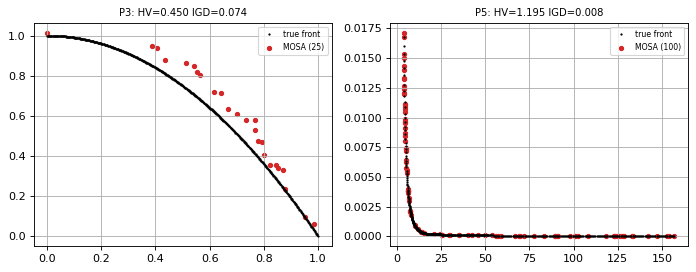

In [33]:
class MOSA(MOEA):
    """Steps: 1) chains with weight vectors, T0  2) neighbour move  3) accept if dominates / dE<=0 / rand<exp(-dE/T)  4) archive  5) T*=alpha (geometric). N=30 chains, T0=0.5, Tend=1e-3."""
    Ndef = 30; T0 = 0.5; Tend = 1e-3; cap = 100
    def initialize(s):
        M = s.p.m; t = np.linspace(0, 1, s.N); s.w = np.c_[t, 1 - t] if M == 2 else s.rng.dirichlet(np.ones(M), s.N)
        s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.T = s.T0; s.cool = (s.Tend / s.T0) ** (1 / max(1, s.budget // s.N))
        s.A = Archive(s.cap, 10, s.rng); s.A.add(s.X, s.F)
    def step(s):
        Xn = s.neighbor(s.X); Fn = s.evaluate(Xn); dE = (s.w * (Fn - s.F)).sum(1); dom = (Fn <= s.F).all(1) & (Fn < s.F).any(1)
        acc = dom | (dE <= 0) | (s.rng.random(s.N) < np.exp(-np.maximum(dE, 0) / s.T)); s.X[acc], s.F[acc] = Xn[acc], Fn[acc]
        s.A.add(Xn, Fn); s.T *= s.cool
    def final(s): return s.dec(s.A.X)

def ut_26():
    assert np.exp(-0.1 / 0.01) < np.exp(-0.1 / 1.0)                                       # worse moves are accepted less often at low temperature
    m = MOSA(P3, budget=3000, seed=0, N=30).run(); assert m.T < m.T0 * 0.5
A2(26, cls_runner(MOSA), unit=ut_26)

#### A2.27 MODE
DE/rand/1 mutation `v = x_r1 + F(x_r2 − x_r3)`, binomial crossover; the trial replaces its target **only if it dominates it**.

[27] MODE: unit test passed


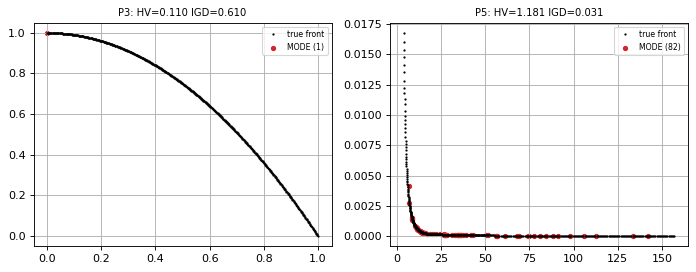

In [34]:
class MODE(MOEA):
    """Steps: 1) population  2) v=x_r1+F(x_r2-x_r3)  3) binomial crossover CR  4) trial replaces target only if it dominates. N=100, F=0.5, CR=0.9."""
    swarm = True; Fm = 0.5; CR = 0.9
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def step(s):
        N = s.N; r = np.array([s.rng.choice(N, 3, replace=False) for _ in range(N)]); V = s.X[r[:, 0]] + s.Fm * (s.X[r[:, 1]] - s.X[r[:, 2]])
        m = s.rng.random(s.X.shape) < s.CR; m[np.arange(N), s.rng.integers(0, s.p.n, N)] = True; U = np.clip(np.where(m, V, s.X), s.p.lb, s.p.ub)
        Fu = s.evaluate(U); b = (Fu <= s.F).all(1) & (Fu < s.F).any(1); s.X[b], s.F[b] = U[b], Fu[b]

def ut_27():
    m = MODE(P3, budget=10 ** 6, seed=0, N=30); Fb = m.F.copy(); m.step(); assert (m.F <= Fb + 1e-12).all()      # a target never gets worse in any objective
A2(27, cls_runner(MODE), unit=ut_27)

#### A2.28 MO-TLBO
Teacher phase moves learners toward a non-dominated teacher using a shrinking teaching factor; learner phase moves toward/away from a random partner; survivors by non-dominated sorting + crowding.

[28] MO-TLBO: unit test passed


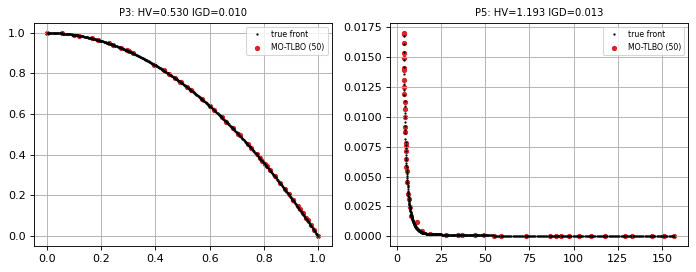

In [35]:
class MOTLBO(MOEA):
    """Steps: 1) class of learners  2) teacher = random non-dominated learner; Xn=X+r(T-TF*mean), TF=2-t/T  3) learner phase with random partner  4) merge, non-dominated sort + crowding. N=50."""
    Ndef = 50; swarm = True
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def merge(s, Xn):
        Xn = np.clip(Xn, s.p.lb, s.p.ub); Fn = s.evaluate(Xn); XU, FU = np.vstack([s.X, Xn]), np.vstack([s.F, Fn]); sel, _, _ = env_select(FU, None, s.N); s.X, s.F = XU[sel], FU[sel]
    def step(s):
        T = s.X[s.rng.choice(nds(s.F)[0])]; TF = 2 - s.evals / s.budget; s.merge(s.X + s.rng.random(s.X.shape) * (T - TF * s.X.mean(0)))
        j = s.rng.integers(0, s.N, s.N); d = (s.F <= s.F[j]).all(1) & (s.F < s.F[j]).any(1); sg = np.where(d, 1.0, -1.0)[:, None]
        s.merge(s.X + s.rng.random(s.X.shape) * sg * (s.X - s.X[j]))

def ut_28():
    m = MOTLBO(P3, budget=10 ** 6, seed=0, N=30); h0 = hv(m.F[nds(m.F)[0]], P3.ref); m.step()
    assert len(m.X) == 30 and hv(m.F[nds(m.F)[0]], P3.ref) >= h0 - 1e-12                  # elitist merge never loses hypervolume
    assert 1 <= 2 - 0.5 <= 2                                                              # teaching factor stays in [1,2] and shrinks
A2(28, cls_runner(MOTLBO), unit=ut_28)

#### A2.29 MOBA
Bats fly with frequency-driven velocity toward an archive leader; a random local walk around the leader is used when `rand > pulse rate`; a move is accepted with probability = loudness, then loudness decreases and pulse rate increases.

[29] MOBA: unit test passed


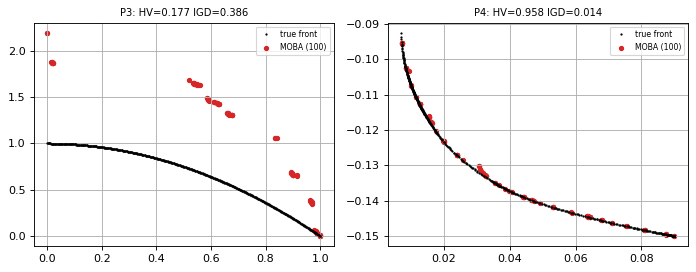

In [36]:
class MOBA(MOEA):
    """Steps: 1) bats, loudness A=1, pulse r0  2) f=fmin+(fmax-fmin)b; v+=(x-leader)f; x+=v  3) local walk if rand>r  4) accept if rand<A and not dominated by old  5) A*=alpha, r=r0(1-exp(-gamma t))  6) archive. N=40, alpha=gamma=0.9."""
    Ndef = 40; swarm = True; fmin = 0.0; fmax = 2.0; alpha = 0.9; gamma = 0.9; r0 = 0.5; cap = 100
    def initialize(s):
        s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.V = np.zeros_like(s.X); s.A_ = np.ones(s.N); s.r_ = np.zeros(s.N)
        s.A = Archive(s.cap, 10, s.rng); s.A.add(s.X, s.F)
    def step(s):
        rg = s.p.ub - s.p.lb; L = s.A.X[s.A.pick(s.N, s.rng)]; f = s.fmin + (s.fmax - s.fmin) * s.rng.random((s.N, 1))
        s.V = np.clip(s.V + (s.X - L) * f, -.3 * rg, .3 * rg); Xn = np.clip(s.X + s.V, s.p.lb, s.p.ub); loc = s.rng.random(s.N) > s.r_
        Xn[loc] = np.clip(L[loc] + 0.02 * s.rng.normal(size=Xn[loc].shape) * rg * s.A_.mean(), s.p.lb, s.p.ub); Fn = s.evaluate(Xn)
        acc = (s.rng.random(s.N) < s.A_) & ~((s.F <= Fn).all(1) & (s.F < Fn).any(1)); s.X[acc], s.F[acc] = Xn[acc], Fn[acc]
        s.A_[acc] *= s.alpha; s.r_[acc] = s.r0 * (1 - np.exp(-s.gamma * (s.gen + 1))); s.A.add(Xn, Fn)
    def final(s): return s.dec(s.A.X)

def ut_29():
    m = MOBA(P3, budget=10 ** 6, seed=0, N=20); A0 = m.A_.copy(); m.step()
    assert (m.A_ <= A0 + 1e-12).all() and (m.A_ < A0).any() and (m.r_ <= m.r0 + 1e-12).all() and (m.r_ > 0).any()   # loudness falls, pulse rate rises (0 -> r0) after accepted moves
A2(29, cls_runner(MOBA), unit=ut_29)

#### A2.30 MOMA
NSGA-II global search plus hill-climbing on a fraction of the population: a neighbour replaces a member only if it dominates it.

[30] MOMA: unit test passed


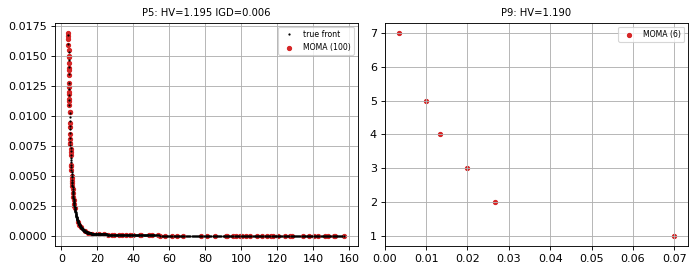

In [37]:
class MOMA(NSGA2):
    """Steps: NSGA-II generation, then local search: pick ls_frac of the population, ls_steps neighbour moves, replace if the neighbour dominates. ls_frac=0.1, ls_steps=3."""
    ls_frac = 0.1; ls_steps = 3
    def local_search(s):
        idx = s.rng.choice(len(s.X), max(1, int(s.ls_frac * len(s.X))), replace=False)
        for _ in range(s.ls_steps):
            Xn = s.neighbor(s.X[idx]); Fn = s.evaluate(Xn); cv = s.last_cv; b = (Fn <= s.F[idx]).all(1) & (Fn < s.F[idx]).any(1)
            s.X[idx[b]], s.F[idx[b]], s.CV[idx[b]] = Xn[b], Fn[b], cv[b]
    def step(s): NSGA2.step(s); s.local_search()

def ut_30():
    m = MOMA(P3, budget=10 ** 6, seed=0, N=20, ls_frac=1.0); Fb = m.F.copy(); m.local_search(); assert (m.F <= Fb + 1e-12).all()   # hill climbing never worsens a member
A2(30, cls_runner(MOMA), unit=ut_30)

#### A2.31 RVEA
Reference vectors guide selection: each solution is assigned to its nearest vector (by angle) and the one with the smallest angle-penalized distance (APD) survives per vector; vectors are re-scaled periodically.

[31] RVEA: unit test passed


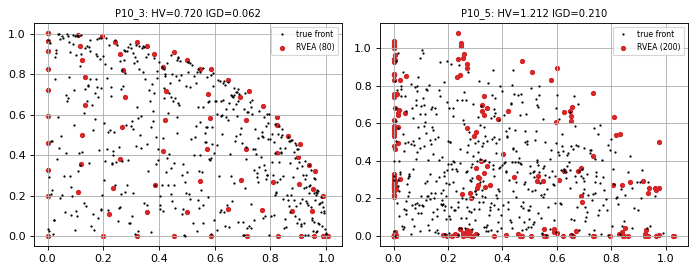

In [38]:
class RVEA(MOEA):
    """Steps: 1) reference vectors (Das-Dennis)  2) random mating  3) translate by ideal, assign by angle  4) APD=(1+M(t/T)^a * theta/gamma)*||f||, best per vector  5) adapt vectors every fr*T gens. alpha=2, fr=0.1."""
    alpha = 2.0; fr = 0.1; div = None
    def initialize(s):
        M = s.p.m; W = das_dennis(M, s.div or {2: 99, 3: 12, 5: 6}.get(M, 4)); s.W0 = W / np.linalg.norm(W, axis=1, keepdims=True); s.Wv = s.W0.copy(); s.N = len(W)
        s.X = s.newpop(s.N); s.F = s.evaluate(s.X); s.Tg = max(1, s.budget // s.N)
    def apd_select(s, F):
        Z = F - F.min(0); nr = np.linalg.norm(Z, axis=1) + 1e-12; ang = np.arccos(np.clip((Z @ s.Wv.T) / nr[:, None], -1, 1)); asg = ang.argmin(1)
        cw = s.Wv @ s.Wv.T; np.fill_diagonal(cw, -1); gam = np.arccos(np.clip(cw.max(1), -1, 1)) + 1e-12; sel = []
        for v in np.unique(asg):
            m = np.where(asg == v)[0]; sel.append(m[np.argmin((1 + F.shape[1] * (s.gen / s.Tg) ** s.alpha * ang[m, v] / gam[v]) * nr[m])])
        return np.array(sel)
    def step(s):
        off = s.offspring(s.X[s.rng.integers(0, len(s.X), s.N)]); XU, FU = np.vstack([s.X, off]), np.vstack([s.F, s.evaluate(off)]); sel = s.apd_select(FU); s.X, s.F = XU[sel], FU[sel]
        if s.gen > 0 and s.gen % max(1, int(s.fr * s.Tg)) == 0:
            v = s.W0 * (s.F.max(0) - s.F.min(0) + 1e-12); s.Wv = v / np.linalg.norm(v, axis=1, keepdims=True)

def ut_31():
    m = RVEA(P10_3, budget=10 ** 6, seed=0); sel = m.apd_select(np.array([[1., 0, 0], [2., 0, 0], [0, 1., 0]]))
    assert set(sel) == {0, 2}                                                             # same vector -> smaller distance wins; other vector keeps its own member
A2(31, cls_runner(RVEA), unit=ut_31)

#### A2.32 IBEA
Fitness from the additive ε-indicator `I(x,y)=max_k f_k(x)−f_k(y)`: `F(x)=−Σ_y exp(−I(y,x)/(c κ))`. No explicit diversity step; the worst individual is removed one at a time and fitness is updated.

[32] IBEA: unit test passed


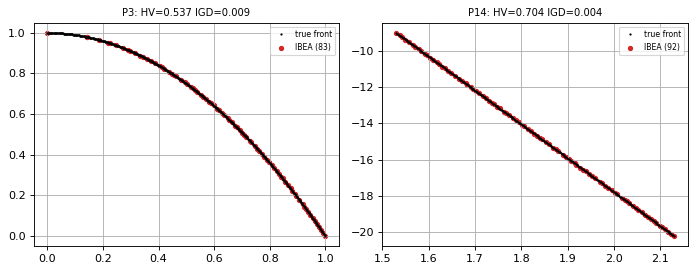

In [39]:
class IBEA(MOEA):
    """Steps: 1) pairwise eps-indicator  2) fitness F(x)=-sum exp(-I(y,x)/(c*kappa))  3) tournament on fitness  4) merge, repeatedly delete worst + update fitness. kappa=0.05."""
    kappa = 0.05
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def fitness(s, F):
        I = (F[:, None, :] - F[None, :, :]).max(2); E = np.exp(-I / ((np.abs(I).max() + 1e-12) * s.kappa)); np.fill_diagonal(E, 0); return -E.sum(0), E
    def select(s, F, n):
        fit, E = s.fitness(F); act = list(range(len(F)))
        while len(act) > n: w = act[int(np.argmin(fit[act]))]; act.remove(w); fit = fit + E[w]
        return np.array(act)
    def step(s):
        fit, _ = s.fitness(s.F); par = s.tourn(len(s.X), s.N, lambda i, j: fit[i] > fit[j]); off = s.offspring(s.X[par])
        XU, FU = np.vstack([s.X, off]), np.vstack([s.F, s.evaluate(off)]); sel = s.select(FU, s.N); s.X, s.F = XU[sel], FU[sel]

def ut_32():
    m = IBEA(P3, budget=10 ** 6, seed=0, N=10); fit, _ = m.fitness(np.array([[0, 0.], [1, 1.]])); assert fit[1] < fit[0]      # dominated point has lower fitness
    F = np.array([[0, 1.], [1, 0.], [.5, .5], [1, 1.]]); assert 3 not in m.select(F, 3)                                      # the dominated point is deleted first
A2(32, cls_runner(IBEA), unit=ut_32)

#### A2.33 SMS-EMOA
Steady state: one offspring per step; after non-dominated sorting the individual of the last front with the smallest hypervolume contribution is discarded.

[33] SMS-EMOA: unit test passed


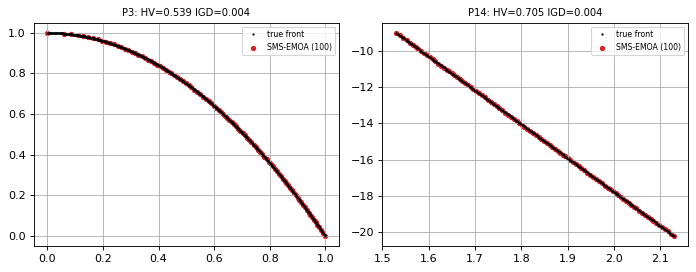

In [40]:
def contrib2d(F, ref):
    """Exact hypervolume contribution of every point of a 2-D non-dominated set."""
    o = np.argsort(F[:, 0]); P = np.minimum(F[o], ref); c = np.zeros(len(F))
    for k in range(len(P)):
        right = P[k + 1, 0] if k + 1 < len(P) else ref[0]; up = P[k - 1, 1] if k > 0 else ref[1]; c[o[k]] = max(0.0, (right - P[k, 0]) * (up - P[k, 1]))
    return c

def contrib_mc(F, ref, rng, S=4000):
    """Monte-Carlo contribution = volume dominated by this point only (3+ objectives)."""
    lo = np.minimum(F.min(0), ref - 1e-6); smp = rng.uniform(lo, ref, (S, F.shape[1])); dom = (F[None] <= smp[:, None]).all(2)
    return (dom & (dom.sum(1) == 1)[:, None]).sum(0) / S * np.prod(ref - lo)

class SMSEMOA(MOEA):
    """Steps: 1) population  2) one offspring (2 random parents)  3) sort union  4) delete the least-HV-contributor of the last front. N=100."""
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def step(s):
        i, j = s.rng.choice(len(s.X), 2, replace=False); off = s.offspring(s.X[[i, j]])[:1]; XU, FU = np.vstack([s.X, off]), np.vstack([s.F, s.evaluate(off)])
        last = nds(FU)[-1]; c = contrib2d(FU[last], s.p.ref) if s.p.m == 2 else contrib_mc(FU[last], s.p.ref, s.rng)
        keep = np.ones(len(FU), bool); keep[last[np.argmin(c)]] = False; s.X, s.F = XU[keep], FU[keep]

def ut_33():
    F = np.array([[1, 3], [2, 2], [3, 1.]]); c = contrib2d(F, np.array([4., 4.])); assert np.allclose(c, [1, 1, 1])   # staircase: each point owns a unit square
    assert abs(contrib2d(np.array([[1, 3], [2, 2.], [2.1, 2.]]), np.array([4., 4.]))[1]) < 0.3
A2(33, cls_runner(SMSEMOA), unit=ut_33)

#### A2.34 HypE
Hypervolume contributions are estimated by Monte-Carlo sampling; a sample dominated by `c` individuals gives each of them credit `α_c = (1/c)·Π_{j<c}(k−j)/(|P|−j)` where k is the number of individuals still to remove.

[34] HypE: unit test passed


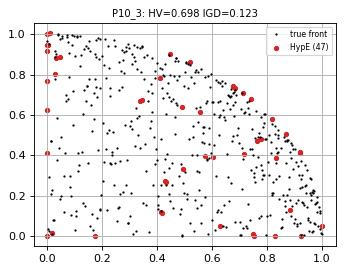

In [41]:
class HypE(MOEA):
    """Steps: 1) mating, offspring  2) sample S points in the box [min F, ref]  3) HypE fitness with weights alpha_c  4) remove the worst in chunks and recompute. N=50, S=2000."""
    Ndef = 50; S = 2000; chunk = 10
    def initialize(s): s.X = s.newpop(s.N); s.F = s.evaluate(s.X)
    def fitness(s, F, k):
        ref = s.p.ref; lo = np.minimum(F.min(0), ref - 1e-6); smp = s.rng.uniform(lo, ref, (s.S, F.shape[1])); dom = (F[None] <= smp[:, None]).all(2); P = len(F); al = np.zeros(P + 1)
        for c in range(1, P + 1):
            a = 1.0
            for j in range(1, c): a *= max(k - j, 0) / (P - j)
            al[c] = a / c
        return (dom * al[dom.sum(1)][:, None]).sum(0) * np.prod(ref - lo) / s.S
    def select(s, F, n):
        act = np.arange(len(F))
        while len(act) > n:
            k = len(act) - n; fit = s.fitness(F[act], k); act = np.delete(act, np.argsort(fit)[:min(s.chunk, k)])
        return act
    def step(s):
        off = s.offspring(s.X[s.rng.permutation(len(s.X))]); XU, FU = np.vstack([s.X, off]), np.vstack([s.F, s.evaluate(off)]); sel = s.select(FU, s.N); s.X, s.F = XU[sel], FU[sel]

def ut_34():
    m = HypE(P10_3, budget=10 ** 6, seed=0, N=10, S=20000); F = np.array([[.1, .1, .1], [.5, .5, .5], [1., 1., 1.]]); fit = m.fitness(F, 1)
    assert fit[1] == 0 and fit[0] > 0                                                     # k=1: only exclusive volume counts, a dominated point has none
A2(34, cls_runner(HypE), unit=ut_34)

#### A2.35 R-NSGA-II
NSGA-II where crowding distance is replaced by closeness to the decision-maker's reference point; ε-clearing keeps near-duplicates out of the preferred region.

[35] R-NSGA-II: unit test passed
  P5: closest front point to reference is 0.018 (normalized)
  P14: closest front point to reference is 0.128 (normalized)


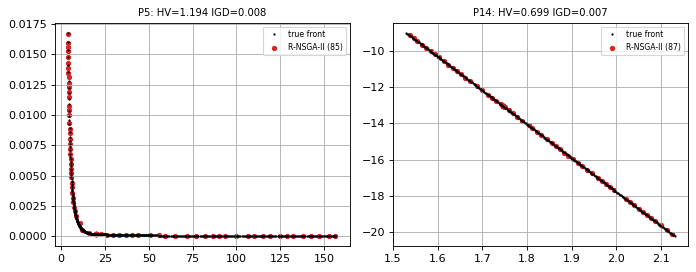

In [42]:
def eps_clear(F, order, eps):
    """Walk the preference order; points closer than eps to an already kept point are moved to the back."""
    left, out, later = list(order), [], []
    while left:
        a = left.pop(0); out.append(a); keep = []
        for b in left: (later if np.linalg.norm(F[a] - F[b]) < eps else keep).append(b)
        left = keep
    return np.array(out + later)

class RNSGA2(NSGA2):
    """NSGA-II with preference: survivors of the last front are ordered by distance to the reference point (normalized), eps-clearing eps=0.02. ref_pt in raw (minimization) units."""
    eps = 0.02; ref_pt = None
    def initialize(s):
        s.zn = s.p.norm(np.asarray(s.ref_pt if s.ref_pt is not None else s.p.pref, float)[None])[0]; NSGA2.initialize(s)
    def survive(s, F, CV, n):
        fr = nds(F); rank = np.zeros(len(F), int); crowd = np.zeros(len(F)); sel = []
        for k, f in enumerate(fr):
            order = eps_clear(F[f], np.argsort(np.linalg.norm(F[f] - s.zn, axis=1)), s.eps); pr = np.empty(len(f)); pr[order] = np.arange(len(f)); rank[f] = k; crowd[f] = -pr
            if len(sel) < n: sel += list(f[order][:n - len(sel)])
        return np.array(sel), rank, crowd

def ut_35():
    F = np.array([[0, 0], [0.001, 0], [1, 1.]]); assert list(eps_clear(F, [0, 1, 2], 0.01)) == [0, 2, 1]       # near-duplicate pushed behind
def run_35(P, s, b):
    a = RNSGA2(P, budget=b, seed=s).run(); Fn = a.result(); d = np.linalg.norm(Fn - a.zn, axis=1); print(f"  {P.name}: closest front point to reference is {d.min():.3f} (normalized)"); return Fn
A2(35, run_35, unit=ut_35)

#### P13 — multi-task learning set-up (used by algorithms 36 and 37)
(a) toy: `f₁=‖x−a‖², f₂=‖x−b‖²`, a=(3,3), b=(−3,−3), start (0,5). (b) shared-body network with a classification head and a regression head (forward/backward by hand).

In [43]:
def min_norm(G):
    """Min-norm point of the convex hull of the rows of G (Frank-Wolfe); alpha on the simplex."""
    M = len(G)
    if M == 2:
        d = G[0] - G[1]; a = np.clip(((G[1] - G[0]) @ G[1]) / (d @ d + 1e-18), 0, 1); return np.array([a, 1 - a])
    a = np.ones(M) / M; Gm = G @ G.T
    for _ in range(3000):
        t = np.argmin(Gm @ a); dd = np.eye(M)[t] - a; den = dd @ Gm @ dd
        if den <= 1e-18: break
        a = a + np.clip(-(dd @ Gm @ a) / den, 0, 1) * dd
    return a

def gradnorm_update(w, L, L0, gn, alpha=1.5, eta=0.01):
    """GradNorm: push each task's weighted gradient norm G_i=w_i*||g_i|| toward mean(G)*r_i^alpha (r_i = relative inverse training rate)."""
    G = w * gn; r = (L / L0) / (L / L0).mean(); tgt = G.mean() * r ** alpha; w = np.clip(w * np.exp(-eta * np.sign(G - tgt)), 0.3, None); return len(w) * w / w.sum()

A_, B_ = np.array([3., 3.]), np.array([-3., -3.])
def toy_run(method, x0=(0., 5.), lr=0.05, iters=150):
    x = np.array(x0); w = np.ones(2); path = [x.copy()]; L0 = np.array([((x - A_) ** 2).sum(), ((x - B_) ** 2).sum()])
    for _ in range(iters):
        g = np.array([2 * (x - A_), 2 * (x - B_)]); L = np.array([((x - A_) ** 2).sum(), ((x - B_) ** 2).sum()])
        if method == "equal": d = g.sum(0)
        elif method == "mgda": d = 2 * (min_norm(g) @ g)
        else: w = gradnorm_update(w, L, L0, np.linalg.norm(g, axis=1)); d = w @ g
        x = x - lr * d; path.append(x.copy())
    return np.array(path)

def make_mtl_data(rng, n=300):
    X = rng.normal(size=(n, 5)); return X, (X[:, 0] + X[:, 1] > 0).astype(float), 20 * (X[:, 2] - .5 * X[:, 3])   # regression target has a large scale

def init_net(rng, h=12): return dict(W1=rng.normal(0, .3, (5, h)), b1=np.zeros(h), wc=rng.normal(0, .3, h), bc=np.zeros(1), wr=rng.normal(0, .3, h), br=np.zeros(1))

def net_grads(P, X, yc, yr):
    """Forward + manual backward: returns losses (cls, reg), shared-body gradients per task, head gradients per task."""
    n = len(X); H = np.tanh(X @ P["W1"] + P["b1"]); pc = 1 / (1 + np.exp(-(H @ P["wc"] + P["bc"][0]))); pr = H @ P["wr"] + P["br"][0]
    Lc = -np.mean(yc * np.log(pc + 1e-12) + (1 - yc) * np.log(1 - pc + 1e-12)); Lr = np.mean((pr - yr) ** 2); dzc, dpr = (pc - yc) / n, 2 * (pr - yr) / n
    sh = lambda dz, w: (lambda dA: np.r_[(X.T @ dA).ravel(), dA.sum(0)])(np.outer(dz, w) * (1 - H ** 2))
    return (Lc, Lr), (sh(dzc, P["wc"]), sh(dpr, P["wr"])), (dict(wc=H.T @ dzc, bc=np.array([dzc.sum()])), dict(wr=H.T @ dpr, br=np.array([dpr.sum()])))

def train_mtl(method, seed=0, epochs=400, lr=0.002):
    rng = np.random.default_rng(seed); X, yc, yr = make_mtl_data(rng); P = init_net(rng); w = np.ones(2); L0 = None; hist = []; h = P["b1"].size
    for _ in range(epochs):
        L, (gc, gr), (hc, hr) = net_grads(P, X, yc, yr); L = np.array(L); L0 = L.copy() if L0 is None else L0; hist.append(L)
        if method == "equal": d = gc + gr
        elif method == "mgda": d = 2 * (min_norm(np.array([gc, gr])) @ np.array([gc, gr]))
        else: w = gradnorm_update(w, L, L0, np.array([np.linalg.norm(gc), np.linalg.norm(gr)])); d = w[0] * gc + w[1] * gr
        P["W1"] -= lr * d[:5 * h].reshape(5, h); P["b1"] -= lr * d[5 * h:]
        sc = w if method == "gradnorm" else np.ones(2)
        for k, v in hc.items(): P[k] -= lr * sc[0] * v
        for k, v in hr.items(): P[k] -= lr * sc[1] * v
    return np.array(hist), w

#### A2.36 MGDA
The min-norm point `d = Σ αᵢ gᵢ` of the convex hull of the task gradients is a common descent direction (d·gᵢ ≥ ‖d‖² for every i); it vanishes at Pareto-stationary points.

[36] MGDA: unit test passed
toy final x — equal: [0. 0.]  MGDA: [2.5 2.5]  GradNorm: [1.224 1.224] (Pareto set: x1 = x2, -3<=x1<=3)


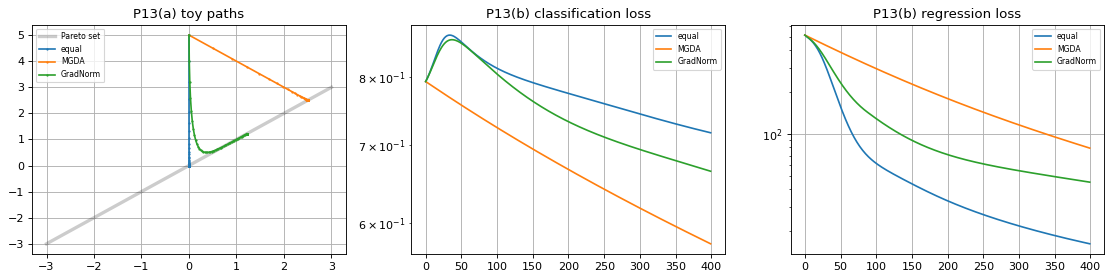

final losses (cls, reg): equal [ 0.717 16.184] | MGDA [ 0.576 79.13 ] | GradNorm [ 0.665 44.984]


In [44]:
def ut_36():
    assert np.allclose(min_norm(np.array([[1., 0], [0, 1.]])), [.5, .5])                    # orthogonal equal-length gradients -> equal weights
    g = np.random.default_rng(0).normal(size=(3, 5)); a = min_norm(g); d = a @ g
    assert abs(a.sum() - 1) < 1e-9 and (g @ d >= d @ d - 1e-3).all()                       # common descent: every task improves at rate >= ||d||^2
    G2 = np.array([[1., 1.], [-1., -1.]]); assert np.allclose(min_norm(G2) @ G2, 0)          # opposite gradients -> d=0 (Pareto stationary)
ut_36(); print("[36] MGDA: unit test passed")
pe, pm_, pg = toy_run("equal"), toy_run("mgda"), toy_run("gradnorm")
print("toy final x — equal:", pe[-1].round(3), " MGDA:", pm_[-1].round(3), " GradNorm:", pg[-1].round(3), "(Pareto set: x1 = x2, -3<=x1<=3)")
hE, _ = train_mtl("equal"); hM, _ = train_mtl("mgda"); hG, wG = train_mtl("gradnorm")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot([-3, 3], [-3, 3], "k-", lw=3, alpha=.2, label="Pareto set")
for pth, lab in ((pe, "equal"), (pm_, "MGDA"), (pg, "GradNorm")): ax[0].plot(pth[:, 0], pth[:, 1], ".-", ms=2, label=lab)
ax[0].set_title("P13(a) toy paths"); ax[0].legend(fontsize=7)
for a_, k, t in ((ax[1], 0, "classification loss"), (ax[2], 1, "regression loss")):
    for h_, lab in ((hE, "equal"), (hM, "MGDA"), (hG, "GradNorm")): a_.semilogy(h_[:, k], label=lab)
    a_.set_title("P13(b) " + t); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
LOG.append(dict(idx=36, name="MGDA", prob="P13", budget=400, hv=np.nan, sp=np.nan, igd=np.nan, rt=0, status="works", n=0))
print("final losses (cls, reg): equal", hE[-1].round(3), "| MGDA", hM[-1].round(3), "| GradNorm", hG[-1].round(3))

#### A2.37 GradNorm
Task weights wᵢ are trained so that the weighted gradient norms `wᵢ‖∇Lᵢ‖` match `mean(G)·rᵢ^α`, balancing tasks with very different gradient scales (α=1.5).

In [45]:
def ut_37():
    w = gradnorm_update(np.ones(2), np.array([1., 1.]), np.array([1., 1.]), np.array([10., 1.]))
    assert w[0] < 1 < w[1] and abs(w.sum() - 2) < 1e-9                                      # large-gradient task is down-weighted, weights keep sum = number of tasks
ut_37(); print("[37] GradNorm: unit test passed")
print("learned GradNorm weights (cls, reg) after training:", wG.round(3), "-> the regression task (huge gradients) is down-weighted" if wG[1] < wG[0] else "")
LOG.append(dict(idx=37, name="GradNorm", prob="P13", budget=400, hv=np.nan, sp=np.nan, igd=np.nan, rt=0, status="works", n=0))

[37] GradNorm: unit test passed
learned GradNorm weights (cls, reg) after training: [1.703 0.297] -> the regression task (huge gradients) is down-weighted


#### A3. Implementation log
One row per algorithm and test problem (fixed seed). HV uses the normalized reference point 1.1; IGD only where the true front is known; `n` = size of the obtained front.

In [46]:
def show_log():
    rows = [(r["idx"], r["name"], r["prob"], r["budget"], f"{r['hv']:.4f}", f"{r['igd']:.4f}", f"{r['sp']:.4f}", f"{r['rt']:.2f}s", r["status"], r["n"])
            for r in sorted(LOG, key=lambda r: (r["idx"], r["prob"]))]
    table(rows, ["#", "Algorithm", "Problem", "Eval budget", "HV", "IGD", "Spacing", "Runtime", "Status", "n"])
show_log()
done = sorted({r["idx"] for r in LOG}); print("algorithms logged:", len(done), "of 37; missing:", sorted(set(range(1, 38)) - set(done)))

| # | Algorithm | Problem | Eval budget | HV | IGD | Spacing | Runtime | Status | n |
|---|---|---|---|---|---|---|---|---|---|
| 1 | Weighted Sum | P1 | 10000 | 1.0065 | 0.0405 | 0.0176 | 0.06s | works | 11 |
| 1 | Weighted Sum | P3 | 10000 | 0.2100 | 0.3543 | nan | 0.18s | works | 2 |
| 1 | Weighted Sum | P4 | 10000 | 0.9046 | 0.0544 | 0.1101 | 0.27s | works | 9 |
| 2 | ε-Constraint | P2 | 10000 | 1.0557 | 0.1114 | 0.1817 | 0.48s | works | 11 |
| 2 | ε-Constraint | P3 | 10000 | 0.4950 | 0.0369 | 0.0388 | 0.60s | works | 11 |
| 2 | ε-Constraint | P5 | 10000 | 1.1370 | 0.0685 | 0.0238 | 2.30s | works | 11 |
| 3 | Benson's Method | P1 | 10000 | 0.9844 | 0.0613 | 0.0686 | 0.25s | works | 12 |
| 3 | Benson's Method | P7 | 10000 | 0.6416 | 0.0422 | 0.0729 | 0.26s | works | 12 |
| 4 | Weight Metric (p-norm, Tchebycheff) | P1 | 10000 | 1.0073 | 0.0560 | 0.0599 | 0.36s | works | 11 |
| 4 | Weight Metric (p-norm, Tchebycheff) | P3 | 10000 | 0.4953 | 0.0357 | 0.0206 | 1.07s | works | 11 |
| 5 | Value Function | P14 | 10000 | 0.5382 | 0.1183 | 0.0002 | 0.22s | works | 3 |
| 5 | Value Function | P4 | 10000 | 0.8317 | 0.1896 | 0.0051 | 0.19s | works | 3 |
| 6 | Goal Programming | P11 | 10000 | 1.2100 | nan | nan | 0.01s | works | 1 |
| 6 | Goal Programming | P7 | 10000 | 0.3407 | 0.3819 | nan | 0.01s | works | 1 |
| 7 | Lexicographic | P11 | 10000 | 1.2100 | nan | nan | 0.01s | works | 1 |
| 7 | Lexicographic | P7 | 10000 | 0.2100 | 0.3524 | nan | 0.01s | works | 2 |
| 8 | TOPSIS | P12/P4 | 0 | nan | nan | nan | 0.00s | works | 5 |
| 9 | VIKOR | P12/P4 | 0 | nan | nan | nan | 0.00s | works | 5 |
| 10 | VEGA | P2 | 10000 | 1.0015 | 0.0896 | 0.0055 | 0.05s | works | 91 |
| 10 | VEGA | P3 | 10000 | 0.1090 | 0.6101 | nan | 0.09s | works | 1 |
| 11 | MOGA | P3 | 10000 | 0.5077 | 0.0237 | 0.0186 | 0.50s | works | 35 |
| 11 | MOGA | P5 | 10000 | 1.1911 | 0.0172 | 0.0242 | 0.48s | works | 53 |
| 12 | NSGA | P5 | 10000 | 1.1913 | 0.0140 | 0.0183 | 0.46s | works | 65 |
| 12 | NSGA | P7 | 10000 | 0.6267 | 0.0441 | 0.0464 | 0.39s | works | 23 |
| 13 | NPGA | P3 | 10000 | 0.4217 | 0.0635 | 0.0309 | 0.97s | works | 23 |
| 13 | NPGA | P5 | 10000 | 1.1915 | 0.0145 | 0.0499 | 1.09s | works | 46 |
| 14 | NSGA-II | P3 | 10000 | 0.5376 | 0.0045 | 0.0042 | 0.87s | works | 100 |
| 14 | NSGA-II | P5 | 10000 | 1.1950 | 0.0062 | 0.0074 | 0.87s | works | 98 |
| 14 | NSGA-II | P6 | 10000 | 1.0200 | 0.0053 | 0.0056 | 0.84s | works | 100 |
| 15 | NSGA-III | P10_3 | 10000 | 0.7330 | 0.0568 | 0.0337 | 1.61s | works | 92 |
| 15 | NSGA-III | P10_5 | 10000 | 1.1525 | 0.2196 | 0.0679 | 2.37s | works | 212 |
| 16 | SPEA2 | P4 | 10000 | 0.9701 | 0.0037 | 0.0048 | 4.02s | works | 130 |
| 16 | SPEA2 | P5 | 10000 | 1.1953 | 0.0043 | 0.0067 | 4.90s | works | 158 |
| 17 | PESA-II | P3 | 10000 | 0.5249 | 0.0108 | 0.0078 | 1.66s | works | 100 |
| 17 | PESA-II | P5 | 10000 | 1.1925 | 0.0119 | 0.0083 | 1.65s | works | 100 |
| 18 | MOEA/D | P10_3 | 10000 | 0.7098 | 0.0737 | 0.0544 | 7.10s | works | 59 |
| 18 | MOEA/D | P3 | 10000 | 0.5384 | 0.0038 | 0.0024 | 7.15s | works | 100 |
| 19 | MOEA/D-DE | P3 | 10000 | 0.5355 | 0.0044 | 0.0025 | 5.87s | works | 98 |
| 19 | MOEA/D-DE | P5 | 10000 | 1.1926 | 0.0666 | 0.0829 | 5.69s | works | 100 |
| 20 | MOEA/D-ACO | P8 | 10000 | 0.4856 | nan | 0.1589 | 7.54s | works | 3 |
| 21 | Constrained NSGA-II | P5 | 10000 | 1.1950 | 0.0062 | 0.0074 | 0.52s | works | 98 |
| 21 | Constrained NSGA-II | P6 | 10000 | 1.0201 | 0.0050 | 0.0050 | 0.51s | works | 99 |
| 21 | Constrained NSGA-II | P7 | 10000 | 0.7000 | 0.0056 | 0.0048 | 0.57s | works | 98 |
| 22 | MOPSO | P4 | 10000 | 0.9653 | 0.0071 | 0.0069 | 0.75s | works | 100 |
| 22 | MOPSO | P5 | 10000 | 1.1944 | 0.0083 | 0.0086 | 0.77s | works | 100 |
| 23 | MOGWO | P5 | 10000 | 1.1927 | 0.0121 | 0.0092 | 0.59s | works | 100 |
| 23 | MOGWO | P9 | 10000 | 1.1802 | nan | 0.0330 | 19.16s | works | 7 |
| 24 | MOABC | P3 | 10000 | 0.4509 | 0.0513 | 0.0789 | 0.29s | works | 21 |
| 24 | MOABC | P6 | 10000 | 1.0180 | 0.0069 | 0.0078 | 0.75s | works | 100 |
| 25 | MOACO | P8 | 10000 | 0.7088 | nan | 0.1196 | 5.68s | works | 8 |
| 26 | MOSA | P3 | 10000 | 0.4497 | 0.0737 | 0.0723 | 0.22s | works | 25 |
| 26 | MOSA | P5 | 10000 | 1.1947 | 0.0077 | 0.0093 | 0.67s | works | 100 |
| 27 | MODE | P3 | 10000 | 0.1100 | 0.6097 | nan | 0.14s | works | 1 |
| 27 | MODE | P5 | 10000 | 1.1814 | 0.0308 | 0.0164 | 0.17s | works | 82 |
| 28 | MO-TLBO | P3 | 10000 | 0.5304 | 0.0101 | 0.0112 | 0.29s | works | 50 |
| 28 | MO-TLBO | P5 | 10000 | 1.1932 | 0.0129 | 0.0149 | 0.30s | works | 50 |
| 29 | MOBA | P3 | 10000 | 0.1773 | 0.3863 | 0.0036 | 0.38s | works | 100 |
| 29 | MOBA | P4 | 10000 | 0.9580 | 0.0141 | 0.0068 | 1.35s | works | 100 |
| 30 | MOMA | P5 | 10000 | 1.1949 | 0.0061 | 0.0067 | 0.38s | works | 100 |
| 30 | MOMA | P9 | 10000 | 1.1896 | nan | 0.0289 | 20.31s | works | 6 |
| 31 | RVEA | P10_3 | 10000 | 0.7204 | 0.0621 | 0.0243 | 0.21s | works | 80 |
| 31 | RVEA | P10_5 | 10000 | 1.2118 | 0.2095 | 0.0493 | 0.20s | works | 200 |
| 32 | IBEA | P14 | 10000 | 0.7042 | 0.0041 | 0.0030 | 0.52s | works | 92 |
| 32 | IBEA | P3 | 10000 | 0.5369 | 0.0093 | 0.0149 | 0.51s | works | 83 |
| 33 | SMS-EMOA | P14 | 10000 | 0.7049 | 0.0036 | 0.0010 | 12.03s | works | 100 |
| 33 | SMS-EMOA | P3 | 10000 | 0.5389 | 0.0044 | 0.0049 | 12.77s | works | 100 |
| 34 | HypE | P10_3 | 10000 | 0.6982 | 0.1226 | 0.0761 | 6.82s | works | 47 |
| 35 | R-NSGA-II | P14 | 10000 | 0.6986 | 0.0066 | 0.0106 | 2.24s | works | 87 |
| 35 | R-NSGA-II | P5 | 10000 | 1.1945 | 0.0076 | 0.0104 | 2.74s | works | 85 |
| 36 | MGDA | P13 | 400 | nan | nan | nan | 0.00s | works | 0 |
| 37 | GradNorm | P13 | 400 | nan | nan | nan | 0.00s | works | 0 |


algorithms logged: 37 of 37; missing: []


### Task B — Master comparison table with evidence
Rows are grouped by family. `Evidence` is filled automatically from the A2 runs (HV / IGD / Spacing / runtime) — cite these numbers (and the figure of the A2 cell) next to at least two advantages and two disadvantages when you write the report.

In [47]:
B = {  # idx: (what it does, [4 advantages], [4 disadvantages], best choice, avoid)
 1: ("Minimize w·f for a sweep of weights", ["simple, any solver", "one cheap scalar solve per point", "exact points on convex fronts", "scales to many objectives per solve"],
     ["misses non-convex regions", "equal weight steps give uneven spacing", "needs objective scaling", "no diversity control, many solves"], "convex/linear problems (P1, P4, P7)", "non-convex or disconnected fronts (P3)"),
 2: ("Minimize one objective with the others bounded by ε, sweep ε", ["reaches non-convex fronts", "ε grid controls spacing", "handles constraints naturally", "one objective per solve"],
     ["needs ε ranges (ideal/nadir)", "infeasible ε fail", "grid grows as k^(M-1)", "may return weakly Pareto points"], "non-convex bi-objective with known ranges (P3, P5)", "many objectives (grid explosion)"),
 3: ("Maximize improvement over a feasible reference point", ["always dominates the start point", "finds non-convex points", "no weights", "any feasible start works"],
     ["result depends on the start point", "extra variables/constraints", "points cluster near x0", "needs many starts for coverage"], "improving an existing design", "when an even front is needed"),
 4: ("Minimize weighted distance to the ideal point (p=1,2,∞)", ["p=∞ reaches non-convex fronts", "p tunes the compromise", "weights give DM control", "every Pareto point reachable (p=∞)"],
     ["needs the ideal point", "p=∞ is non-smooth (epigraph)", "p=1 equals weighted sum", "Tchebycheff may give weak Pareto points"], "non-convex fronts with DM weights (P3)", "when no ideal point is available"),
 5: ("Maximize the decision-maker's utility", ["one preferred answer", "single fast solve", "encodes trade-offs directly", "any smooth solver"],
     ["utility hard to elicit", "wrong utility gives wrong answer silently", "no picture of the trade-off", "local solvers can be trapped"], "DM with a known utility (P4, P14)", "exploration with unknown preferences"),
 6: ("Targets with deviation variables d⁻, d⁺, minimize weighted deviations", ["natural for target-driven DMs", "an LP for linear goals", "reports shortfalls explicitly", "handles unattainable goals"],
     ["depends on targets and weights", "deviations need normalization", "can return dominated solutions", "no front"], "target planning (P11, P7)", "when targets are unknown"),
 7: ("Optimize objectives in strict priority order", ["simple logic", "sequence of cheap LPs", "no weights", "ties broken by later priorities"],
     ["lower priorities ignored unless ties", "very tolerance-sensitive", "single solution", "strict priority is rarely realistic"], "clear priority order (P11)", "balanced trade-offs"),
 8: ("Rank alternatives by closeness to ideal and anti-ideal", ["no optimizer needed", "cheap", "easy to explain", "mixed min/max criteria"],
     ["not an optimizer", "rank reversal possible", "compensatory: bad criterion can be masked", "weight- and normalization-dependent"], "ranking a finite front or supplier list (P12)", "generating solutions"),
 9: ("Compromise ranking from S, R, Q with parameter v", ["explicit compromise via v", "regret term protects against a very bad criterion", "acceptability checks", "cheap"],
     ["not an optimizer", "depends on weights and v", "Q depends on the candidate set", "compromise may be non-unique"], "risk-averse supplier choice (P12)", "generating solutions"),
 10: ("Sub-populations each selected by one objective", ["simplest MOEA", "no sorting needed", "binary/real/perm encodings", "illustrates population search"],
     ["collapses to the extremes", "no diversity mechanism", "non-elitist", "middle of the front under-represented"], "teaching / baseline", "any serious front approximation"),
 11: ("Rank = dominators+1, fitness sharing", ["Pareto ranking reaches non-convex fronts", "sharing preserves spread", "simple fitness", "any encoding"],
     ["σ_share must be tuned", "non-elitist", "O(N²) sharing", "rank ties flatten selection pressure"], "small bi-objective problems", "many objectives, tight budgets"),
 12: ("Non-dominated fronts with sharing inside each front", ["explicit front layering", "sharing inside fronts", "non-convex fronts", "historic baseline"],
     ["O(MN³) sorting", "σ_share tuning", "non-elitist", "slower than NSGA-II"], "baseline comparison", "large populations"),
 13: ("Pareto tournament vs a comparison set, niche-count tiebreak", ["cheap O(N·t_dom) selection", "no explicit ranking", "non-convex capable", "niching via counts"],
     ["needs t_dom and σ", "noisy tournaments", "non-elitist", "weak with many objectives"], "low-cost bi-objective runs", "many objectives"),
 14: ("Fast non-dominated sort, crowding distance, elitism", ["elitist", "O(MN²) sorting", "parameter-free diversity", "strong default for 2-3 objectives"],
     ["crowding fails for 4+ objectives", "most points non-dominated when M is large", "ignores local geometry", "favours boundaries"], "default for M ≤ 3 (P3, P5, P6)", "M ≥ 5"),
 15: ("Reference points replace crowding distance", ["scales to many objectives", "uniform spread", "elitist", "adaptive normalization"],
     ["population tied to reference points", "empty niches on irregular fronts", "more complex code", "sensitive to divisions p"], "many-objective with regular fronts (P10)", "irregular/degenerate fronts"),
 16: ("Strength + raw fitness + k-th neighbour density, fixed archive", ["fine-grained fitness", "truncation keeps boundaries", "elitist", "good spread"],
     ["O(N² log N) per generation", "k-th neighbour cost", "archive size parameter", "weaker for many objectives"], "bi/tri-objective with spread priority (P4, P5)", "large many-objective"),
 17: ("Grid regions of the archive, region-based selection", ["cheap grid density", "small internal population", "region selection spreads search", "elitist archive"],
     ["grid divisions to tune", "moving grid bounds", "cells grow as div^M", "depends on archive size"], "low-dimensional objective spaces", "M ≥ 5"),
 18: ("Many Tchebycheff sub-problems with neighbour cooperation", ["cheap O(N·T) per generation", "neighbours share information", "uniform spread with good weights", "scales to many objectives"],
     ["weights must match front shape", "T, δ, nr sensitivity", "poor on disconnected fronts", "needs ideal point z*"], "regular fronts, many objectives (P3, P10)", "disconnected or degenerate fronts"),
 19: ("MOEA/D with DE/rand/1 variation", ["DE handles complicated Pareto sets", "few operators", "good with variable linkage", "keeps decomposition efficiency"],
     ["real-valued only", "F, CR to tune", "diversity loss if nr large", "needs bound repair"], "continuous problems with linkage (P5)", "discrete encodings"),
 20: ("MOEA/D with ant-colony route construction", ["constructive search suits routing", "neighbour pheromone sharing", "native permutations", "no crossover repair"],
     ["N·n² pheromone memory", "many ACO parameters", "slow per evaluation", "only constructive problems"], "TSP/routing (P8)", "continuous problems"),
 21: ("NSGA-II with Deb's feasibility rules", ["no penalty parameters", "cheap rules", "elitist, spread preserved", "works with narrow feasible sets"],
     ["infeasible diversity lost", "needs a CV scale", "can stall on disconnected feasible regions", "infeasible-only starts drift to least violation"], "constrained design (P5, P6)", "unconstrained problems (no benefit)"),
 22: ("Particles guided by personal best and archive leader", ["fast convergence", "few parameters", "archive leader selection", "easy real coding"],
     ["premature convergence", "grid parameters", "needs relaxation for discrete", "needs velocity clamping"], "smooth continuous problems (P4)", "discrete or deceptive problems"),
 23: ("α, β, δ leaders from the archive, encircling", ["few parameters", "archive-guided leaders", "exploration→exploitation by a", "simple"],
     ["diversity depends on leader choice", "late exploitation only", "continuous only", "can cluster"], "quick continuous problems (P5)", "discrete problems"),
 24: ("Employed, onlooker, scout bees with dominance greedy choice", ["few parameters", "scouts restore diversity", "one-dimension local search", "greedy dominance"],
     ["slow convergence", "greedy rule discards non-dominated moves", "2N evaluations/iteration", "limit tuning"], "multimodal continuous (P3, P6)", "tight budgets"),
 25: ("Two pheromone matrices, probabilistic route construction", ["natural for routing", "two matrices encode objectives", "archive deposits", "no crossover repair"],
     ["O(n²) memory", "slow iterations", "α, β, ρ tuning", "pheromone stagnation"], "routing/graph problems (P8)", "continuous problems"),
 26: ("Neighbour moves, Boltzmann acceptance, cooling", ["very low memory", "simple", "escapes local optima", "any encoding"],
     ["cooling schedule tuning", "chains cooperate weakly", "slow in many variables", "needs weights for energy"], "memory-limited, rugged problems", "tight budgets"),
 27: ("DE mutation/crossover; trial replaces target only if it dominates", ["few parameters", "strong on continuous", "self-scaling steps", "simple replacement"],
     ["no diversity operator", "F, CR to tune", "continuous only", "stalls if no trial dominates"], "continuous problems with smooth fronts", "need for even spread"),
 28: ("Teacher and learner phases, shrinking teaching factor", ["no algorithm-specific parameters", "two complementary phases", "elitist merge", "simple"],
     ["2N evaluations/generation", "teacher choice biases", "continuous only", "mean move can collapse diversity"], "parameter-light continuous runs", "discrete problems"),
 29: ("Frequency-driven velocity, loudness and pulse-rate schedules", ["adaptive explore→exploit", "simple updates", "archive guidance", "fast convergence"],
     ["many parameters", "leader dependence", "may stagnate", "needs mapping for discrete"], "smooth continuous (P3, P4)", "discrete problems"),
 30: ("NSGA-II global search plus hill-climbing", ["local search sharpens convergence", "NSGA-II diversity", "any encoding with a neighbour move", "fewer generations needed"],
     ["extra evaluations", "more parameters", "premature convergence risk", "neighbour step scale matters"], "mixed global/local landscapes (P5, P9)", "very tight budgets"),
 31: ("Angle-penalized distance with adaptive reference vectors", ["balances convergence/diversity over time", "scales to many objectives", "adaptive vectors", "elitist"],
     ["population can shrink", "needs total generations", "α, fr parameters", "scaling issues on irregular fronts"], "many-objective (P10)", "irregular fronts"),
 32: ("ε-indicator fitness, no diversity step", ["no diversity operator", "any indicator plugs in", "simple fitness", "good for many objectives"],
     ["κ sensitive", "O(N²) fitness", "indicator bias", "needs scaled objectives"], "bi/many-objective with scaled objectives (P14)", "unscaled objectives"),
 33: ("Steady-state, discard the least hypervolume contributor", ["excellent spread and convergence", "steady-state", "monotone hypervolume", "great for 2-3 objectives"],
     ["HV costly for 4+ objectives", "reference-point sensitive", "serial evaluations", "slow wall-clock"], "2-3 objectives, quality first (P3, P14)", "M ≥ 5"),
 34: ("Monte-Carlo hypervolume-contribution fitness", ["scales HV to many objectives", "time controllable via samples", "no diversity operator", "works for M ≥ 5"],
     ["sampling noise", "S tuning", "chunk removal is approximate", "slow for small M"], "many objectives with indicator quality (P10)", "tiny budgets"),
 35: ("NSGA-II with reference-point preference and ε-clearing", ["focuses on the DM region", "saves evaluations", "ε-clearing keeps spread", "reuses NSGA-II"],
     ["wrong reference misguides search", "ε needs tuning", "no global front", "DM must provide a point"], "DM with a target (P5, P14)", "no preference information"),
 36: ("Min-norm combination of gradients = common descent direction", ["no weights", "guaranteed common descent", "stops at Pareto-stationary points", "cheap for 2 tasks"],
     ["needs gradients", "local only", "QP cost grows with tasks", "favours small-gradient tasks"], "differentiable multi-task learning (P13)", "non-differentiable problems"),
 37: ("Adaptive task weights from gradient norms", ["balances gradient scales", "learns weights online", "cheap", "works in deep nets"],
     ["needs shared-layer gradient norms", "α and weight-lr to tune", "weights can hit the floor", "heuristic, no Pareto guarantee"], "tasks with very different scales (P13)", "non-differentiable problems"),
}
assert len(B) == 37 and all(len(v[1]) >= 4 and len(v[2]) >= 4 for v in B.values())

def evidence(idx):
    rs = [r for r in LOG if r["idx"] == idx]
    if not rs: return "-"
    return "; ".join(f"{r['prob']}: HV {r['hv']:.3f}" + ("" if np.isnan(r['igd']) else f", IGD {r['igd']:.3f}") + ("" if np.isnan(r['sp']) else f", Sp {r['sp']:.3f}") + f", {r['rt']:.1f}s" for r in rs if not np.isnan(r["hv"]))
for fam in dict.fromkeys(FAMILY.values()):
    display(Markdown(f"**{fam}**"))
    table([(i, NAME[i], B[i][0], "; ".join(B[i][1]), "; ".join(B[i][2]), B[i][3], B[i][4], evidence(i)) for i in range(1, 38) if FAMILY[i] == fam],
          ["#", "Algorithm", "What it does", "Advantages", "Disadvantages", "Best choice", "Avoid", "Evidence (own runs)"])

**Classical**

| # | Algorithm | What it does | Advantages | Disadvantages | Best choice | Avoid | Evidence (own runs) |
|---|---|---|---|---|---|---|---|
| 1 | Weighted Sum | Minimize w·f for a sweep of weights | simple, any solver; one cheap scalar solve per point; exact points on convex fronts; scales to many objectives per solve | misses non-convex regions; equal weight steps give uneven spacing; needs objective scaling; no diversity control, many solves | convex/linear problems (P1, P4, P7) | non-convex or disconnected fronts (P3) | P1: HV 1.006, IGD 0.040, Sp 0.018, 0.1s; P3: HV 0.210, IGD 0.354, 0.2s; P4: HV 0.905, IGD 0.054, Sp 0.110, 0.3s |
| 2 | ε-Constraint | Minimize one objective with the others bounded by ε, sweep ε | reaches non-convex fronts; ε grid controls spacing; handles constraints naturally; one objective per solve | needs ε ranges (ideal/nadir); infeasible ε fail; grid grows as k^(M-1); may return weakly Pareto points | non-convex bi-objective with known ranges (P3, P5) | many objectives (grid explosion) | P2: HV 1.056, IGD 0.111, Sp 0.182, 0.5s; P3: HV 0.495, IGD 0.037, Sp 0.039, 0.6s; P5: HV 1.137, IGD 0.069, Sp 0.024, 2.3s |
| 3 | Benson's Method | Maximize improvement over a feasible reference point | always dominates the start point; finds non-convex points; no weights; any feasible start works | result depends on the start point; extra variables/constraints; points cluster near x0; needs many starts for coverage | improving an existing design | when an even front is needed | P1: HV 0.984, IGD 0.061, Sp 0.069, 0.3s; P7: HV 0.642, IGD 0.042, Sp 0.073, 0.3s |
| 4 | Weight Metric (p-norm, Tchebycheff) | Minimize weighted distance to the ideal point (p=1,2,∞) | p=∞ reaches non-convex fronts; p tunes the compromise; weights give DM control; every Pareto point reachable (p=∞) | needs the ideal point; p=∞ is non-smooth (epigraph); p=1 equals weighted sum; Tchebycheff may give weak Pareto points | non-convex fronts with DM weights (P3) | when no ideal point is available | P1: HV 1.007, IGD 0.056, Sp 0.060, 0.4s; P3: HV 0.495, IGD 0.036, Sp 0.021, 1.1s |
| 5 | Value Function | Maximize the decision-maker's utility | one preferred answer; single fast solve; encodes trade-offs directly; any smooth solver | utility hard to elicit; wrong utility gives wrong answer silently; no picture of the trade-off; local solvers can be trapped | DM with a known utility (P4, P14) | exploration with unknown preferences | P4: HV 0.832, IGD 0.190, Sp 0.005, 0.2s; P14: HV 0.538, IGD 0.118, Sp 0.000, 0.2s |
| 6 | Goal Programming | Targets with deviation variables d⁻, d⁺, minimize weighted deviations | natural for target-driven DMs; an LP for linear goals; reports shortfalls explicitly; handles unattainable goals | depends on targets and weights; deviations need normalization; can return dominated solutions; no front | target planning (P11, P7) | when targets are unknown | P11: HV 1.210, 0.0s; P7: HV 0.341, IGD 0.382, 0.0s |
| 7 | Lexicographic | Optimize objectives in strict priority order | simple logic; sequence of cheap LPs; no weights; ties broken by later priorities | lower priorities ignored unless ties; very tolerance-sensitive; single solution; strict priority is rarely realistic | clear priority order (P11) | balanced trade-offs | P11: HV 1.210, 0.0s; P7: HV 0.210, IGD 0.352, 0.0s |


**Ranking/MCDM**

| # | Algorithm | What it does | Advantages | Disadvantages | Best choice | Avoid | Evidence (own runs) |
|---|---|---|---|---|---|---|---|
| 8 | TOPSIS | Rank alternatives by closeness to ideal and anti-ideal | no optimizer needed; cheap; easy to explain; mixed min/max criteria | not an optimizer; rank reversal possible; compensatory: bad criterion can be masked; weight- and normalization-dependent | ranking a finite front or supplier list (P12) | generating solutions |  |
| 9 | VIKOR | Compromise ranking from S, R, Q with parameter v | explicit compromise via v; regret term protects against a very bad criterion; acceptability checks; cheap | not an optimizer; depends on weights and v; Q depends on the candidate set; compromise may be non-unique | risk-averse supplier choice (P12) | generating solutions |  |


**Non-elitist EA**

| # | Algorithm | What it does | Advantages | Disadvantages | Best choice | Avoid | Evidence (own runs) |
|---|---|---|---|---|---|---|---|
| 10 | VEGA | Sub-populations each selected by one objective | simplest MOEA; no sorting needed; binary/real/perm encodings; illustrates population search | collapses to the extremes; no diversity mechanism; non-elitist; middle of the front under-represented | teaching / baseline | any serious front approximation | P2: HV 1.001, IGD 0.090, Sp 0.005, 0.1s; P3: HV 0.109, IGD 0.610, 0.1s |
| 11 | MOGA | Rank = dominators+1, fitness sharing | Pareto ranking reaches non-convex fronts; sharing preserves spread; simple fitness; any encoding | σ_share must be tuned; non-elitist; O(N²) sharing; rank ties flatten selection pressure | small bi-objective problems | many objectives, tight budgets | P3: HV 0.508, IGD 0.024, Sp 0.019, 0.5s; P5: HV 1.191, IGD 0.017, Sp 0.024, 0.5s |
| 12 | NSGA | Non-dominated fronts with sharing inside each front | explicit front layering; sharing inside fronts; non-convex fronts; historic baseline | O(MN³) sorting; σ_share tuning; non-elitist; slower than NSGA-II | baseline comparison | large populations | P5: HV 1.191, IGD 0.014, Sp 0.018, 0.5s; P7: HV 0.627, IGD 0.044, Sp 0.046, 0.4s |
| 13 | NPGA | Pareto tournament vs a comparison set, niche-count tiebreak | cheap O(N·t_dom) selection; no explicit ranking; non-convex capable; niching via counts | needs t_dom and σ; noisy tournaments; non-elitist; weak with many objectives | low-cost bi-objective runs | many objectives | P3: HV 0.422, IGD 0.064, Sp 0.031, 1.0s; P5: HV 1.192, IGD 0.015, Sp 0.050, 1.1s |


... (22 outputs left out)

**Preference-based**

| # | Algorithm | What it does | Advantages | Disadvantages | Best choice | Avoid | Evidence (own runs) |
|---|---|---|---|---|---|---|---|
| 35 | R-NSGA-II | NSGA-II with reference-point preference and ε-clearing | focuses on the DM region; saves evaluations; ε-clearing keeps spread; reuses NSGA-II | wrong reference misguides search; ε needs tuning; no global front; DM must provide a point | DM with a target (P5, P14) | no preference information | P5: HV 1.194, IGD 0.008, Sp 0.010, 2.7s; P14: HV 0.699, IGD 0.007, Sp 0.011, 2.2s |


**Gradient-based**

| # | Algorithm | What it does | Advantages | Disadvantages | Best choice | Avoid | Evidence (own runs) |
|---|---|---|---|---|---|---|---|
| 36 | MGDA | Min-norm combination of gradients = common descent direction | no weights; guaranteed common descent; stops at Pareto-stationary points; cheap for 2 tasks | needs gradients; local only; QP cost grows with tasks; favours small-gradient tasks | differentiable multi-task learning (P13) | non-differentiable problems |  |
| 37 | GradNorm | Adaptive task weights from gradient norms | balances gradient scales; learns weights online; cheap; works in deep nets | needs shared-layer gradient norms; α and weight-lr to tune; weights can hit the floor; heuristic, no Pareto guarantee | tasks with very different scales (P13) | non-differentiable problems |  |


**How the families differ.** *Classical* methods turn the problem into single-objective solves: they are fast and exact when their assumptions hold (weighted sum needs convexity, ε-constraint and Tchebycheff do not) but produce one point per solve, so diversity is whatever the weight/ε grid gives. *Non-elitist EAs* (VEGA, MOGA, NSGA, NPGA) use a population and obtain diversity from sharing or niching, but without elitism they lose good points and converge slowly; VEGA has no diversity at all and drifts to the extremes. *Elitist Pareto EAs* (NSGA-II, SPEA2, PESA-II) keep the best set and use crowding, density or grid counts for diversity; they handle non-convex fronts but their diversity measures degrade as M grows. *Decomposition* (MOEA/D family) gets diversity from the weight vectors and is cheap, but depends on the weights matching the front shape. *Many-objective and indicator methods* (NSGA-III, RVEA, IBEA, SMS-EMOA, HypE) replace crowding by reference points/vectors or indicator contributions, which keeps selection pressure when most solutions are mutually non-dominated. *Metaheuristics* (swarm, SA, DE, TLBO, BA) mainly differ in the variation operator; diversity comes from an archive (grid) and constraints from penalties unless Deb's rules are used (alg. 21). *Gradient methods* (MGDA, GradNorm) need differentiability and are local, but are the only ones that scale to millions of parameters. For constraints: Deb's rules (21) avoid penalty tuning; for non-convex fronts, Pareto-based, ε-constraint and Tchebycheff approaches work while weighted sum cannot.

### Task C — Deep dive on your three assigned algorithms
Set `ROLL` to the last two digits of your registration number. The three algorithms are `((R−1) mod 37)+1`, `((R+11) mod 37)+1`, `((R+23) mod 37)+1`.
Each needs: C1 study card (write it in your own words — template below), C2 hand trace reproduced by code, C3 sensitivity study (3 values × seeds).

In [48]:
ROLL = 44                                             # <-- set your roll number (00-99); R=7 gives algorithms 7, 19, 31
DEEP = [((ROLL - 1) % 37) + 1, ((ROLL + 11) % 37) + 1, ((ROLL + 23) % 37) + 1]
assert [((7 - 1) % 37) + 1, ((7 + 11) % 37) + 1, ((7 + 23) % 37) + 1] == [7, 19, 31]       # example from the PDF
assert [((0 - 1) % 37) + 1, ((0 + 11) % 37) + 1, ((0 + 23) % 37) + 1] == [37, 12, 24]      # R=00 example
assert [((99 - 1) % 37) + 1, ((99 + 11) % 37) + 1, ((99 + 23) % 37) + 1] == [25, 37, 12]   # R=99 example
print("Deep-dive algorithms:", [(i, NAME[i]) for i in DEEP])

CLS = {10: VEGA, 11: MOGA, 12: NSGA, 13: NPGA, 14: NSGA2, 15: NSGA3, 16: SPEA2, 17: PESA2, 18: MOEAD, 19: MOEADDE, 20: MOEAD_ACO, 21: CNSGA2,
       22: MOPSO, 23: MOGWO, 24: MOABC, 25: MOACO, 26: MOSA, 27: MODE, 28: MOTLBO, 29: MOBA, 30: MOMA, 31: RVEA, 32: IBEA, 33: SMSEMOA, 34: HypE, 35: RNSGA2}
for i in DEEP:                                        # docstrings = steps + default parameters (reuse in the study card)
    print(f"\n[{i}] {NAME[i]} — {FAMILY[i]}"); print("   ", (CLS[i].__doc__ if i in CLS else "classical / gradient method: see its cell above").strip())

Deep-dive algorithms: [(7, 'Lexicographic'), (19, 'MOEA/D-DE'), (31, 'RVEA')]

[7] Lexicographic — Classical
    classical / gradient method: see its cell above

[19] MOEA/D-DE — Decomposition
    MOEA/D with DE/rand/1 variation: v = x_r1 + F (x_r2 - x_r3), binomial crossover CR=1, then polynomial mutation. F=0.5.

[31] RVEA — Many-objective
    Steps: 1) reference vectors (Das-Dennis)  2) random mating  3) translate by ideal, assign by angle  4) APD=(1+M(t/T)^a * theta/gamma)*||f||, best per vector  5) adapt vectors every fr*T gens. alpha=2, fr=0.1.


#### C1. Study card (fill in your own words)
| Field | Your entry |
|---|---|
| Full form, year, authors, problem it fixed | |
| Core idea (≤ 5 lines) + flow diagram | |
| Numbered steps with formulas | |
| Parameters: effect if too small / too large | |
| Convergence · diversity · constraints · non-convex fronts · > 3 objectives | |
| Time complexity per generation / per solve | |

#### C2. Hand trace
The code prints two full iterations on a tiny instance (population 4 on P1, or two weight/ε settings for classical methods). Do the same two iterations by hand and compare every number.

In [49]:
def hand_trace(idx):
    np.set_printoptions(precision=4, suppress=True); print(f"===== Hand trace of [{idx}] {NAME[idx]} =====")
    if idx in CLS:
        P = P8 if idx in (20, 25) else P1; a = CLS[idx](P, budget=10 ** 6, seed=0, N=4) if idx not in (15, 31) else CLS[idx](P, budget=10 ** 6, seed=0, div=3)
        for g in range(3):
            if g: a.step(); a.gen += 1
            print(f"-- generation {g} ({'initial' if g == 0 else 'after step'}): x ->  objectives (normalized)")
            for x, f in zip(a.X[:6], a.F[:6]): print("   ", np.asarray(x).round(3).ravel() if P is P1 else list(map(int, x))[:8], "->", f)
    else:
        tr = {1: lambda: weighted_sum(P1, 0, 2), 2: lambda: eps_constraint(P1, 0, 2), 3: lambda: benson(P1, 0, 2), 4: lambda: weight_metric(P1, 0, np.inf, 2),
              5: lambda: value_function(P1, 0, (0.3, 0.7))}
        if idx in tr:
            X = tr[idx](); print("two settings -> x:", X.ravel(), " objectives:", P1.f(X)[0].round(4).tolist())
        elif idx == 6: print("goal programming (targets 2400, 600):", [goal_programming(P11.lin, [2400, 600], w)[0] for w in ([1, 1], [1, 3])])
        elif idx == 7: print("lexicographic orders:", lexicographic(P11.lin, [0, 1]), lexicographic(P11.lin, [1, 0]))
        elif idx in (8, 9):
            M = np.array([[1., 10.], [2., 5.], [3., 1.]]); w = np.array([.5, .5]); bn = np.array([False, True]); print("3 alternatives:", M.tolist())
            print("TOPSIS closeness:" if idx == 8 else "VIKOR Q:", (topsis(M, w, bn) if idx == 8 else vikor(M, w, bn)).round(4))
        else:
            print("toy path, first 3 steps:", toy_run("mgda" if idx == 36 else "gradnorm")[:4].tolist())
for i in DEEP: hand_trace(i)

===== Hand trace of [7] Lexicographic =====
lexicographic orders: [300. 200.] [300. 200.]
===== Hand trace of [19] MOEA/D-DE =====
-- generation 0 (initial): x ->  objectives (normalized)
    [6.733] -> [0.8708 0.0045]
    [3.428] -> [0.0115 0.7974]
    [1.369] -> [0.1663 1.9819]
    [1.149] -> [0.2142 2.1398]
-- generation 1 (after step): x ->  objectives (normalized)
    [7.041] -> [1.0205 0.0001]
    [6.001] -> [0.5628 0.0624]
    [3.921] -> [0.053  0.5926]
    [3.921] -> [0.053  0.5926]
-- generation 2 (after step): x ->  objectives (normalized)
    [7.041] -> [1.0205 0.0001]
    [5.127] -> [0.2828 0.2192]
    [5.127] -> [0.2828 0.2192]
    [3.921] -> [0.053  0.5926]
===== Hand trace of [31] RVEA =====
-- generation 0 (initial): x ->  objectives (normalized)
    [6.733] -> [0.8708 0.0045]
    [3.428] -> [0.0115 0.7974]
    [1.369] -> [0.1663 1.9819]
    [1.149] -> [0.2142 2.1398]
-- generation 1 (after step): x ->  objectives (normalized)
    [3.428] -> [0.0115 0.7974]
    [6.733] 

#### C3. Sensitivity study
Most important parameter of each deep-dive algorithm at three values, evaluated over the seeds in `RUNS` (10 in FULL mode). Mean ± std of HV on the algorithm's test problem.

[7] Lexicographic is a deterministic method: vary its input parameter and compare the outputs
  tolerance 0.0 -> x = [70. 20.]
  tolerance 0.05 -> x = [66.5 23.5]
  tolerance 0.2 -> x = [56. 34.]


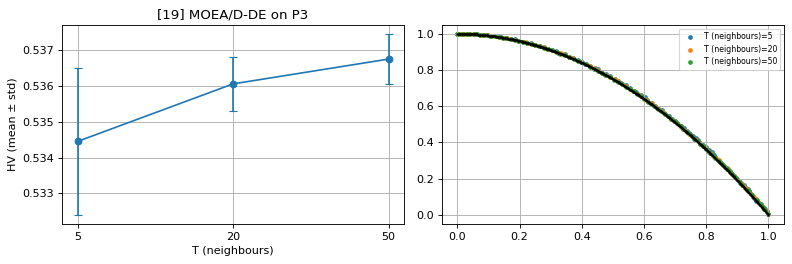

| T (neighbours) | HV | Spacing | IGD |
|---|---|---|---|
| 5 | 0.5344 ± 0.0020 | 0.0034 | 0.0049 |
| 20 | 0.5361 ± 0.0008 | 0.0031 | 0.0044 |
| 50 | 0.5368 ± 0.0007 | 0.0032 | 0.0042 |


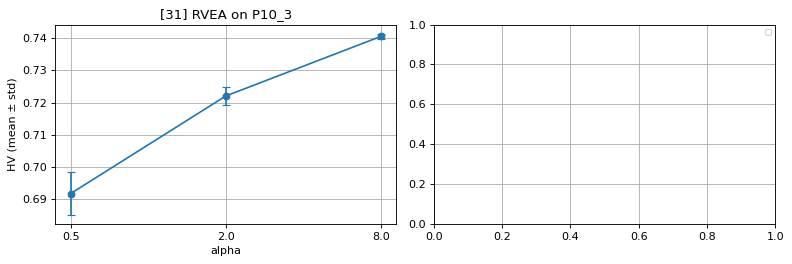

| alpha | HV | Spacing | IGD |
|---|---|---|---|
| 0.5 | 0.6916 ± 0.0066 | 0.0255 | 0.0735 |
| 2.0 | 0.7220 ± 0.0028 | 0.0252 | 0.0612 |
| 8.0 | 0.7406 ± 0.0008 | 0.0271 | 0.0563 |


In [50]:
def mk(cls, **kw): return lambda P, s, b: cls(P, budget=b, seed=s, **kw).run().result()
SENS = {  # idx: (parameter, values, factory(value)->runner, problem)
 1: ("n_weights", [3, 6, 11], lambda v: (lambda P, s, b: finalize(P, weighted_sum(P, s, v))), "P4"),
 2: ("n_eps", [3, 6, 11], lambda v: (lambda P, s, b: finalize(P, eps_constraint(P, s, v))), "P5"),
 3: ("n_start", [3, 6, 12], lambda v: (lambda P, s, b: finalize(P, benson(P, s, v))), "P7"),
 4: ("n_weights", [3, 6, 11], lambda v: (lambda P, s, b: finalize(P, weight_metric(P, s, np.inf, v))), "P3"),
 10: ("N", [20, 50, 100], lambda v: mk(VEGA, N=v), "P3"), 11: ("sigma", [0.02, 0.1, 0.5], lambda v: mk(MOGA, sigma=v), "P3"),
 12: ("sigma", [0.02, 0.1, 0.5], lambda v: mk(NSGA, sigma=v), "P5"), 13: ("sigma", [0.02, 0.1, 0.5], lambda v: mk(NPGA, sigma=v), "P3"),
 14: ("N", [20, 50, 100], lambda v: mk(NSGA2, N=v), "P3"), 15: ("divisions", [19, 49, 99], lambda v: mk(NSGA3, div=v), "P3"),
 16: ("N", [20, 50, 100], lambda v: mk(SPEA2, N=v), "P4"), 17: ("grid div", [5, 10, 20], lambda v: mk(PESA2, div=v), "P3"),
 18: ("T (neighbours)", [5, 20, 50], lambda v: mk(MOEAD, T=v), "P3"), 19: ("T (neighbours)", [5, 20, 50], lambda v: mk(MOEADDE, T=v), "P3"),
 20: ("rho", [0.02, 0.1, 0.5], lambda v: mk(MOEAD_ACO, rho=v), "P8"), 21: ("N", [20, 50, 100], lambda v: mk(CNSGA2, N=v), "P5"),
 22: ("inertia w", [0.1, 0.4, 0.9], lambda v: mk(MOPSO, w=v), "P5"), 23: ("N", [20, 50, 100], lambda v: mk(MOGWO, N=v), "P5"),
 24: ("limit", [3, 10, 30], lambda v: mk(MOABC, limit=v), "P3"), 25: ("rho", [0.02, 0.1, 0.5], lambda v: mk(MOACO, rho=v), "P8"),
 26: ("T0", [0.05, 0.5, 5.0], lambda v: mk(MOSA, T0=v), "P3"), 27: ("F", [0.2, 0.5, 0.9], lambda v: mk(MODE, Fm=v), "P3"),
 28: ("N", [20, 50, 100], lambda v: mk(MOTLBO, N=v), "P3"), 29: ("alpha", [0.5, 0.9, 0.99], lambda v: mk(MOBA, alpha=v), "P3"),
 30: ("ls_frac", [0.0, 0.1, 0.5], lambda v: mk(MOMA, ls_frac=v), "P5"), 31: ("alpha", [0.5, 2.0, 8.0], lambda v: mk(RVEA, alpha=v), "P10_3"),
 32: ("kappa", [0.01, 0.05, 0.5], lambda v: mk(IBEA, kappa=v), "P3"), 33: ("N", [20, 50, 100], lambda v: mk(SMSEMOA, N=v), "P3"),
 34: ("samples S", [200, 1000, 3000], lambda v: mk(HypE, S=v), "P10_3"), 35: ("eps", [0.001, 0.02, 0.2], lambda v: mk(RNSGA2, eps=v), "P5")}

def sensitivity(idx):
    """Run 3 parameter values x RUNS seeds; plot mean±std HV and one front per value."""
    if idx in (5, 6, 7, 8, 9, 36, 37):                    # deterministic or non-front methods: vary the input and report the answers
        print(f"[{idx}] {NAME[idx]} is a deterministic method: vary its input parameter and compare the outputs")
        if idx == 5: [print("  a =", a, "->", P4.f(value_function(P4, 0, (a,)))[0].round(4).tolist()) for a in (0.2, 0.5, 0.8)]
        elif idx == 6: [print("  weights", w, "-> x =", goal_programming(P11.lin, [2400, 600], w)[0].round(2)) for w in ([1, 1], [1, 5], [5, 1])]
        elif idx == 7: [print("  tolerance", t, "-> x =", lexicographic(P7.lin, [0, 1], t).round(2)) for t in (0.0, 0.05, 0.2)]
        elif idx in (8, 9): [print("  weight shift", d, "->", rank((topsis if idx == 8 else vikor)(Mx, np.array([.3 + d, .3 - d, .2, .2]), bf), idx == 8)) for d in (0, .1, .2)]
        else:
            for lr in (0.0005, 0.002, 0.005): h, _ = train_mtl("mgda" if idx == 36 else "gradnorm", 0, 300, lr); print(f"  lr={lr}: final (cls, reg) losses", h[-1].round(3))
        return
    par, vals, fac, pn = SENS[idx]; P = PROBS[pn]; b = BUDGET_MANY if P.m > 2 else BUDGET; res = {}; fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    for v in vals:
        H, S_, G = [], [], []
        for r in range(RUNS):
            Fn = fac(v)(P, SEED0 + r, b); h, sp, ig = metrics(P, Fn); H.append(h); S_.append(sp); G.append(ig)
            if r == 0 and P.m == 2: R = P.denorm(Fn); ax[1].scatter(R[:, 0], R[:, 1], s=10, label=f"{par}={v}")
        res[v] = (np.mean(H), np.std(H), np.nanmean(S_), np.nanmean(G))
    ax[0].errorbar(range(len(vals)), [res[v][0] for v in vals], [res[v][1] for v in vals], fmt="o-", capsize=4); ax[0].set_xticks(range(len(vals))); ax[0].set_xticklabels(vals)
    ax[0].set_xlabel(par); ax[0].set_ylabel("HV (mean ± std)"); ax[0].set_title(f"[{idx}] {NAME[idx]} on {pn}")
    if P.pf is not None and P.m == 2: ax[1].plot(P.pf[:, 0], P.pf[:, 1], "k.", ms=2)
    ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()
    table([(v, f"{res[v][0]:.4f} ± {res[v][1]:.4f}", f"{res[v][2]:.4f}", "-" if np.isnan(res[v][3]) else f"{res[v][3]:.4f}") for v in vals], [par, "HV", "Spacing", "IGD"])
for i in DEEP: sensitivity(i)

**C3 interpretation (write 3–4 lines per algorithm):** state which value was best, whether the change is monotone, and link it to the parameter's role in the algorithm steps (too small → …, too large → …).

### Task D — Head-to-head comparison
Equal evaluation budget, `RUNS` seeds each, mean ± std of HV and Spacing (IGD where the true front is known). Classical methods 1–4 use a ≥ 10-point sweep; 5–7 and 8–9 and 36–37 are handled as the PDF specifies below.

In [51]:
RES = {}
def run_many(idx, runner, pn, budget=None):
    """Run one algorithm on one problem for all seeds; store metrics and the first front in RES[(pn, idx)]."""
    P = PROBS[pn]; b = budget or (BUDGET_MANY if P.m > 2 else BUDGET); H, S_, G, rt = [], [], [], []; front = None
    for r in range(RUNS):
        t = time.time(); Fn = runner(P, SEED0 + r, b); rt.append(time.time() - t); h, sp, ig = metrics(P, Fn); H.append(h); S_.append(sp); G.append(ig)
        front = Fn if front is None else front
    RES[(pn, idx)] = dict(hv=H, sp=S_, igd=G, front=front, rt=np.mean(rt))
def rtab(pn, ids, title):
    """Ranked table (by mean HV, ties by IGD) for the algorithms of one experiment."""
    rows = sorted(ids, key=lambda i: (-round(np.mean(RES[(pn, i)]["hv"]), 3), np.nan_to_num(np.nanmean(RES[(pn, i)]["igd"]), nan=0))); out = []   # HV first, IGD breaks ties

    for k, i in enumerate(rows, 1):
        r = RES[(pn, i)]; ig = np.nanmean(r["igd"]); out.append((k, i, NAME[i], f"{np.mean(r['hv']):.4f} ± {np.std(r['hv']):.4f}", f"{np.nanmean(r['sp']):.4f} ± {np.nanstd(r['sp']):.4f}",
                                                                  "-" if np.isnan(ig) else f"{ig:.4f} ± {np.nanstd(r['igd']):.4f}", f"{r['rt']:.1f}s"))
    display(Markdown(f"**{title}**")); table(out, ["Rank", "#", "Algorithm", "HV (↑)", "Spacing (↓)", "IGD (↓)", "Runtime"]); return rows
def plot_fronts(pn, ids, title, ncol=4):
    P = PROBS[pn]; n = len(ids); nr = int(np.ceil(n / ncol)); fig, axs = plt.subplots(nr, ncol, figsize=(3.4 * ncol, 2.8 * nr), squeeze=False)
    for ax, i in zip(axs.ravel(), ids):
        F = RES[(pn, i)]["front"]; R = P.denorm(F) if len(F) else F
        if P.pf is not None: ax.plot(P.pf[:, 0], P.pf[:, 1], "k.", ms=1)
        if len(R): ax.scatter(R[:, 0], R[:, 1], s=6, c="C3")
        ax.set_title(f"[{i}] {NAME[i]}", fontsize=8)
    for ax in axs.ravel()[n:]: ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

def runner_for(i, pn):
    P = PROBS[pn]
    if i == 35: pt = P.pref if P.pref is not None else np.array([0.3, 0.7]); return lambda P_, s, b: RNSGA2(P_, budget=b, seed=s, ref_pt=pt).run().result()
    if i >= 10: return cls_runner(CLS[i])
    sweep = {1: weighted_sum, 2: eps_constraint, 3: benson}
    if i == 4: return lambda P_, s, b: finalize(P_, weight_metric(P_, s, np.inf, 11))
    return lambda P_, s, b: finalize(P_, sweep[i](P_, s))

#### D1. Continuous bi-objective: P3 (unconstrained) and P5 (constrained)

**Ranking on P3 (unconstrained), budget 10000, 10 seeds**

| Rank | # | Algorithm | HV (↑) | Spacing (↓) | IGD (↓) | Runtime |
|---|---|---|---|---|---|---|
| 1 | 16 | SPEA2 | 0.5391 ± 0.0001 | 0.0051 ± 0.0002 | 0.0033 ± 0.0001 | 2.9s |
| 2 | 33 | SMS-EMOA | 0.5388 ± 0.0000 | 0.0046 ± 0.0004 | 0.0043 ± 0.0001 | 12.3s |
| 3 | 18 | MOEA/D | 0.5384 ± 0.0001 | 0.0025 ± 0.0002 | 0.0038 ± 0.0001 | 6.8s |
| 4 | 15 | NSGA-III | 0.5382 ± 0.0001 | 0.0025 ± 0.0002 | 0.0038 ± 0.0000 | 0.7s |
| 5 | 14 | NSGA-II | 0.5372 ± 0.0003 | 0.0053 ± 0.0007 | 0.0048 ± 0.0002 | 0.5s |
| 6 | 21 | Constrained NSGA-II | 0.5372 ± 0.0003 | 0.0053 ± 0.0007 | 0.0048 ± 0.0002 | 0.5s |
| 7 | 30 | MOMA | 0.5369 ± 0.0004 | 0.0055 ± 0.0006 | 0.0050 ± 0.0003 | 0.4s |
| 8 | 32 | IBEA | 0.5372 ± 0.0002 | 0.0125 ± 0.0028 | 0.0082 ± 0.0007 | 0.5s |
| 9 | 19 | MOEA/D-DE | 0.5361 ± 0.0008 | 0.0031 ± 0.0004 | 0.0044 ± 0.0002 | 5.5s |
| 10 | 35 | R-NSGA-II | 0.5342 ± 0.0009 | 0.0108 ± 0.0004 | 0.0063 ± 0.0001 | 1.9s |
| 11 | 22 | MOPSO | 0.5329 ± 0.0017 | 0.0073 ± 0.0007 | 0.0072 ± 0.0010 | 0.9s |
| 12 | 17 | PESA-II | 0.5269 ± 0.0090 | 0.0082 ± 0.0015 | 0.0107 ± 0.0032 | 1.6s |
| 13 | 12 | NSGA | 0.5213 ± 0.0043 | 0.0164 ± 0.0053 | 0.0164 ± 0.0038 | 0.2s |
| 14 | 31 | RVEA | 0.5166 ± 0.0038 | 0.0127 ± 0.0053 | 0.0167 ± 0.0033 | 0.2s |
| 15 | 11 | MOGA | 0.5046 ± 0.0047 | 0.0243 ± 0.0084 | 0.0257 ± 0.0048 | 0.2s |
| 16 | 4 | Weight Metric (p-norm, Tchebycheff) | 0.4954 ± 0.0003 | 0.0204 ± 0.0006 | 0.0357 ± 0.0001 | 0.4s |
| 17 | 2 | ε-Constraint | 0.4950 ± 0.0000 | 0.0388 ± 0.0000 | 0.0369 ± 0.0000 | 0.2s |
| 18 | 24 | MOABC | 0.4559 ± 0.0339 | 0.0452 ± 0.0180 | 0.0488 ± 0.0152 | 0.3s |
| 19 | 26 | MOSA | 0.4469 ± 0.0249 | 0.0385 ± 0.0172 | 0.0666 ± 0.0210 | 0.2s |
| 20 | 13 | NPGA | 0.4449 ± 0.0158 | 0.0377 ± 0.0118 | 0.0548 ± 0.0087 | 0.4s |
| 21 | 23 | MOGWO | 0.4028 ± 0.1917 | 0.0080 ± 0.0010 | 0.1906 ± 0.2743 | 0.8s |
| 22 | 28 | MO-TLBO | 0.4007 ± 0.1705 | 0.0094 ± 0.0045 | 0.1589 ± 0.2111 | 0.3s |
| 23 | 1 | Weighted Sum | 0.2100 ± 0.0000 | 0.6667 ± 0.0000 | 0.3543 ± 0.0000 | 0.2s |
| 24 | 10 | VEGA | 0.1141 ± 0.0144 | 0.0636 ± 0.0377 | 0.5527 ± 0.0771 | 0.1s |
| 25 | 3 | Benson's Method | 0.1100 ± 0.0000 | nan ± nan | 0.6097 ± 0.0000 | 0.1s |
| 26 | 27 | MODE | 0.1098 ± 0.0002 | nan ± nan | 0.6098 ± 0.0001 | 0.1s |
| 27 | 29 | MOBA | 0.0668 ± 0.1287 | 0.0074 ± 0.0072 | 0.7264 ± 0.3912 | 0.3s |
| 28 | 34 | HypE | 0.0000 ± 0.0000 | 0.2133 ± 0.0841 | 2.7976 ± 0.2687 | 6.0s |


P3 done in 445s


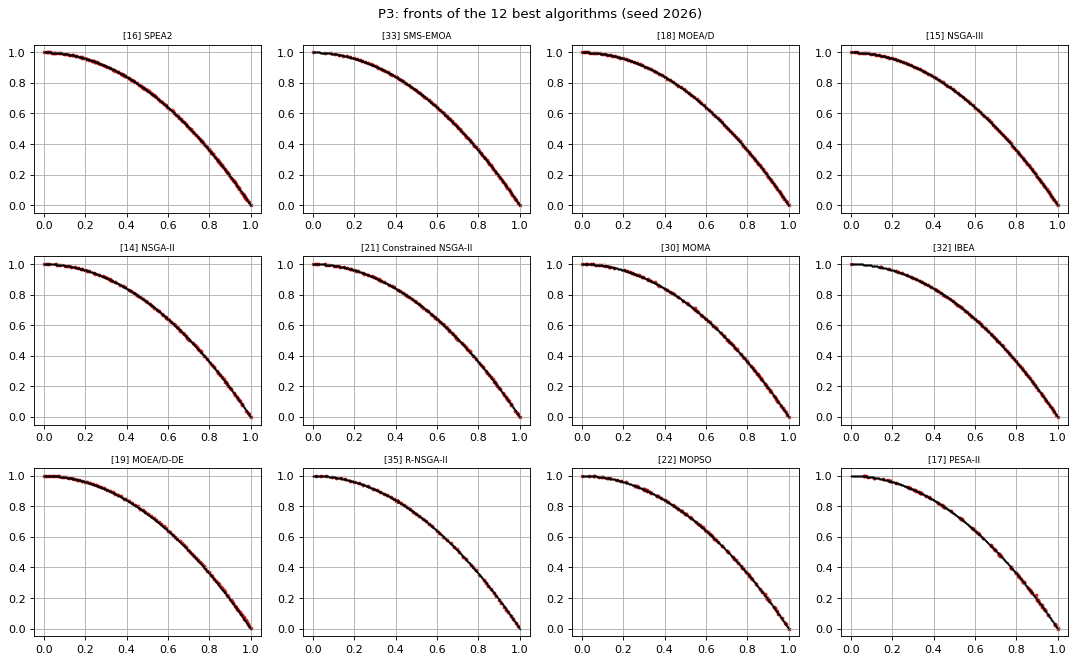

**Ranking on P5 (constrained), budget 10000, 10 seeds**

| Rank | # | Algorithm | HV (↑) | Spacing (↓) | IGD (↓) | Runtime |
|---|---|---|---|---|---|---|
| 1 | 33 | SMS-EMOA | 1.1956 ± 0.0000 | 0.0148 ± 0.0006 | 0.0062 ± 0.0002 | 11.6s |
| 2 | 16 | SPEA2 | 1.1954 ± 0.0001 | 0.0066 ± 0.0003 | 0.0040 ± 0.0002 | 4.4s |
| 3 | 30 | MOMA | 1.1948 ± 0.0006 | 0.0072 ± 0.0004 | 0.0067 ± 0.0015 | 0.4s |
| 4 | 14 | NSGA-II | 1.1947 ± 0.0002 | 0.0069 ± 0.0007 | 0.0069 ± 0.0006 | 0.4s |
| 5 | 21 | Constrained NSGA-II | 1.1947 ± 0.0002 | 0.0069 ± 0.0007 | 0.0069 ± 0.0006 | 0.5s |
| 6 | 35 | R-NSGA-II | 1.1948 ± 0.0002 | 0.0098 ± 0.0008 | 0.0072 ± 0.0003 | 2.6s |
| 7 | 24 | MOABC | 1.1946 ± 0.0001 | 0.0117 ± 0.0024 | 0.0073 ± 0.0004 | 0.6s |
| 8 | 26 | MOSA | 1.1947 ± 0.0001 | 0.0095 ± 0.0017 | 0.0074 ± 0.0004 | 0.7s |
| 9 | 22 | MOPSO | 1.1944 ± 0.0003 | 0.0088 ± 0.0007 | 0.0085 ± 0.0009 | 0.8s |
| 10 | 23 | MOGWO | 1.1928 ± 0.0009 | 0.0090 ± 0.0007 | 0.0113 ± 0.0020 | 0.6s |
| 11 | 17 | PESA-II | 1.1926 ± 0.0008 | 0.0089 ± 0.0007 | 0.0117 ± 0.0014 | 1.6s |
| 12 | 28 | MO-TLBO | 1.1933 ± 0.0008 | 0.0125 ± 0.0011 | 0.0125 ± 0.0015 | 0.3s |
| 13 | 29 | MOBA | 1.1935 ± 0.0005 | 0.0088 ± 0.0011 | 0.0140 ± 0.0021 | 0.8s |
| 14 | 12 | NSGA | 1.1927 ± 0.0009 | 0.0189 ± 0.0032 | 0.0153 ± 0.0026 | 0.2s |
| 15 | 19 | MOEA/D-DE | 1.1926 ± 0.0001 | 0.0818 ± 0.0031 | 0.0648 ± 0.0044 | 5.6s |
| 16 | 18 | MOEA/D | 1.1926 ± 0.0001 | 0.0829 ± 0.0006 | 0.0664 ± 0.0002 | 6.1s |
| 17 | 15 | NSGA-III | 1.1926 ± 0.0000 | 0.0831 ± 0.0003 | 0.0664 ± 0.0003 | 0.7s |
| 18 | 32 | IBEA | 1.1934 ± 0.0004 | 0.0295 ± 0.0130 | 0.1097 ± 0.0093 | 0.5s |
| 19 | 34 | HypE | 1.1917 ± 0.0009 | 0.0162 ± 0.0063 | 0.1092 ± 0.0291 | 6.2s |
| 20 | 11 | MOGA | 1.1914 ± 0.0012 | 0.0244 ± 0.0052 | 0.0173 ± 0.0027 | 0.2s |
| 21 | 31 | RVEA | 1.1906 ± 0.0010 | 0.0230 ± 0.0033 | 0.1797 ± 0.0129 | 0.2s |
| 22 | 27 | MODE | 1.1884 ± 0.0037 | 0.0405 ± 0.0228 | 0.0300 ± 0.0103 | 0.1s |
| 23 | 13 | NPGA | 1.1874 ± 0.0088 | 0.0429 ± 0.0206 | 0.0187 ± 0.0047 | 0.4s |
| 24 | 4 | Weight Metric (p-norm, Tchebycheff) | 1.1861 ± 0.0000 | 0.0735 ± 0.0000 | 0.1726 ± 0.0000 | 0.2s |
| 25 | 1 | Weighted Sum | 1.1728 ± 0.0000 | 0.3477 ± 0.0001 | 0.1370 ± 0.0000 | 0.2s |
| 26 | 3 | Benson's Method | 1.1593 ± 0.0159 | 0.0976 ± 0.0725 | 0.1171 ± 0.0241 | 0.1s |
| 27 | 10 | VEGA | 1.1504 ± 0.0084 | 0.0141 ± 0.0068 | 0.0802 ± 0.0243 | 0.0s |
| 28 | 2 | ε-Constraint | 1.1246 ± 0.0141 | 0.1174 ± 0.1141 | 0.0668 ± 0.0024 | 0.4s |


P5 done in 464s


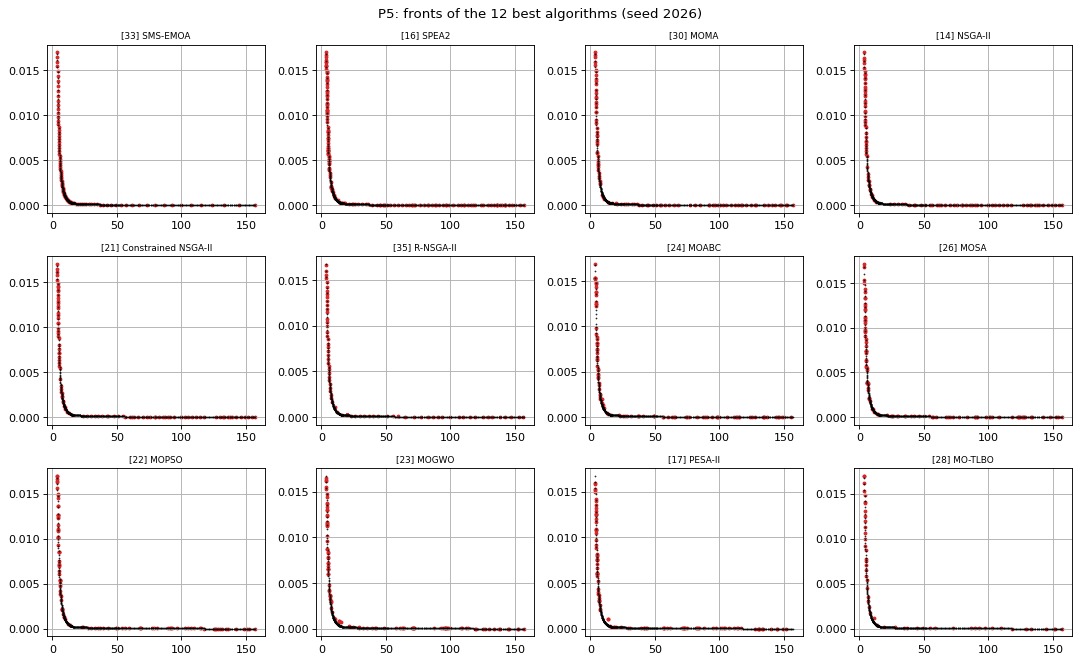

In [52]:
D1_IDS = [1, 2, 3, 4] + [i for i in range(10, 36) if i not in (20, 25)]
for pn in ("P3", "P5"):
    t0 = time.time()
    for i in D1_IDS: run_many(i, runner_for(i, pn), pn)
    rows = rtab(pn, D1_IDS, f"Ranking on {pn} ({'constrained' if pn == 'P5' else 'unconstrained'}), budget {BUDGET}, {RUNS} seeds"); print(f"{pn} done in {time.time() - t0:.0f}s")
    plot_fronts(pn, rows[:12], f"{pn}: fronts of the 12 best algorithms (seed {SEED0})")

**D1 explanation (write after reading the tables):** group the ranking by family — indicator/decomposition/elitist methods are expected on top on P3; the sweeps (1–4) are limited by their number of points; weighted sum should lose on P3 (non-convex); on P5 methods with feasibility rules (21) or penalties should return only feasible points; VEGA/NPGA/MOGA/NSGA should trail (non-elitist).

#### D2. Many-objective: P10 (M = 5) — NSGA-II, NSGA-III, MOEA/D, RVEA, HypE

**Ranking on P10 (M=5), budget 10000, 10 seeds**

| Rank | # | Algorithm | HV (↑) | Spacing (↓) | IGD (↓) | Runtime |
|---|---|---|---|---|---|---|
| 1 | 31 | RVEA | 1.2141 ± 0.0060 | 0.0504 ± 0.0025 | 0.2090 ± 0.0021 | 0.2s |
| 2 | 15 | NSGA-III | 1.1622 ± 0.0131 | 0.0725 ± 0.0054 | 0.2219 ± 0.0036 | 1.1s |
| 3 | 34 | HypE | 1.1489 ± 0.0100 | 0.1447 ± 0.0084 | 0.3449 ± 0.0104 | 7.4s |
| 4 | 18 | MOEA/D | 1.1425 ± 0.0064 | 0.1124 ± 0.0203 | 0.3411 ± 0.0088 | 7.8s |
| 5 | 14 | NSGA-II | 0.1233 ± 0.1076 | 0.1817 ± 0.0233 | 0.6099 ± 0.1149 | 0.5s |


P10_3: non-dominated share of 200 random points = 0.29
P10_5: non-dominated share of 200 random points = 0.54
NSGA-II final population on M=5: mean distance of its front to the true front (IGD) = 0.610 vs NSGA-III 0.222


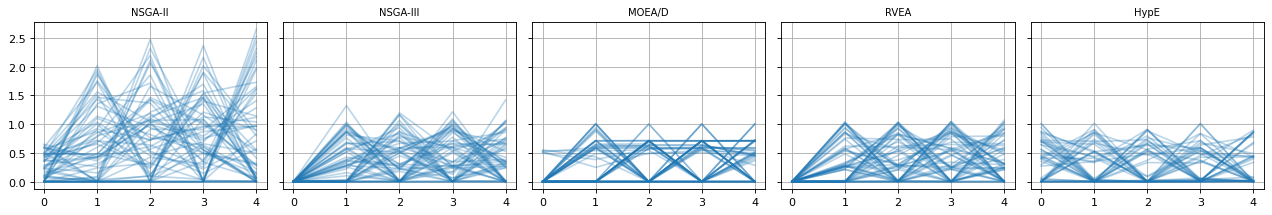

In [53]:
D2_IDS = [14, 15, 18, 31, 34]
for i in D2_IDS: run_many(i, cls_runner(CLS[i]), "P10_5")
rtab("P10_5", D2_IDS, f"Ranking on P10 (M=5), budget {BUDGET_MANY}, {RUNS} seeds")
# why NSGA-II degrades: share of non-dominated individuals in a random population and in the NSGA-II population
rr = np.random.default_rng(0)
for Pm in (P10_3, P10_5): Fr = Pm.f(Pm.init(rr, 200))[0]; print(f"{Pm.name}: non-dominated share of 200 random points = {len(nds(Fr)[0]) / 200:.2f}")
Fn5 = RES[("P10_5", 14)]["front"]; print("NSGA-II final population on M=5: mean distance of its front to the true front (IGD) =", f"{np.nanmean(RES[('P10_5', 14)]['igd']):.3f}",
                                        "vs NSGA-III", f"{np.nanmean(RES[('P10_5', 15)]['igd']):.3f}")
# parallel-coordinate view of the M=5 fronts
fig, axs = plt.subplots(1, 5, figsize=(16, 2.8), sharey=True)
for ax, i in zip(axs, D2_IDS):
    F = RES[("P10_5", i)]["front"]
    for f in F[:60]: ax.plot(range(5), f, c="C0", alpha=.3)
    ax.set_title(NAME[i], fontsize=9)
plt.tight_layout(); plt.show()

**What degrades NSGA-II:** with M = 5 almost every individual is non-dominated, so sorting stops discriminating and the crowding distance (sum of 1-D gaps) is dominated by boundary points and is a poor density measure in 5-D; selection pressure collapses and the population spreads without converging. NSGA-III/RVEA/MOEA/D replace it with reference points/vectors/weights that keep spread explicit; HypE keeps pressure through hypervolume credit.

#### D3. Discrete: P8 — MOEA/D-ACO, MOACO, NSGA-II and MOMA (permutation operators)

**Ranking on P8 (15-city bi-objective TSP), budget 10000, 10 seeds**

| Rank | # | Algorithm | HV (↑) | Spacing (↓) | IGD (↓) | Runtime |
|---|---|---|---|---|---|---|
| 1 | 30 | MOMA | 0.7557 ± 0.0009 | 0.1131 ± 0.0119 | - | 0.8s |
| 2 | 14 | NSGA-II | 0.7542 ± 0.0038 | 0.1097 ± 0.0247 | - | 1.0s |
| 3 | 25 | MOACO | 0.7166 ± 0.0336 | 0.1070 ± 0.0092 | - | 5.6s |
| 4 | 20 | MOEA/D-ACO | 0.6379 ± 0.1362 | 0.1223 ± 0.0339 | - | 7.3s |


Operators used by NSGA-II / MOMA on permutations: order crossover (OX) + segment-inversion mutation; MOMA adds inversion hill-climbing; ACO methods construct tours directly.


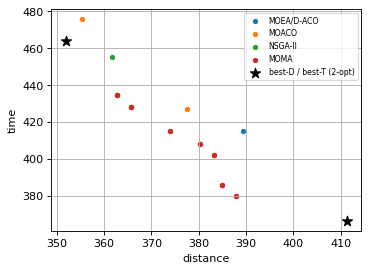

shortest-distance tour: [351.8 463.7] | shortest-time tour: [411.4 366.3]


In [54]:
D3_IDS = [20, 25, 14, 30]
for i in D3_IDS: run_many(i, cls_runner(CLS[i]), "P8")
rtab("P8", D3_IDS, f"Ranking on P8 (15-city bi-objective TSP), budget {BUDGET}, {RUNS} seeds")
print("Operators used by NSGA-II / MOMA on permutations: order crossover (OX) + segment-inversion mutation; MOMA adds inversion hill-climbing; ACO methods construct tours directly.")
fig, ax = plt.subplots(figsize=(5, 3.6))
for i in D3_IDS: R = P8.denorm(RES[("P8", i)]["front"]); ax.scatter(R[:, 0], R[:, 1], s=14, label=NAME[i])
ax.scatter(*np.array([[_e1[0], _e1[1]], [_e2[0], _e2[1]]]).T, c="k", marker="*", s=90, label="best-D / best-T (2-opt)"); ax.set_xlabel("distance"); ax.set_ylabel("time"); ax.legend(fontsize=7); plt.show()
print("shortest-distance tour:", _e1.round(1), "| shortest-time tour:", _e2.round(1))

#### D4. Methods without their own front (as specified in the PDF)
Algorithms 1–4 → swept (≥ 10 settings) in D1. Algorithms 5–7 → solutions and the inputs that produced them (printed in A2.5–A2.7, summarised here). Algorithms 8–9 → applied to the NSGA-II front below. Algorithms 36–37 → both task losses vs. fixed equal weights.

In [55]:
# --- 5-7: solution and the input that produced it ---
table([("5 Value Function", f"a = {a}", P4.f(value_function(P4, 0, (a,)))[0].round(4).tolist()) for a in (0.2, 0.5, 0.8)] +
      [("6 Goal Programming", f"targets (2400, 600), weights {w}", goal_programming(P11.lin, [2400, 600], w)[0].round(1).tolist()) for w in ([1, 1], [1 / 2400, 1 / 600])] +
      [("7 Lexicographic", f"priority {o}", lexicographic(P11.lin, o).round(1).tolist()) for o in ([0, 1], [1, 0])], ["Method", "Input", "Solution found"])
# --- 8-9: top-3 on the NSGA-II front of P5, then shift one weight by 0.1 ---
Fr5 = P5.denorm(RES[("P5", 14)]["front"]); Fr5 = Fr5[np.argsort(Fr5[:, 0])]; bn = np.array([False, False]); w_a, w_b = np.array([.5, .5]), np.array([.6, .4])
def top3(sc, hi): o = np.argsort(-sc if hi else sc)[:3]; return o.tolist()
rows = []
for nm, f_, hi in (("TOPSIS", lambda w: topsis(Fr5, w, bn), True), ("VIKOR v=0.5", lambda w: vikor(Fr5, w, bn, 0.5), False)):
    a, b_ = top3(f_(w_a), hi), top3(f_(w_b), hi); rows.append((nm, a, b_, "flips" if a != b_ else "stable"))
table(rows, ["Method", "Top-3 indices, w=(0.5,0.5)", "Top-3 indices, w=(0.6,0.4)", "Ranking"]); print("Top-1 designs (mass kg, deflection m):", Fr5[rows and top3(topsis(Fr5, w_a, bn), True)[0]].round(4).tolist())
# --- 36-37: both task losses against fixed equal weights ---
table([("Equal weights (fixed)", *hE[-1].round(3)), ("36 MGDA", *hM[-1].round(3)), ("37 GradNorm", *hG[-1].round(3))], ["Method", "classification loss", "regression loss"])
print("Regression gradients are ~20x larger: equal weights let that task dominate; MGDA/GradNorm rebalance by gradient scale (see A2.36-37 plots).")

| Method | Input | Solution found |
|---|---|---|
| 5 Value Function | a = 0.2 | [[0.0512, -0.1413]] |
| 5 Value Function | a = 0.5 | [[0.0301, -0.1317]] |
| 5 Value Function | a = 0.8 | [[0.0158, -0.118]] |
| 6 Goal Programming | targets (2400, 600), weights [1, 1] | [300.0, 200.0] |
| 6 Goal Programming | targets (2400, 600), weights [0.0004166666666666667, 0.0016666666666666668] | [300.0, 200.0] |
| 7 Lexicographic | priority [0, 1] | [300.0, 200.0] |
| 7 Lexicographic | priority [1, 0] | [300.0, 200.0] |


| Method | Top-3 indices, w=(0.5,0.5) | Top-3 indices, w=(0.6,0.4) | Ranking |
|---|---|---|---|
| TOPSIS | [47, 48, 46] | [46, 47, 45] | flips |
| VIKOR v=0.5 | [47, 48, 46] | [46, 47, 45] | flips |


Top-1 designs (mass kg, deflection m): [11.6825, 0.0006]


| Method | classification loss | regression loss |
|---|---|---|
| Equal weights (fixed) | 0.717 | 16.184 |
| 36 MGDA | 0.576 | 79.13 |
| 37 GradNorm | 0.665 | 44.984 |


Regression gradients are ~20x larger: equal weights let that task dominate; MGDA/GradNorm rebalance by gradient scale (see A2.36-37 plots).


### Task E — Algorithm selection reasoning
Six problems; for each: two suitable algorithms, one poor choice, justification, and evidence (auto-filled from Tasks A/D: HV mean). Covers a many-objective problem (P10) and constrained problems (P5, P11).

In [56]:
def ev(i, pn):
    if (pn, i) in RES: return f"HV {np.mean(RES[(pn, i)]['hv']):.3f}"
    r = [x for x in LOG if x["idx"] == i and x["prob"] == pn and not np.isnan(x["hv"])]
    return f"HV {r[0]['hv']:.3f}" if r else "design argument"
E = [("P3 ZDT2 (non-convex, 2 obj, continuous)", (14, 18), 1, "Pareto-based/decomposition handle the dent; Weighted Sum can only reach the end points (convexity)."),
     ("P5 beam (constrained, continuous)", (21, 16), 10, "Deb's rules need no penalty weight and keep feasible spread; VEGA has no constraint handling or diversity."),
     ("P8 TSP (discrete, 2 obj)", (20, 30), 22, "ACO builds valid tours and MOMA adds local search on permutations; MOPSO is continuous and needs relaxation."),
     ("P10 DTLZ2 M=5 (many-objective)", (15, 31), 14, "Reference points/vectors keep pressure when most points are non-dominated; NSGA-II crowding fails."),
     ("P11 production planning (linear goals, priorities)", (6, 7), 5, "LP-based goal/lexicographic solves are exact and cheap; a value function needs a utility nobody gave."),
     ("P14 laptop (DM reference point 1.8 kg, 12 h)", (35, 5), 3, "R-NSGA-II focuses on the preferred part of the front; Benson improves a start point but ignores the preference.")]
table([(p, f"{NAME[a]} ({ev(a, pn)}); {NAME[b]} ({ev(b, pn)})", f"{NAME[c]} ({ev(c, pn)})", why)
       for (p, (a, b), c, why), pn in zip(E, ["P3", "P5", "P8", "P10_5", "P11", "P14"])], ["Problem", "Two suitable (evidence)", "Poor choice (evidence)", "Justification (convexity / M / variables / constraints / preference / budget)"])

| Problem | Two suitable (evidence) | Poor choice (evidence) | Justification (convexity / M / variables / constraints / preference / budget) |
|---|---|---|---|
| P3 ZDT2 (non-convex, 2 obj, continuous) | NSGA-II (HV 0.537); MOEA/D (HV 0.538) | Weighted Sum (HV 0.210) | Pareto-based/decomposition handle the dent; Weighted Sum can only reach the end points (convexity). |
| P5 beam (constrained, continuous) | Constrained NSGA-II (HV 1.195); SPEA2 (HV 1.195) | VEGA (HV 1.150) | Deb's rules need no penalty weight and keep feasible spread; VEGA has no constraint handling or diversity. |
| P8 TSP (discrete, 2 obj) | MOEA/D-ACO (HV 0.638); MOMA (HV 0.756) | MOPSO (design argument) | ACO builds valid tours and MOMA adds local search on permutations; MOPSO is continuous and needs relaxation. |
| P10 DTLZ2 M=5 (many-objective) | NSGA-III (HV 1.162); RVEA (HV 1.214) | NSGA-II (HV 0.123) | Reference points/vectors keep pressure when most points are non-dominated; NSGA-II crowding fails. |
| P11 production planning (linear goals, priorities) | Goal Programming (HV 1.210); Lexicographic (HV 1.210) | Value Function (design argument) | LP-based goal/lexicographic solves are exact and cheap; a value function needs a utility nobody gave. |
| P14 laptop (DM reference point 1.8 kg, 12 h) | R-NSGA-II (HV 0.699); Value Function (HV 0.538) | Benson's Method (design argument) | R-NSGA-II focuses on the preferred part of the front; Benson improves a start point but ignores the preference. |


### Task F — Viva preparation: executable demonstrations
Short answers plus code that shows the behaviour (change one line and predict the effect).

**1. Why Weighted Sum can't reach the dent:** for a non-convex front the minimizer of `w·f` always lies on the convex hull of the front, so interior points are never optimal for any weight.
**2. VEGA collapses to the extremes:** each sub-population is selected by one objective only, so compromise solutions are never favoured (see demo).
**3. Elitism guarantees** that the best solutions found are never lost (hypervolume of the kept set cannot decrease): NSGA-II, SPEA2, PESA-II, MOEA/D(-DE), constrained NSGA-II, MOPSO/MOGWO/MOABC/MOBA/MOSA (archive), MOTLBO, MOMA, SMS-EMOA, HypE, IBEA, NSGA-III, RVEA (mostly); VEGA, MOGA, NSGA, NPGA have none.
**4. Crowding distance fails with many objectives** (almost everything is non-dominated; the 1-D gap sum is a poor density estimate); replaced by reference points/vectors or indicators.
**5. Preference needed:** 5 (utility), 6 (targets), 7 (priorities), 35 (reference point), 8–9 (weights), 1/4 (weights). A wrong preference gives a confident but irrelevant answer.
**6. Deb's rules:** feasible beats infeasible; both feasible → dominance; both infeasible → smaller violation (numerical example in the next cell).
**7. Premature convergence:** hypervolume plateau while the front is far from the true front, loss of spread, population variance → 0 (demo below).
**8. TOPSIS/VIKOR are not optimizers:** they rank a *given* finite set of alternatives; they generate no new solutions.

In [57]:
# Q1: weighted sum on ZDT2 keeps only the end points; Q2: VEGA vs NSGA-II spread on P3
Fw = finalize(P3, weighted_sum(P3, 0, 21)); print("Q1 weighted sum (21 weights) on ZDT2: f1 of the points found ->", np.sort(Fw[:, 0]).round(2))
Fv, Fn2 = RES[("P3", 10)]["front"], RES[("P3", 14)]["front"]; mid = lambda F: int(((F[:, 0] > .15) & (F[:, 0] < .85)).sum())
print(f"Q2 points in the middle of the front (0.15<f1<0.85): VEGA {mid(Fv)} of {len(Fv)}, NSGA-II {mid(Fn2)} of {len(Fn2)}")
# Q6: Deb's three rules on the four candidates (F, CV)
cand = np.array([[2., 2.], [1., 3.], [3., 1.], [1., 1.]]); cv = np.array([0., 0., 2., 0.5]); D = dom_matrix(cand, cv)
table([(f"{a} vs {b}", rule, "A wins" if D[a, b] else ("B wins" if D[b, a] else "tie")) for a, b, rule in
       [(0, 2, "feasible beats infeasible (F worse but CV=0)"), (0, 1, "both feasible: ordinary dominance -> incomparable"), (3, 2, "both infeasible: smaller CV (0.5<2) wins"), (0, 3, "feasible beats infeasible (3 has better F)")]],
      ["Pair", "Rule applied", "Result"])

Q1 weighted sum (21 weights) on ZDT2: f1 of the points found -> [0. 1. 1. 1. 1.]
Q2 points in the middle of the front (0.15<f1<0.85): VEGA 0 of 1, NSGA-II 67 of 100


| Pair | Rule applied | Result |
|---|---|---|
| 0 vs 2 | feasible beats infeasible (F worse but CV=0) | A wins |
| 0 vs 1 | both feasible: ordinary dominance -> incomparable | tie |
| 3 vs 2 | both infeasible: smaller CV (0.5<2) wins | A wins |
| 0 vs 3 | feasible beats infeasible (3 has better F) | A wins |


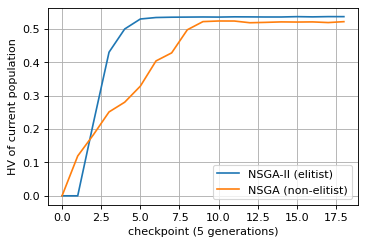

NSGA-II HV never decreases: False | NSGA decreased 4 times (no elitism)
plateau test (last 5 checkpoints improve < 1e-4): NSGA-II False | NSGA False


In [58]:
# Q3 / Q7: hypervolume history of an elitist (NSGA-II) vs a non-elitist (NSGA) algorithm; plateau = convergence/stagnation signal
def hv_curve(cls, P, budget, seed, every=5):
    a = cls(P, budget=budget, seed=seed); h = []
    while a.evals < budget:
        a.step(); a.gen += 1
        if a.gen % every == 0: Fcur = P.norm(P.f(a.dec(a.X))[0]); Fcur = Fcur[nds(Fcur)[0]]; h.append(hv(Fcur, P.ref))
    return np.array(h)
hN2, hN = hv_curve(NSGA2, P3, BUDGET, 1), hv_curve(NSGA, P3, BUDGET, 1)
fig, ax = plt.subplots(figsize=(5, 3.2)); ax.plot(hN2, label="NSGA-II (elitist)"); ax.plot(hN, label="NSGA (non-elitist)"); ax.set_xlabel("checkpoint (5 generations)"); ax.set_ylabel("HV of current population"); ax.legend(); plt.show()
dd = np.diff(hN); print(f"NSGA-II HV never decreases: {bool((np.diff(hN2) >= -1e-9).all())} | NSGA decreased {int((dd < -1e-9).sum())} times (no elitism)")
plateau = lambda h, k=5, tol=1e-4: len(h) > k and (h[-1] - h[-k] < tol); print("plateau test (last 5 checkpoints improve < 1e-4):", "NSGA-II", plateau(hN2), "| NSGA", plateau(hN))

### Final check and output
Everything above runs top-to-bottom. Set `FULL = True` (config cell) for the 10,000-evaluation / 10-seed protocol, `ROLL` for your deep dive, then re-run and export results/figures for the report. Seeds used: `SEED0 + run` (SEED0 = 2026).

In [59]:
# ---- Save raw results to CSV (required by Section 7) ----
import csv
os.makedirs("results", exist_ok=True)
with open("results/task_a_log.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["idx", "algorithm", "problem", "budget", "HV", "IGD", "Spacing", "runtime_s", "status"])
    for r in LOG: w.writerow([r["idx"], r["name"], r["prob"], r["budget"], r["hv"], r["igd"], r["sp"], round(r["rt"], 3), r["status"]])
with open("results/task_d_runs.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["problem", "idx", "algorithm", "seed", "HV", "IGD", "Spacing"])
    for (pn, i), r in RES.items():
        for k in range(len(r["hv"])): w.writerow([pn, i, NAME[i], SEED0 + k, r["hv"][k], r["igd"][k], r["sp"][k]])
print("saved results/task_a_log.csv and results/task_d_runs.csv")

saved results/task_a_log.csv and results/task_d_runs.csv


### Export — submission zips (run this cell LAST)
After every cell above has run, this cell reads the executed notebook (live Colab session, or an `.ipynb` path) and writes two zips, both in cell order:
- `lab7_codes.zip` — one numbered `.py` per code cell + `all_code_in_order.py`
- `lab7_outputs.zip` — printed text, tables and figures of every cell (numbered files) + `all_outputs_in_order.md` index

In [60]:
# EXPORT_CELL
import re, json, base64, zipfile, glob
NB_PATH = ""      # optional: path to an executed .ipynb; leave empty on Colab (the live notebook is read)

def load_executed_notebook(path=""):
    """Return the notebook JSON including outputs: from a file, from live Colab, or the newest .ipynb in the folder."""
    if path: return json.load(open(path))
    try:
        from google.colab import _message
        return _message.blocking_request("get_ipynb", request="", timeout_sec=600)["ipynb"]
    except Exception:
        found = sorted(glob.glob("*.ipynb"), key=os.path.getmtime)
        if found: print("Reading", found[-1]); return json.load(open(found[-1]))
        raise RuntimeError("Could not read the notebook: save it (File > Save) and set NB_PATH to the .ipynb path.")

def export_zips(nb, code_zip="lab7_codes.zip", out_zip="lab7_outputs.zip"):
    """Write the code zip and the output zip, numbering files by code-cell order and naming them after the nearest heading."""
    slug = lambda t: re.sub(r"[^A-Za-z0-9]+", "_", t).strip("_")[:70] or "cell"
    join = lambda x: "".join(x) if isinstance(x, list) else x
    ansi = re.compile(r"\x1b\[[0-9;]*m")
    head, n, allcode, index = "Intro", 0, [], []
    with zipfile.ZipFile(code_zip, "w", zipfile.ZIP_DEFLATED) as zc, zipfile.ZipFile(out_zip, "w", zipfile.ZIP_DEFLATED) as zo:
        for cell in nb["cells"]:
            src = join(cell["source"])
            if cell["cell_type"] == "markdown":                      # remember the latest heading for naming
                h = [l for l in src.splitlines() if re.match(r"#{1,6}\s", l)]
                if h: head = re.sub(r"[*`]", "", h[-1].lstrip("# ")).strip()      # last heading in the cell = most specific
                continue
            if cell["cell_type"] != "code" or "EXPORT_CELL" in src: continue
            n += 1; cm = re.match(r"#\s*-{2,}\s*(.*?)\s*-{2,}", src.lstrip()); label = f"{head} - {cm.group(1)}" if cm else head   # heading + the cell's own title comment
            base = f"{n:03d}_{slug(label)}"
            zc.writestr(base + ".py", f"# Cell {n}: {label}\n{src}\n")
            allcode.append(f"# {'=' * 70}\n# Cell {n}: {label}\n# {'=' * 70}\n{src}\n")
            index.append(f"\n## Cell {n} — {label}\n"); k, buf = 0, []
            def flush():                                              # write buffered stream text as one file
                nonlocal k, buf
                if buf and "".join(buf).strip():
                    k += 1; name = f"{base}_out{k:02d}.txt"; zo.writestr(name, "".join(buf)); index.append("```text\n" + "".join(buf).rstrip() + "\n```\n")
                buf = []
            for o in cell.get("outputs", []):
                t = o.get("output_type")
                if t == "stream": buf.append(join(o["text"])); continue
                flush(); d = o.get("data", {}); k += 1
                if t == "error": txt = ansi.sub("", "\n".join(o.get("traceback", [])) or o.get("evalue", "")); zo.writestr(f"{base}_out{k:02d}_error.txt", txt); index.append("```text\n" + txt + "\n```\n")
                elif "image/png" in d: name = f"{base}_out{k:02d}.png"; zo.writestr(name, base64.b64decode(join(d["image/png"]))); index.append(f"![{name}]({name})\n")
                elif "text/markdown" in d: zo.writestr(f"{base}_out{k:02d}.md", join(d["text/markdown"])); index.append(join(d["text/markdown"]) + "\n")
                elif "text/plain" in d: zo.writestr(f"{base}_out{k:02d}.txt", join(d["text/plain"])); index.append("```text\n" + join(d["text/plain"]) + "\n```\n")
                else: k -= 1
            flush()
        zc.writestr("all_code_in_order.py", "\n".join(allcode)); zo.writestr("all_outputs_in_order.md", "# Lab 7 — outputs in order\n" + "\n".join(index))
    print(f"{n} code cells -> {code_zip}, {out_zip}"); return code_zip, out_zip

zips = export_zips(load_executed_notebook(NB_PATH))
try:
    from google.colab import files
    for z in zips: files.download(z)                                  # triggers the browser download on Colab
except ImportError: print("Saved in the current folder:", zips)

59 code cells -> lab7_codes.zip, lab7_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>